# 1. Division de Grupos

## 1.1 Introducción

Para el inicio del analisis del dataset, decidimos separar las variables por su apartado dentro de la encuesta. Estos apartados estan separados por dos principales:
    'Bloque Hogar y Ubicación' : BH
    'Bloque Individual' : BI

Esta división permitio dividir y reducir el ruido, proveniente de la gran cantidad de variables en un solo dataframe.

In [1]:
import pandas as pd

raw_data = pd.read_csv('ENFR 2018 - Base usuario.txt', sep = '|')

raw_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 29224 entries, 0 to 29223
Columns: 287 entries, id to wf3p
dtypes: float64(186), int64(101)
memory usage: 64.0 MB


El dataframe tenía un total de 287 variables (incluyendo el id y los tres coeficientes de ponderación [wf1][wf2][wf3]) y tenía casi 30 mil registros.

Para facilitar el análisis hicimos una función que genere un histograma, un boxplot u ambos, dandole como input su dataset, titulo y las etiquetas. 

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

COLOR = "#4C72B0"


def graficar_variable(serie, titulo, tipo="continua", etiquetas=None, nsnc=()):
    """Grafica una variable de la encuesta con el formato estándar del informe.

    Las numéricas ("continua" o "discreta") llevan un histograma con media y mediana y, debajo, un boxplot
    con el mismo eje. Las categóricas codificadas ("categorica") llevan barras con el porcentaje de cada
    categoría, porque un boxplot sobre códigos no tiene sentido. `etiquetas` traduce cada código a su nombre
    según el diccionario y `nsnc` lista los códigos de Ns/Nc (por ejemplo 99) que se descartan.
    """
    datos = serie.replace(list(nsnc), float("nan")).dropna()
    subtitulo = f"n = {len(datos):,} | sin dato = {len(serie) - len(datos):,}"
    if tipo == "categorica":
        _graficar_categorica(datos, titulo, subtitulo, etiquetas)
    else:
        _graficar_numerica(datos, titulo, subtitulo, discreta=(tipo == "discreta"))


def _graficar_numerica(datos, titulo, subtitulo, discreta):
    """Histograma arriba y boxplot abajo, compartiendo el eje x para que se lean juntos."""
    fig, (ax_h, ax_b) = plt.subplots(2, 1, figsize=(10, 5), sharex=True,
                                     gridspec_kw={"height_ratios": [4, 1]})
    if discreta:
        sns.histplot(datos, discrete=True, color=COLOR, ax=ax_h)
    else:
        sns.histplot(datos, bins=40, kde=True, color=COLOR, ax=ax_h)
    ax_h.axvline(datos.mean(), color="red", ls="--", lw=1.2, label=f"Media = {datos.mean():,.1f}")
    ax_h.axvline(datos.median(), color="black", ls=":", lw=1.2, label=f"Mediana = {datos.median():,.1f}")
    ax_h.set_ylabel("Frecuencia")
    ax_h.legend(frameon=False)
    ax_h.set_title(f"{titulo}\n{subtitulo}", loc="left")

    sns.boxplot(x=datos, color=COLOR, width=0.5, flierprops={"markersize": 3, "alpha": 0.4}, ax=ax_b)
    ax_b.set_xlabel(titulo)
    _estilo(ax_h, "y")
    _estilo(ax_b, "x")
    plt.tight_layout()
    plt.show()


def _graficar_categorica(datos, titulo, subtitulo, etiquetas):
    """Barras horizontales con el porcentaje de cada categoría, en el orden de los códigos del diccionario."""
    conteo = datos.value_counts().sort_index()
    if etiquetas:
        conteo.index = conteo.index.map(etiquetas)
    porcentaje = conteo / conteo.sum() * 100

    fig, ax = plt.subplots(figsize=(10, 0.4 * len(conteo) + 1.5))
    barras = ax.barh(porcentaje.index.astype(str), porcentaje.values, color=COLOR)
    ax.bar_label(barras, labels=[f"{p:.1f}% ({c:,})" for p, c in zip(porcentaje, conteo)],
                 padding=3, fontsize=9)
    ax.invert_yaxis()
    ax.set_xlim(0, porcentaje.max() * 1.25)
    ax.set_xlabel("Porcentaje de casos (%)")
    ax.set_title(f"{titulo}\n{subtitulo}", loc="left")
    _estilo(ax, "x")
    plt.tight_layout()
    plt.show()


def _estilo(ax, eje_grilla):
    """Estilo común: sin bordes superior y derecho, y grilla suave solo en el eje de los valores."""
    sns.despine(ax=ax)
    ax.grid(axis=eje_grilla, ls="--", alpha=0.4)
    ax.set_axisbelow(True)

## 1.2 Bloque Hogar y Ubicación

### 1.2.1 Identificacion y Ubicacion

In [3]:
columnas = [
    "id",
    "cod_provincia",
    "region",
    "tamanio_aglomerado",
    "aglomerado",
    "localidades_150",
    "submuestra",
]
df_id_ub = raw_data[columnas].copy()
df_id_ub.head()

,id,cod_provincia,region,tamanio_aglomerado,aglomerado,localidades_150,submuestra
0,1128639,2,1,1,1,1,1
1,1709939,2,1,1,1,1,0
2,6874130,2,1,1,1,1,0
3,10319375,2,1,1,1,1,1
4,11140857,2,1,1,1,1,0


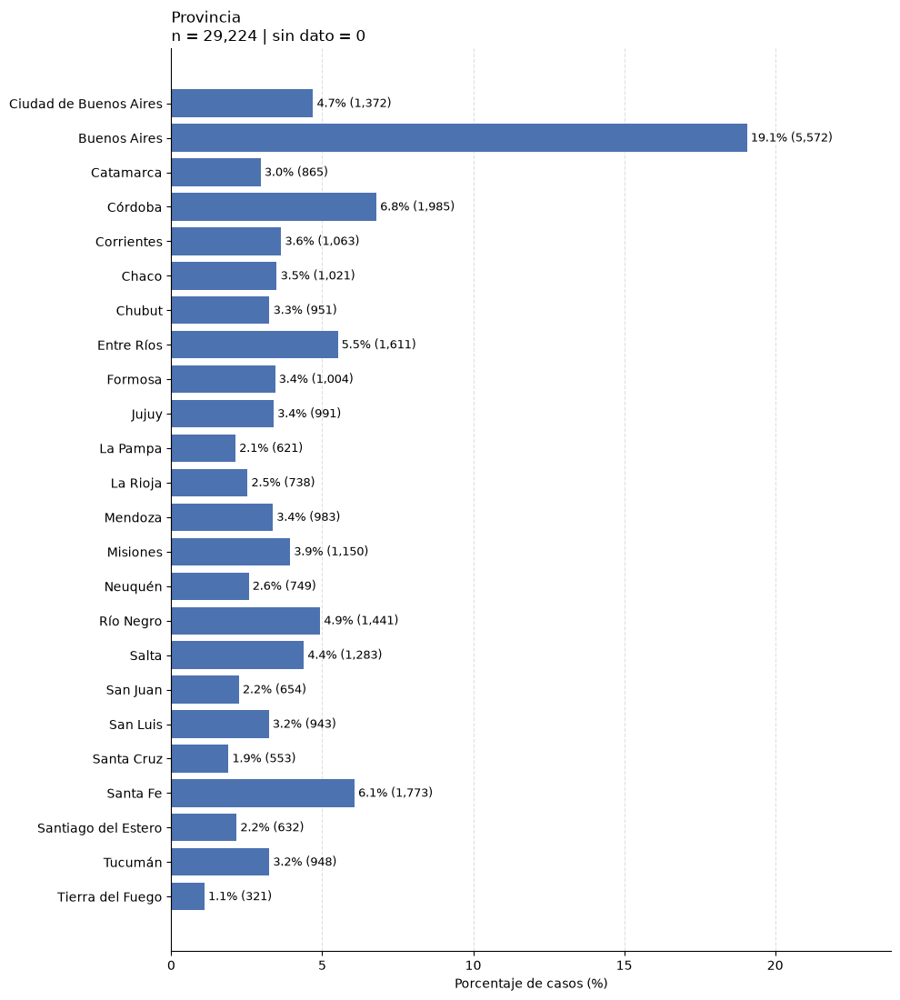

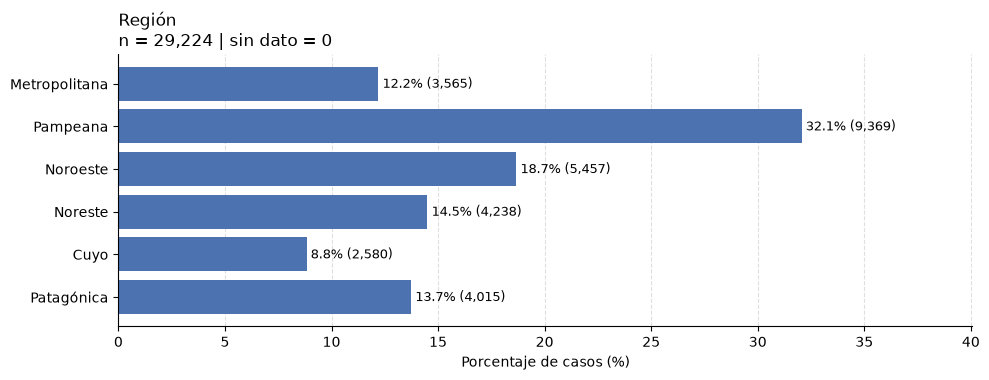

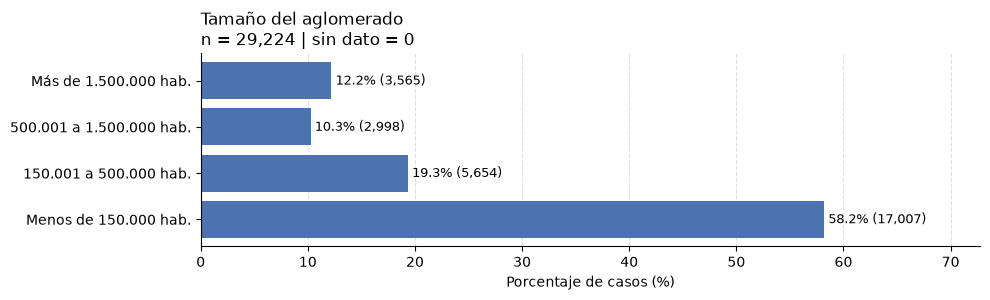

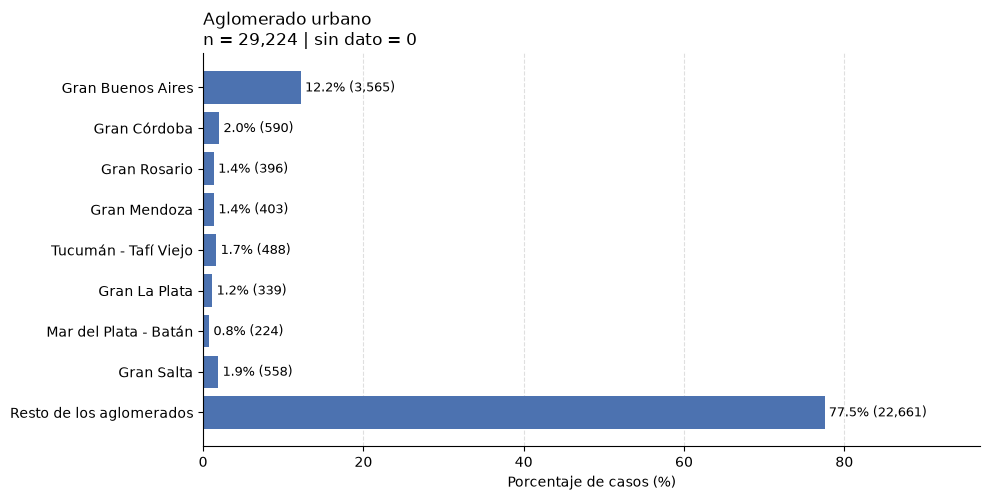

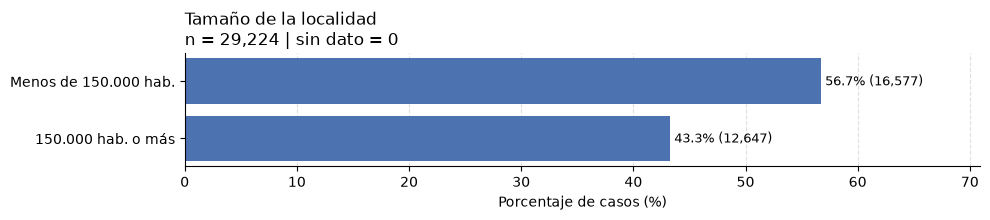

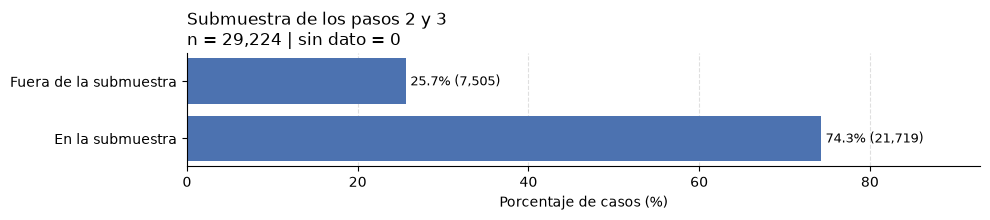

In [4]:

provincias = {
    2: "Ciudad de Buenos Aires",    6: "Buenos Aires", 
    10: "Catamarca",                14: "Córdoba",
    18: "Corrientes",               22: "Chaco", 
    26: "Chubut",                   30: "Entre Ríos", 
    34: "Formosa",                  38: "Jujuy", 
    42: "La Pampa",                 46: "La Rioja", 
    50: "Mendoza",                  54: "Misiones",
    58: "Neuquén",                  62: "Río Negro", 
    66: "Salta",                    70: "San Juan", 
    74: "San Luis",                 78: "Santa Cruz", 
    82: "Santa Fe",                 86: "Santiago del Estero", 
    90: "Tucumán",                  94: "Tierra del Fuego",
}

regiones = {1: "Metropolitana",  2: "Pampeana", 
            3: "Noroeste",       4: "Noreste",
            5: "Cuyo",           6: "Patagónica"
}

aglomerados = {1: "Más de 1.500.000 hab.",  2: "500.001 a 1.500.000 hab.",
               3: "150.001 a 500.000 hab.", 4: "Menos de 150.000 hab."
}

variables_121 = {
    "cod_provincia": ("Provincia", provincias),
    "region": ("Región", regiones),
    "tamanio_aglomerado": ("Tamaño del aglomerado", aglomerados),
    "aglomerado": ("Aglomerado urbano", {1: "Gran Buenos Aires", 2: "Gran Córdoba", 3: "Gran Rosario",
                                         4: "Gran Mendoza", 5: "Tucumán - Tafí Viejo", 6: "Gran La Plata",
                                         7: "Mar del Plata - Batán", 8: "Gran Salta",
                                         9: "Resto de los aglomerados"}),
    "localidades_150": ("Tamaño de la localidad", {1: "150.000 hab. o más", 0: "Menos de 150.000 hab."}),
    "submuestra": ("Submuestra de los pasos 2 y 3", {1: "En la submuestra", 0: "Fuera de la submuestra"}),
}

for col, (titulo, etiquetas) in variables_121.items():
    graficar_variable(df_id_ub[col], titulo, tipo="categorica", etiquetas=etiquetas)

### 1.2.2 Vivienda

In [5]:
columnas = [
    "id",
    "bhcv01",
    "bhcv02",
    "bhcv03",
    "bhcv04",
    "bhcv05",
    "bhcv06",
    "bhcv07",
    "bhcv08",
    "bhcv09",
    "bhcv10",
    "bhcv11",
]
df_vivienda = raw_data[columnas].copy()
df_vivienda.head()

,id,bhcv01,bhcv02,bhcv03,bhcv04,bhcv05,bhcv06,bhcv07,bhcv08,bhcv09,bhcv10,bhcv11
0,1128639,3,2,1,2,1,1,1,1,1,1.0,1.0
1,1709939,1,4,1,2,1,1,1,1,1,1.0,1.0
2,6874130,3,2,1,2,1,1,1,1,1,1.0,1.0
3,10319375,3,1,1,2,1,4,1,1,1,1.0,1.0
4,11140857,3,3,1,2,1,1,1,1,1,1.0,1.0


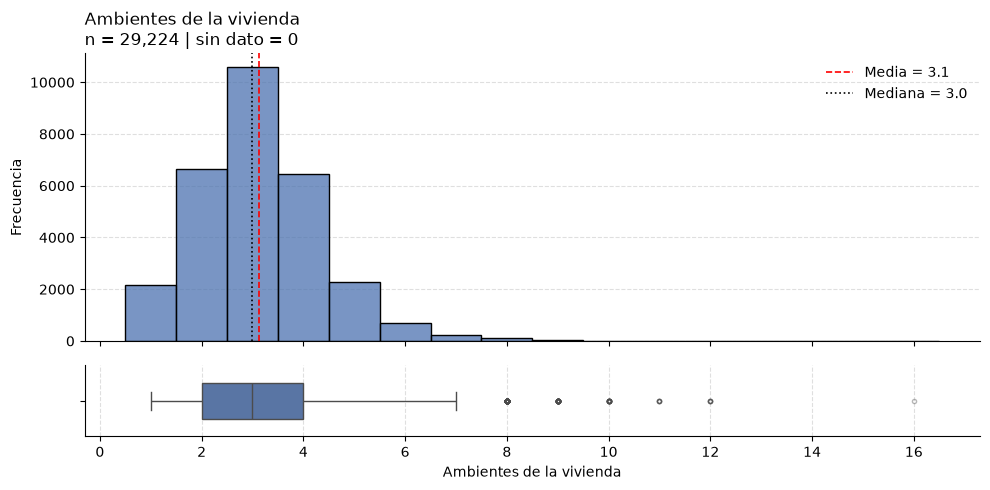

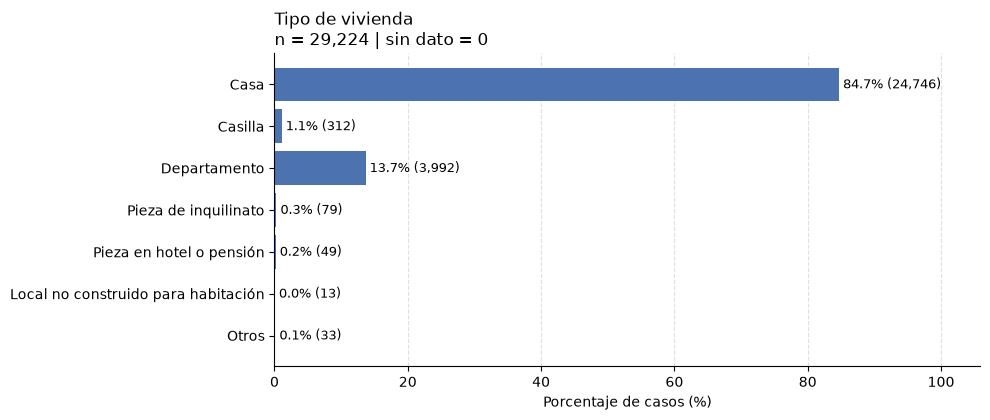

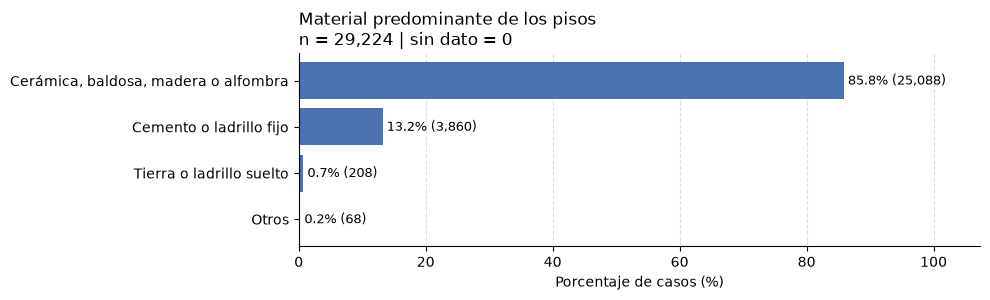

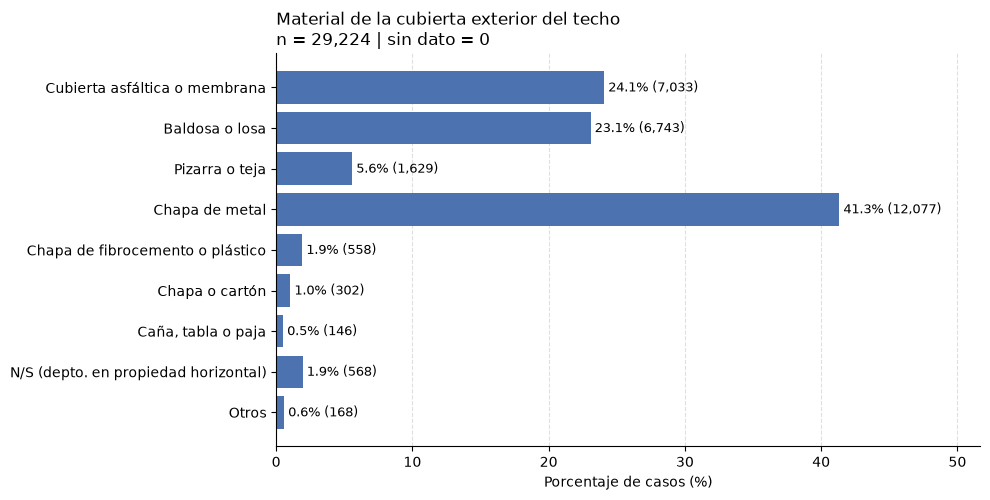

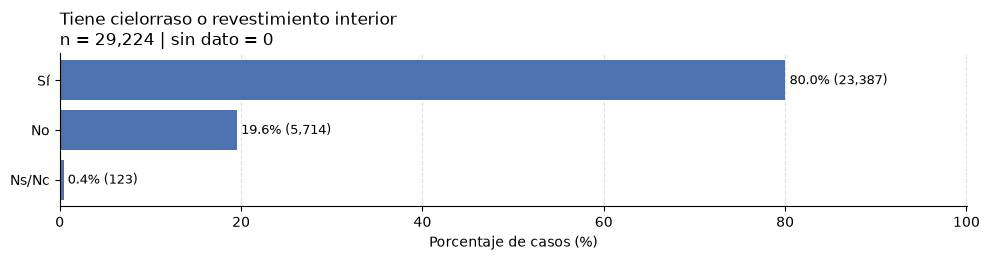

...

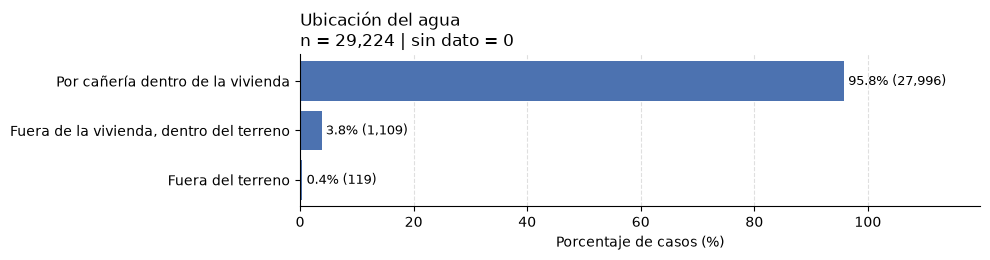

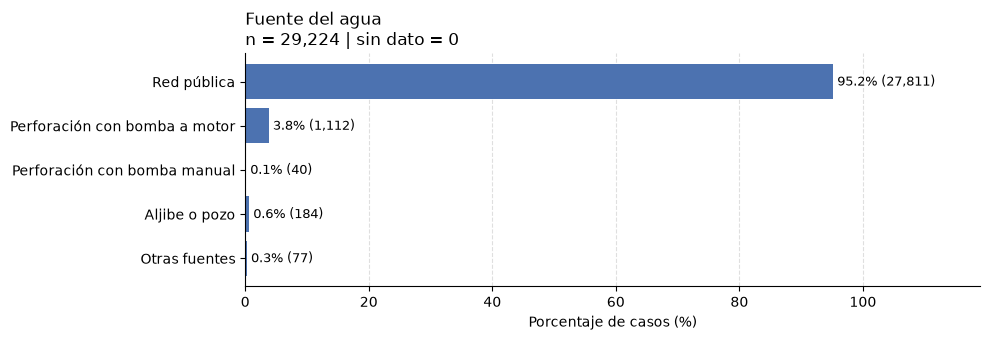

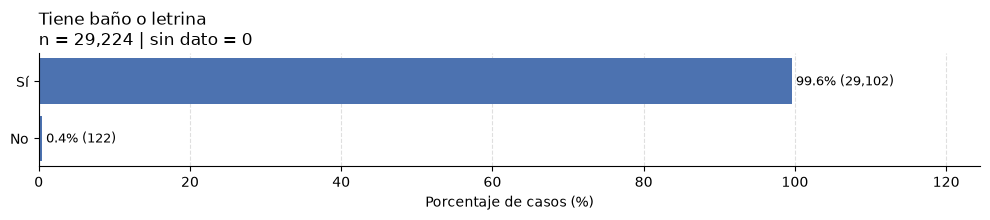

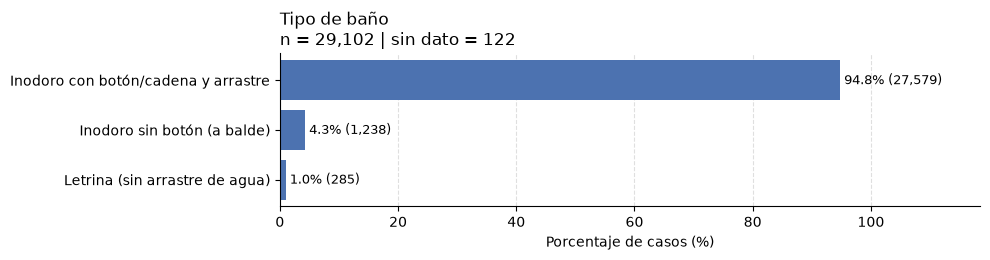

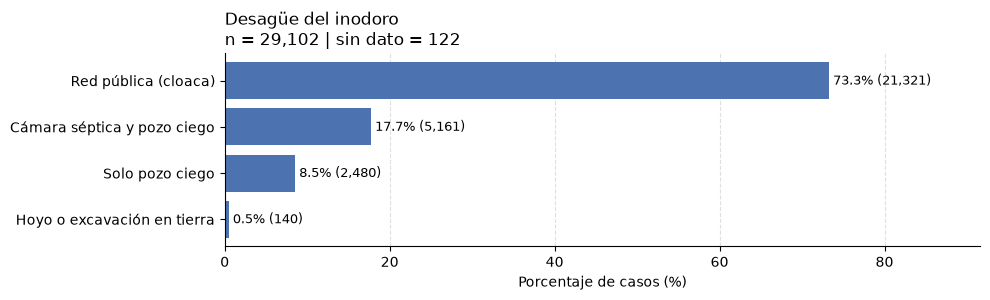

In [6]:
si_no = {1: "Sí", 2: "No"}
si_no_nsnc = {1: "Sí", 2: "No", 99: "Ns/Nc"}

tipos_vivienda = {1: "Casa",                      2: "Casilla",
                  3: "Departamento",              4: "Pieza de inquilinato",
                  5: "Pieza en hotel o pensión",  6: "Local no construido para habitación",
                  7: "Otros"
}

pisos = {1: "Cerámica, baldosa, madera o alfombra",  2: "Cemento o ladrillo fijo",
         3: "Tierra o ladrillo suelto",              4: "Otros"
}

techos = {1: "Cubierta asfáltica o membrana",     2: "Baldosa o losa",
          3: "Pizarra o teja",                    4: "Chapa de metal",
          5: "Chapa de fibrocemento o plástico",  6: "Chapa o cartón",
          7: "Caña, tabla o paja",                8: "N/S (depto. en propiedad horizontal)",
          9: "Otros"
}

combustibles = {1: "Gas de red",            2: "Gas de tubo/garrafa",
                3: "Kerosene/leña/carbón",  4: "Otro"
}

ubicaciones_agua = {1: "Por cañería dentro de la vivienda",  2: "Fuera de la vivienda, dentro del terreno",
                    3: "Fuera del terreno"
}

fuentes_agua = {1: "Red pública",                    2: "Perforación con bomba a motor",
                3: "Perforación con bomba manual",   4: "Aljibe o pozo",
                5: "Otras fuentes"
}

banios = {1: "Inodoro con botón/cadena y arrastre",  2: "Inodoro sin botón (a balde)",
          3: "Letrina (sin arrastre de agua)"
}

desagues = {1: "Red pública (cloaca)",  2: "Cámara séptica y pozo ciego",
            3: "Solo pozo ciego",       4: "Hoyo o excavación en tierra"
}

variables_122 = {
    "bhcv01": ("Tipo de vivienda", tipos_vivienda),
    "bhcv03": ("Material predominante de los pisos", pisos),
    "bhcv04": ("Material de la cubierta exterior del techo", techos),
    "bhcv05": ("Tiene cielorraso o revestimiento interior", si_no_nsnc),
    "bhcv06": ("Combustible para cocinar", combustibles),
    "bhcv07": ("Ubicación del agua", ubicaciones_agua),
    "bhcv08": ("Fuente del agua", fuentes_agua),
    "bhcv09": ("Tiene baño o letrina", si_no),
    "bhcv10": ("Tipo de baño", banios),
    "bhcv11": ("Desagüe del inodoro", desagues),
}

graficar_variable(df_vivienda["bhcv02"], "Ambientes de la vivienda", tipo="discreta")

for col, (titulo, etiquetas) in variables_122.items():
    graficar_variable(df_vivienda[col], titulo, tipo="categorica", etiquetas=etiquetas)

### 1.2.3 Hogar

In [7]:
columnas = [
    "id",
    "bhho01",
    "bhho02",
    "bhho03",
    "tipo_hogar",
]
df_hogar = raw_data[columnas].copy()
df_hogar.head()

,id,bhho01,bhho02,bhho03,tipo_hogar
0,1128639,1.0,2,1,2
1,1709939,1.0,4,3,4
2,6874130,1.0,2,1,2
3,10319375,1.0,1,1,1
4,11140857,1.0,3,2,8


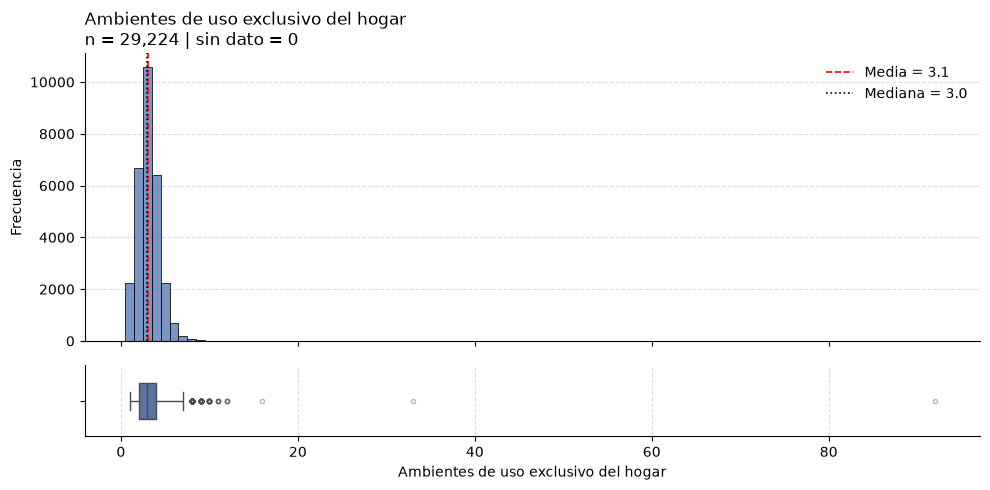

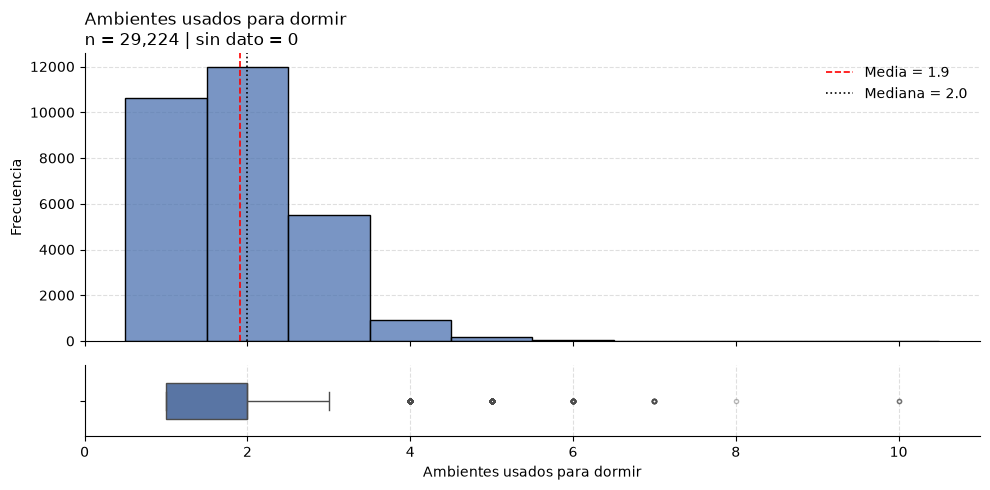

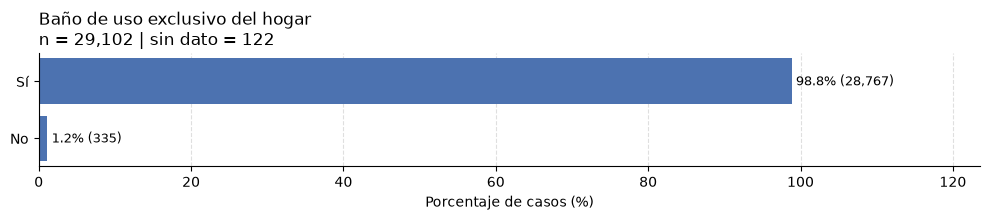

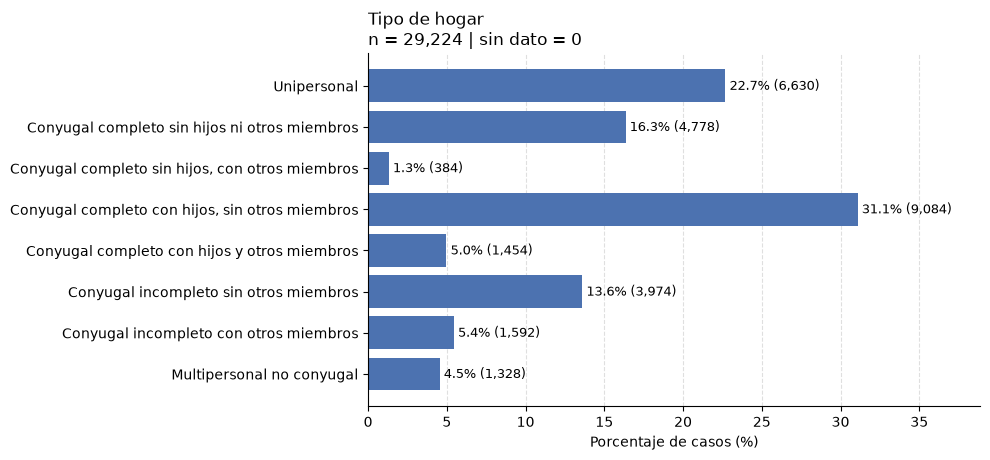

In [8]:
tipos_hogar = {1: "Unipersonal",
               2: "Conyugal completo sin hijos ni otros miembros",
               3: "Conyugal completo sin hijos, con otros miembros",
               4: "Conyugal completo con hijos, sin otros miembros",
               5: "Conyugal completo con hijos y otros miembros",
               6: "Conyugal incompleto sin otros miembros",
               7: "Conyugal incompleto con otros miembros",
               8: "Multipersonal no conyugal"
}

variables_123 = {
    "bhho01": ("Baño de uso exclusivo del hogar", si_no),
    "tipo_hogar": ("Tipo de hogar", tipos_hogar),
}

graficar_variable(df_hogar["bhho02"], "Ambientes de uso exclusivo del hogar", tipo="discreta")
graficar_variable(df_hogar["bhho03"], "Ambientes usados para dormir", tipo="discreta")

for col, (titulo, etiquetas) in variables_123.items():
    graficar_variable(df_hogar[col], titulo, tipo="categorica", etiquetas=etiquetas)

### 1.2.4 Ingresos

In [9]:
columnas = [
    "id",
    "bhih01",
    "bhih01_02",
    "bhih03",
    "rango_ingreso",
    "quintil_uc",
    "imputado",
]
df_ingresos = raw_data[columnas].copy()
df_ingresos.head()

,id,bhih01,bhih01_02,bhih03,rango_ingreso,quintil_uc,imputado
0,1128639,50000,NaN,2,NaN,5,NaN
1,1709939,40000,99.0,2,99.0,5,1.0
2,6874130,40000,99.0,2,12.0,5,1.0
3,10319375,80000,NaN,2,NaN,5,NaN
4,11140857,30000,99.0,2,9.0,5,1.0


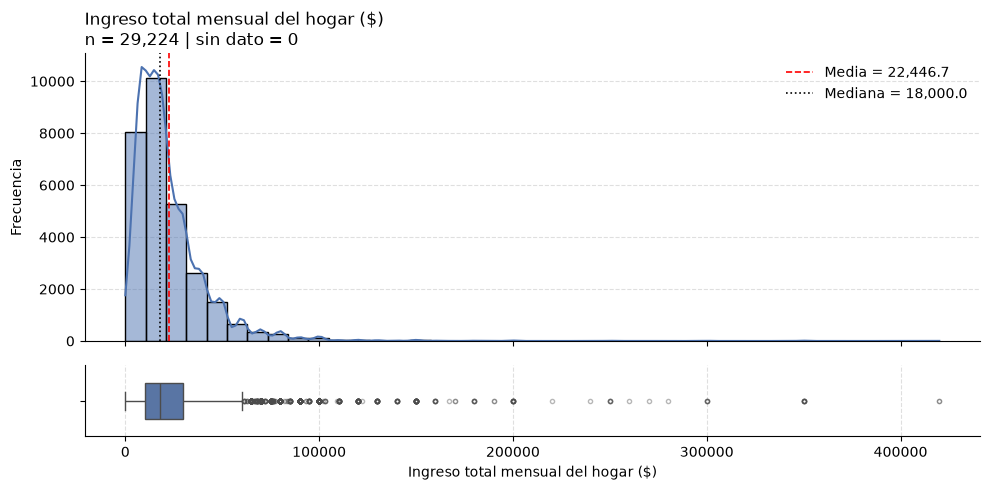

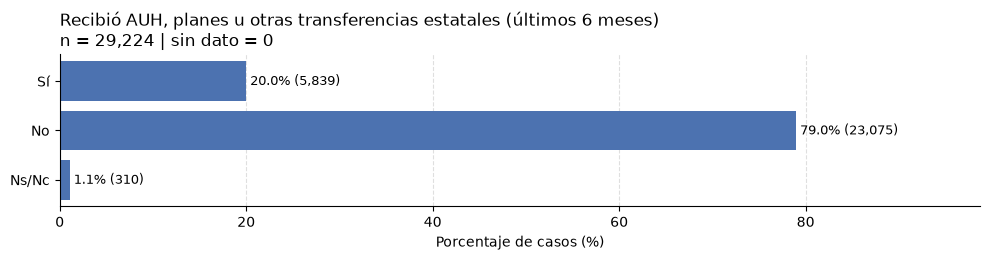

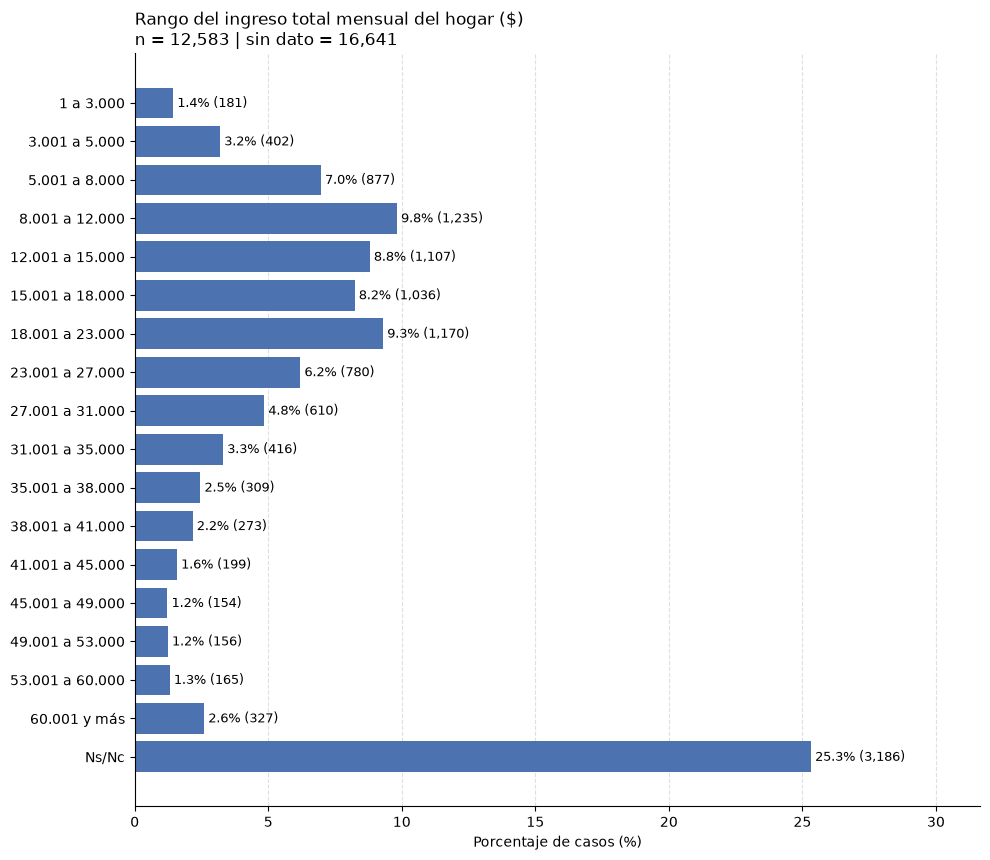

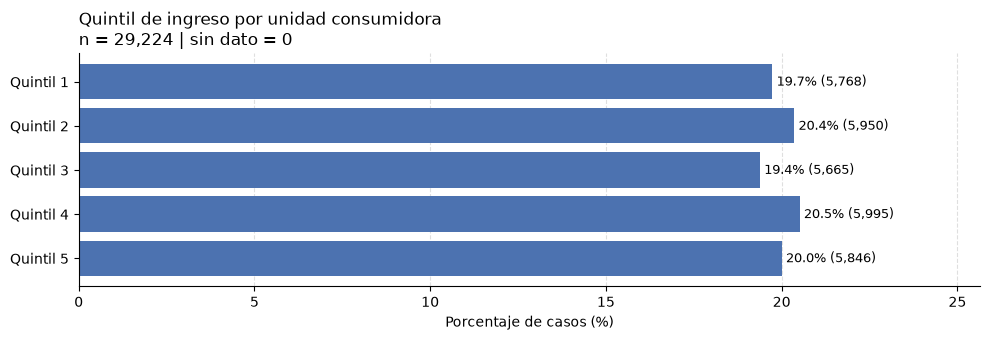

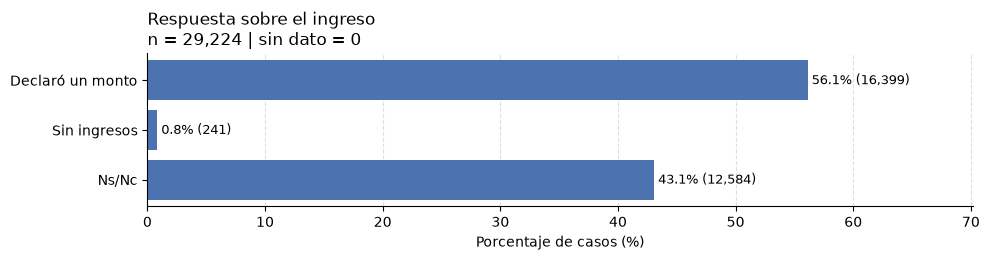

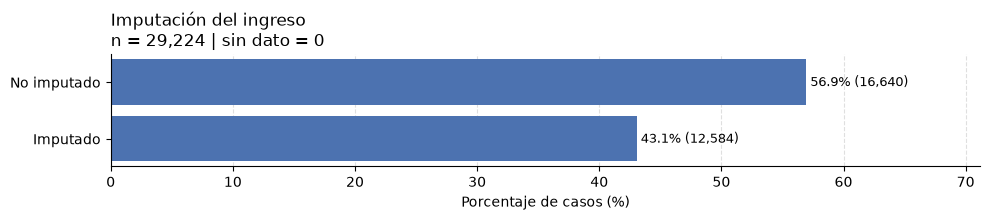

In [10]:
rangos_ingreso = {0: "Sin ingresos",        1: "1 a 3.000",
                  2: "3.001 a 5.000",       3: "5.001 a 8.000",
                  4: "8.001 a 12.000",      5: "12.001 a 15.000",
                  6: "15.001 a 18.000",     7: "18.001 a 23.000",
                  8: "23.001 a 27.000",     9: "27.001 a 31.000",
                  10: "31.001 a 35.000",    11: "35.001 a 38.000",
                  12: "38.001 a 41.000",    13: "41.001 a 45.000",
                  14: "45.001 a 49.000",    15: "49.001 a 53.000",
                  16: "53.001 a 60.000",    17: "60.001 y más",
                  99: "Ns/Nc"
}

quintiles = {1: "Quintil 1",  2: "Quintil 2",
             3: "Quintil 3",  4: "Quintil 4",
             5: "Quintil 5"
}

respuestas_ingreso = {1: "Declaró un monto",  2: "Sin ingresos",
                      99: "Ns/Nc"
}

imputaciones = {1: "Imputado",  0: "No imputado"}

# rango_ingreso solo se pregunta a quienes no declararon un monto exacto: sus vacíos son quienes sí lo declararon
variables_124 = {
    "bhih03": ("Recibió AUH, planes u otras transferencias estatales (últimos 6 meses)", si_no_nsnc),
    "rango_ingreso": ("Rango del ingreso total mensual del hogar ($)", rangos_ingreso),
    "quintil_uc": ("Quintil de ingreso por unidad consumidora", quintiles),
}

graficar_variable(df_ingresos["bhih01"], "Ingreso total mensual del hogar ($)", tipo="continua")

for col, (titulo, etiquetas) in variables_124.items():
    graficar_variable(df_ingresos[col], titulo, tipo="categorica", etiquetas=etiquetas)

# En estas dos columnas el vacío no es un faltante: significa "declaró un monto" y "no imputado"
graficar_variable(df_ingresos["bhih01_02"].fillna(1), "Respuesta sobre el ingreso", tipo="categorica",
                  etiquetas=respuestas_ingreso)
graficar_variable(df_ingresos["imputado"].fillna(0), "Imputación del ingreso", tipo="categorica",
                  etiquetas=imputaciones)

### 1.2.5 Componentes

In [11]:
columnas = [
    "id",
    "bhch03_j",
    "bhch04_j",
    "bhch05_j",
    "bhch10_01_j",
    "bhch10_02_j",
    "bhch10_03_j",
    "bhch10_04_j",
    "bhch10_05_j",
    "bhch10_06_j",
    "bhch10_99_j",
    "bhch02",
    "bhch03",
    "bhch04",
    "bhch05",
    "bhch10_01",
    "bhch10_02",
    "bhch10_03",
    "bhch10_04",
    "bhch10_05",
    "bhch10_06",
    "bhch10_99",
    "cant_componentes",
    "miembros_18",
    "rango_edad_j",
    "nivel_instruccion_j",
    "nivel_instruccion_agrupado_j",
    "cobertura_salud_j",
]
df_componentes = raw_data[columnas].copy()
df_componentes.head()

,id,bhch03_j,bhch04_j,bhch05_j,bhch10_01_j,bhch10_02_j,bhch10_03_j,bhch10_04_j,bhch10_05_j,bhch10_06_j,...,bhch10_04,bhch10_05,bhch10_06,bhch10_99,cant_componentes,miembros_18,rango_edad_j,nivel_instruccion_j,nivel_instruccion_agrupado_j,cobertura_salud_j
0,1128639,2,28,6,NaN,NaN,1.0,NaN,NaN,NaN,...,NaN,NaN,1.0,NaN,2,2,2,7,3,1
1,1709939,1,54,2,NaN,1.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,3,3,4,7,3,1
2,6874130,1,41,6,NaN,NaN,1.0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,2,2,3,7,3,1
3,10319375,2,64,3,1.0,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,1,1,4,7,3,1
4,11140857,1,25,6,NaN,NaN,NaN,NaN,NaN,1.0,...,NaN,NaN,NaN,NaN,2,2,2,6,3,2


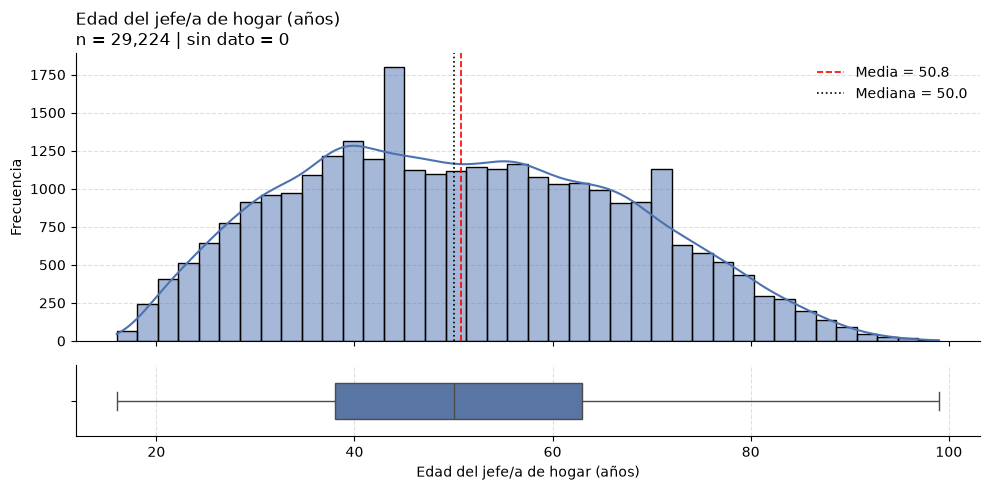

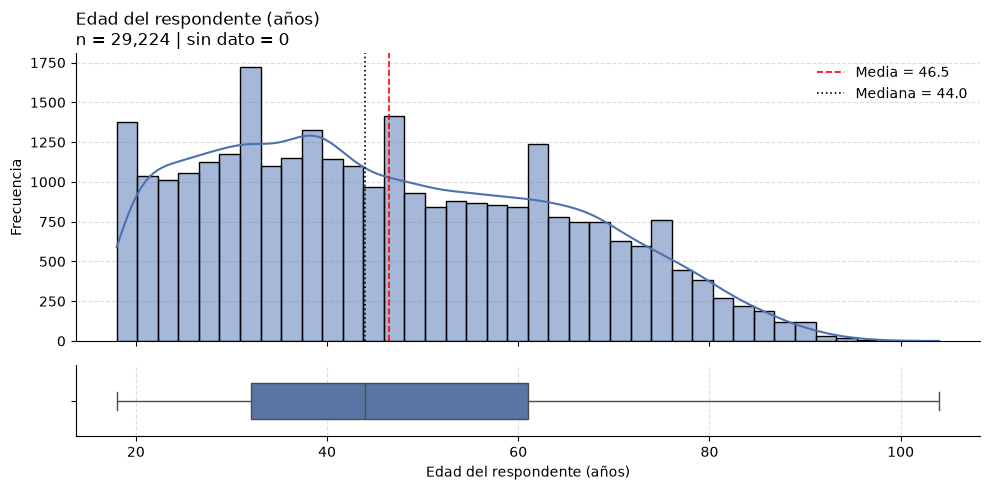

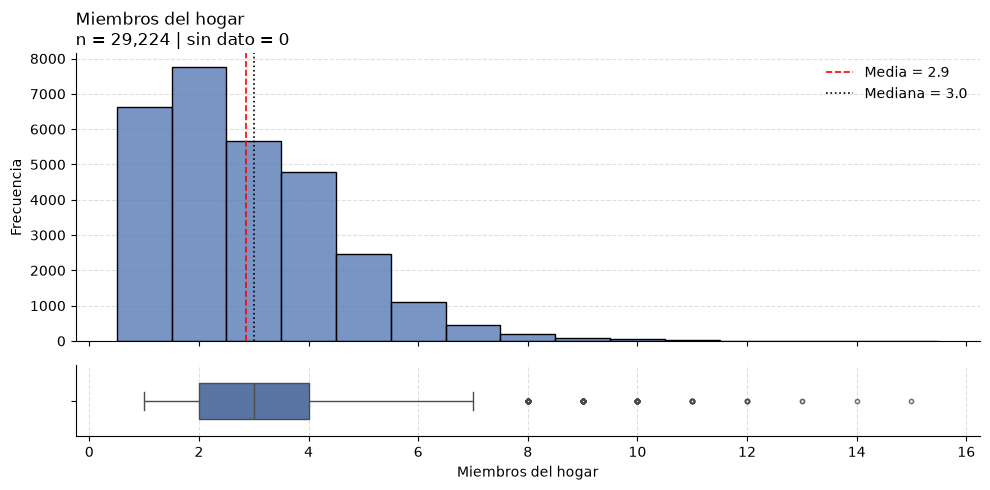

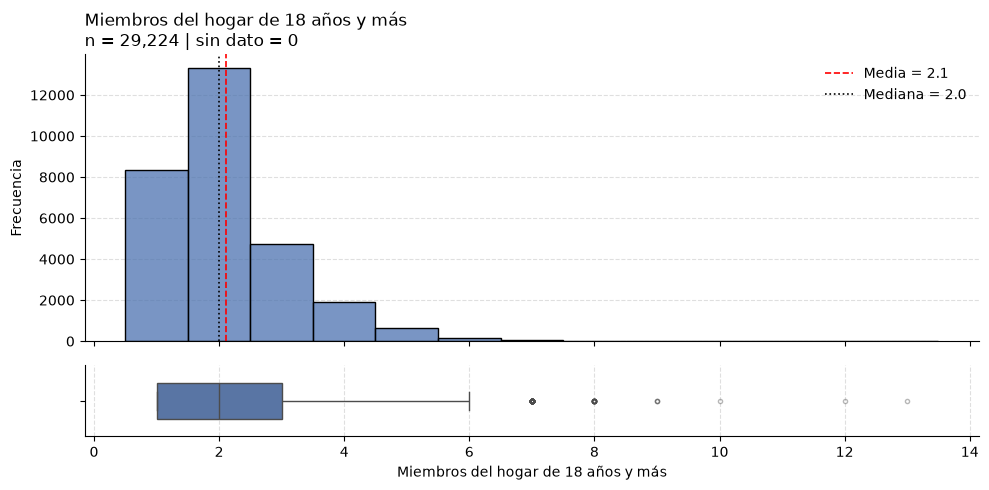

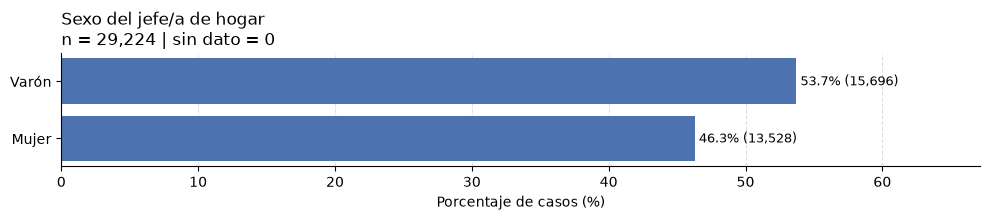

...

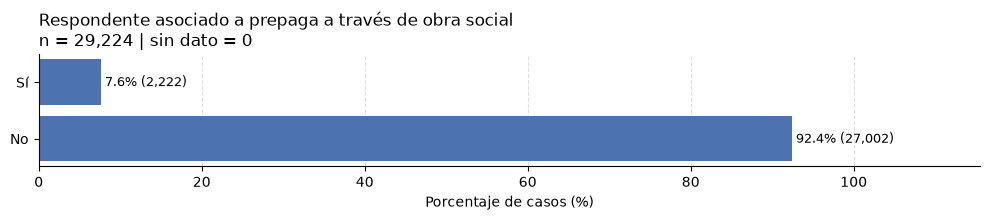

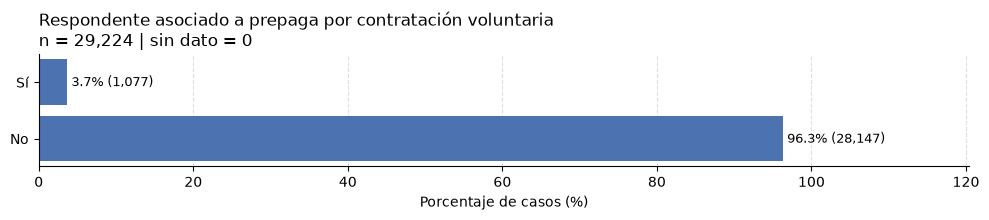

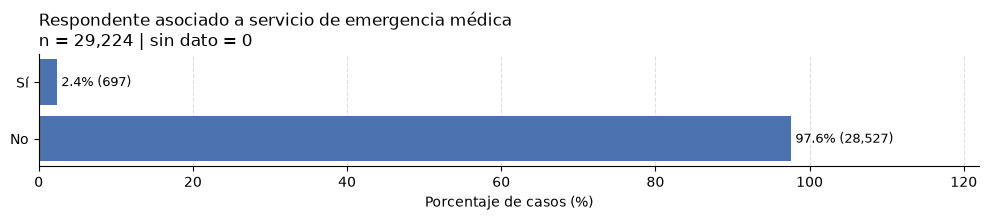

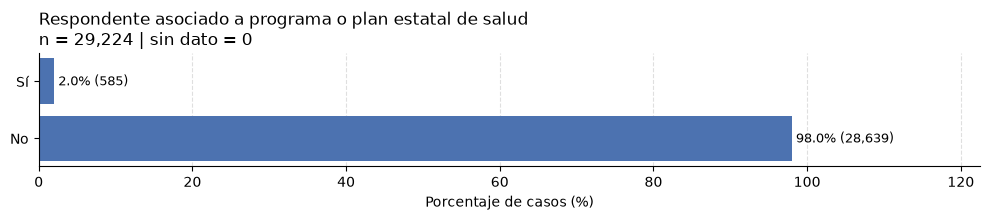

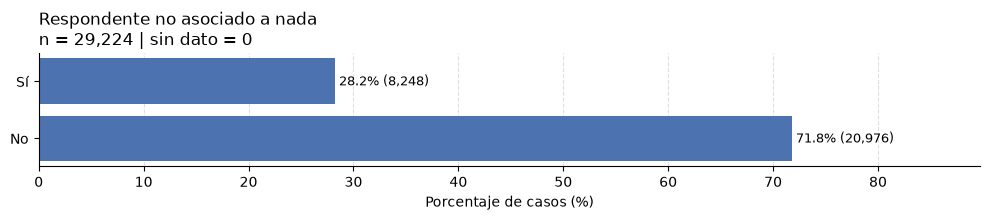

In [12]:
sexos = {1: "Varón",  2: "Mujer"}

situaciones_conyugales = {1: "Unido/a",     2: "Casado/a",
                          3: "Separado/a",  4: "Divorciado/a",
                          5: "Viudo/a",     6: "Soltero/a"
}

parentescos = {1: "Jefe/a de hogar",     2: "Cónyuge/pareja",
               3: "Hijo/a, hijastro/a",  4: "Padre/madre",
               5: "Hermano/a",           6: "Suegro/a",
               7: "Yerno/nuera",         8: "Nieto/a",
               9: "Otro familiar",       10: "Otro no familiar"
}

rangos_edad = {0: "0 a 17 años",   1: "18 a 24 años",
               2: "25 a 34 años",  3: "35 a 49 años",
               4: "50 a 64 años",  5: "65 años y más"
}

niveles_instruccion = {1: "Sin instrucción",                  2: "Primario incompleto",
                       3: "Primario completo",                4: "Secundario incompleto",
                       5: "Secundario completo",              6: "Terciario/universitario incompleto",
                       7: "Terciario/universitario completo", 8: "Educación especial"
}

niveles_agrupados = {1: "Hasta primario incompleto",  2: "Primario completo y secundario incompleto",
                     3: "Secundario completo y más",  4: "Educación especial"
}

coberturas = {1: "Obra social o prepaga",  2: "Sólo cobertura pública"}

variables_125 = {
    "bhch03_j": ("Sexo del jefe/a de hogar", sexos),
    "bhch05_j": ("Situación conyugal del jefe/a de hogar", situaciones_conyugales),
    "rango_edad_j": ("Rango de edad del jefe/a de hogar", rangos_edad),
    "nivel_instruccion_j": ("Nivel de instrucción del jefe/a de hogar", niveles_instruccion),
    "nivel_instruccion_agrupado_j": ("Nivel de instrucción agrupado del jefe/a de hogar", niveles_agrupados),
    "cobertura_salud_j": ("Cobertura de salud del jefe/a de hogar", coberturas),
    "bhch02": ("Parentesco del respondente con el jefe/a", parentescos),
    "bhch03": ("Sexo del respondente", sexos),
    "bhch05": ("Situación conyugal del respondente", situaciones_conyugales),
}

asociaciones_salud = {
    "bhch10_01_j": "Jefe/a asociado a obra social (incluye PAMI)",
    "bhch10_02_j": "Jefe/a asociado a prepaga a través de obra social",
    "bhch10_03_j": "Jefe/a asociado a prepaga por contratación voluntaria",
    "bhch10_04_j": "Jefe/a asociado a servicio de emergencia médica",
    "bhch10_05_j": "Jefe/a asociado a programa o plan estatal de salud",
    "bhch10_06_j": "Jefe/a no asociado a nada",
    "bhch10_01": "Respondente asociado a obra social (incluye PAMI)",
    "bhch10_02": "Respondente asociado a prepaga a través de obra social",
    "bhch10_03": "Respondente asociado a prepaga por contratación voluntaria",
    "bhch10_04": "Respondente asociado a servicio de emergencia médica",
    "bhch10_05": "Respondente asociado a programa o plan estatal de salud",
    "bhch10_06": "Respondente no asociado a nada",
}

graficar_variable(df_componentes["bhch04_j"], "Edad del jefe/a de hogar (años)", tipo="continua")
graficar_variable(df_componentes["bhch04"], "Edad del respondente (años)", tipo="continua")
graficar_variable(df_componentes["cant_componentes"], "Miembros del hogar", tipo="discreta")
graficar_variable(df_componentes["miembros_18"], "Miembros del hogar de 18 años y más", tipo="discreta")

for col, (titulo, etiquetas) in variables_125.items():
    graficar_variable(df_componentes[col], titulo, tipo="categorica", etiquetas=etiquetas)

# Son opciones de respuesta múltiple: vienen en 1 si se marcó la opción y vacías si no, así que el vacío es "No"
for col, titulo in asociaciones_salud.items():
    graficar_variable(df_componentes[col].fillna(2), titulo, tipo="categorica", etiquetas=si_no)

### 1.2.6 Situacion Laboral

In [13]:
columnas = [
    "id",
    "bhsl01",
    "bhsl02",
    "bhsl03",
    "bhsl04",
    "bhsl05",
    "bhsl06",
    "condicion_actividad_j",
]
df_sit_laboral = raw_data[columnas].copy()
df_sit_laboral.head()

,id,bhsl01,bhsl02,bhsl03,bhsl04,bhsl05,bhsl06,condicion_actividad_j
0,1128639,1,NaN,NaN,NaN,NaN,1.0,1
1,1709939,1,NaN,NaN,NaN,NaN,2.0,1
2,6874130,1,NaN,NaN,NaN,NaN,2.0,1
3,10319375,1,NaN,NaN,NaN,NaN,3.0,1
4,11140857,1,NaN,NaN,NaN,NaN,2.0,1


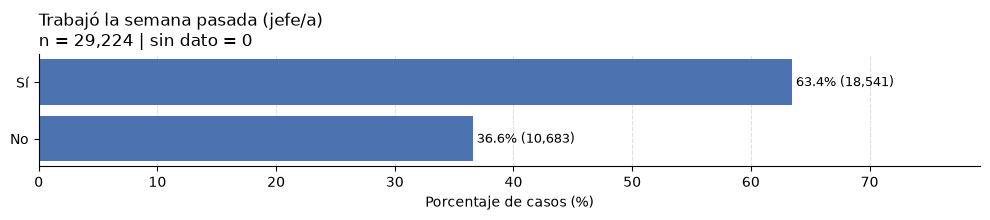

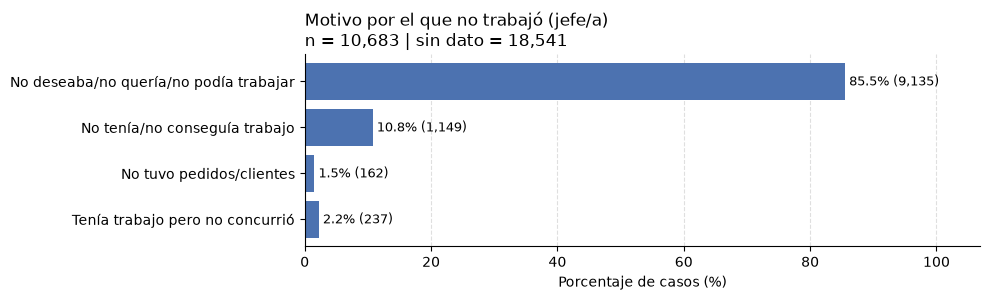

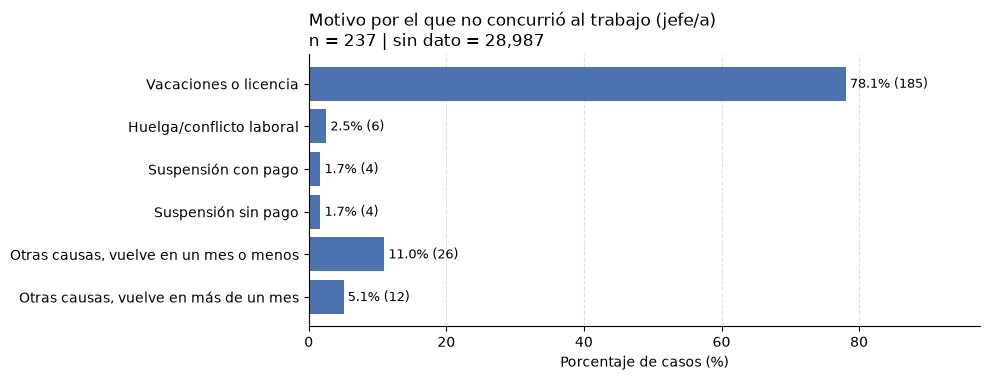

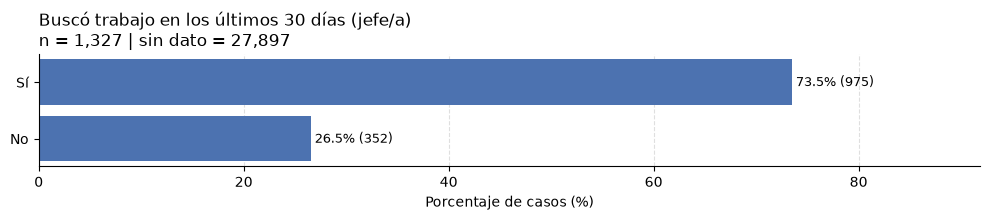

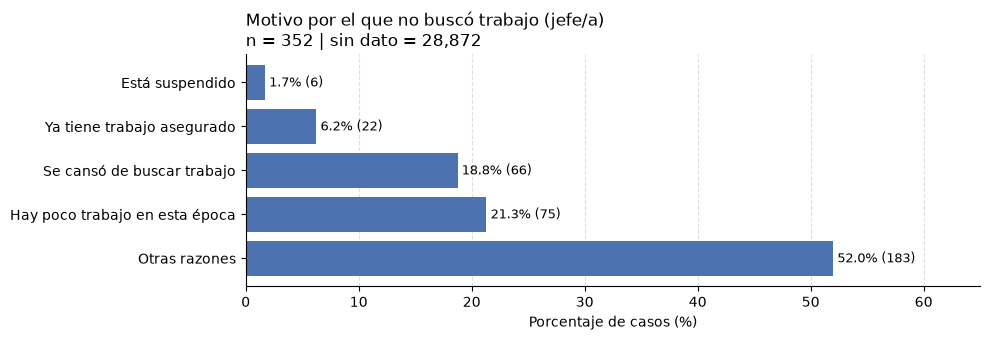

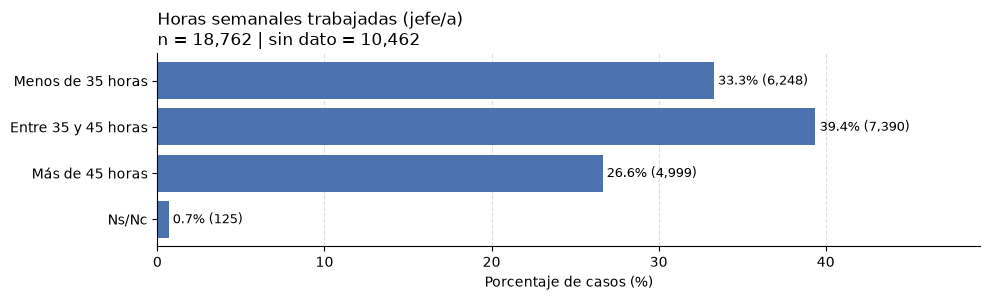

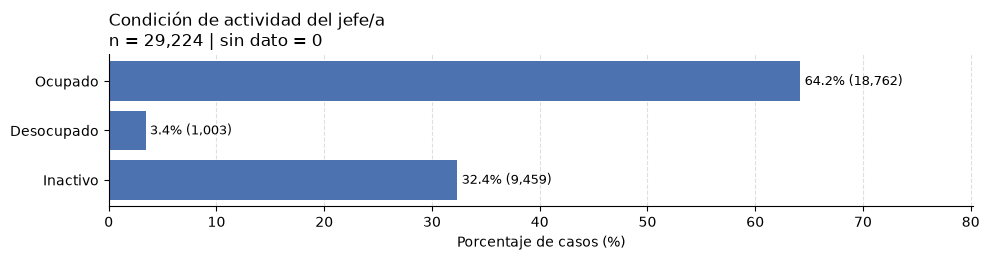

In [14]:
motivos_no_trabajo = {1: "No deseaba/no quería/no podía trabajar",  2: "No tenía/no conseguía trabajo",
                      3: "No tuvo pedidos/clientes",                 4: "Tenía trabajo pero no concurrió"
}

motivos_ausencia = {1: "Vacaciones o licencia",                 2: "Huelga/conflicto laboral",
                    3: "Suspensión con pago",                   4: "Suspensión sin pago",
                    5: "Otras causas, vuelve en un mes o menos", 6: "Otras causas, vuelve en más de un mes"
}

motivos_no_busqueda = {1: "Está suspendido",                 2: "Ya tiene trabajo asegurado",
                       3: "Se cansó de buscar trabajo",      4: "Hay poco trabajo en esta época",
                       5: "Otras razones"
}

horas_semanales = {1: "Menos de 35 horas",     2: "Entre 35 y 45 horas",
                   3: "Más de 45 horas",       99: "Ns/Nc"
}

condiciones_actividad = {1: "Ocupado",  2: "Desocupado",
                         3: "Inactivo"
}

variables_126 = {
    "bhsl01": ("Trabajó la semana pasada (jefe/a)", si_no),
    "bhsl02": ("Motivo por el que no trabajó (jefe/a)", motivos_no_trabajo),
    "bhsl03": ("Motivo por el que no concurrió al trabajo (jefe/a)", motivos_ausencia),
    "bhsl04": ("Buscó trabajo en los últimos 30 días (jefe/a)", si_no),
    "bhsl05": ("Motivo por el que no buscó trabajo (jefe/a)", motivos_no_busqueda),
    "bhsl06": ("Horas semanales trabajadas (jefe/a)", horas_semanales),
    "condicion_actividad_j": ("Condición de actividad del jefe/a", condiciones_actividad),
}

for col, (titulo, etiquetas) in variables_126.items():
    graficar_variable(df_sit_laboral[col], titulo, tipo="categorica", etiquetas=etiquetas)

## 1.3 Bloque Individual

### 1.3.1 Datos sociodemográficos del individuo seleccionado (CH / BI)

In [15]:
columnas = [
    "id",
    "bhch02",
    "bhch03",
    "bhch04",
    "bhch05",
    "rango_edad",
    "nivel_instruccion",
    "nivel_instruccion_agrupado",
    "bhch10_01",
    "bhch10_02",
    "bhch10_03",
    "bhch10_04",
    "bhch10_05",
    "bhch10_06",
    "bhch10_99",
    "cobertura_salud"
]

raw_data_sociodemografico = raw_data[columnas]
raw_data_sociodemografico.info()

<class 'pandas.DataFrame'>
RangeIndex: 29224 entries, 0 to 29223
Data columns (total 16 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   id                          29224 non-null  int64  
 1   bhch02                      29224 non-null  int64  
 2   bhch03                      29224 non-null  int64  
 3   bhch04                      29224 non-null  int64  
 4   bhch05                      29224 non-null  int64  
 5   rango_edad                  29224 non-null  int64  
 6   nivel_instruccion           29224 non-null  int64  
 7   nivel_instruccion_agrupado  29224 non-null  int64  
 8   bhch10_01                   17395 non-null  float64
 9   bhch10_02                   2222 non-null   float64
 10  bhch10_03                   1077 non-null   float64
 11  bhch10_04                   697 non-null    float64
 12  bhch10_05                   585 non-null    float64
 13  bhch10_06                   8248 non-null 

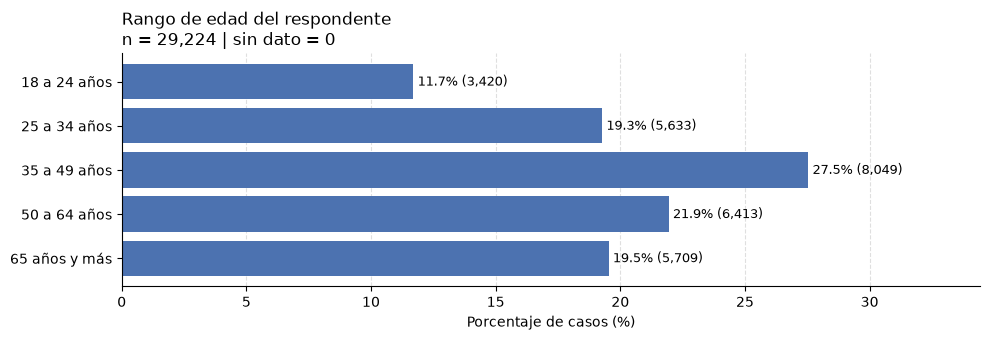

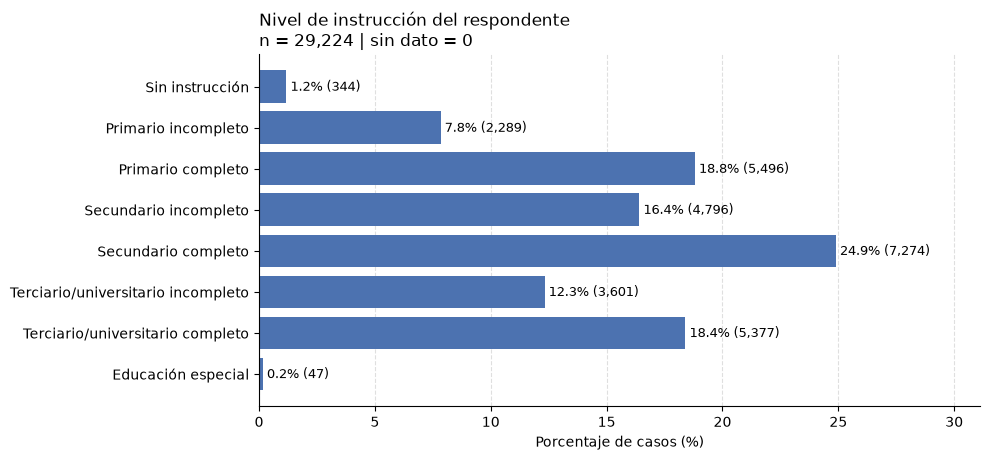

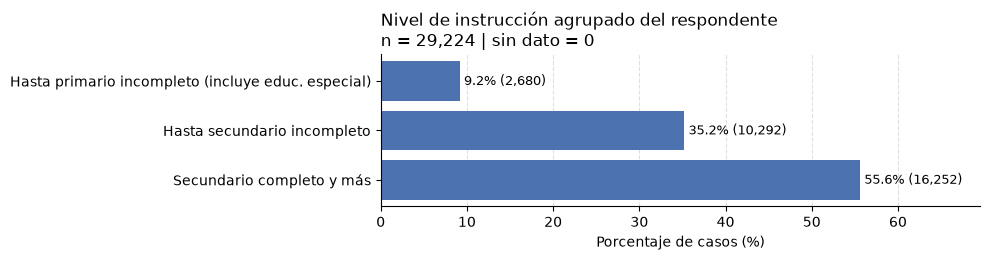

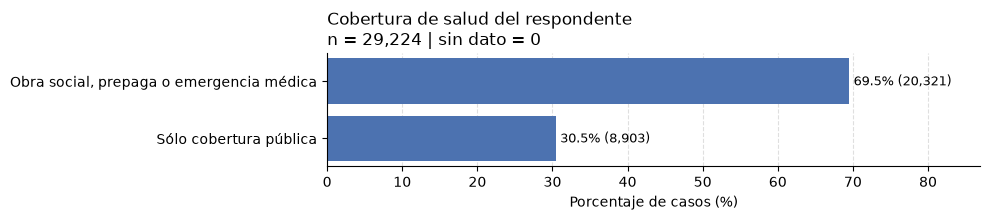

In [16]:
rangos_edad_respondente = {1: "18 a 24 años",  2: "25 a 34 años",
                           3: "35 a 49 años",  4: "50 a 64 años",
                           5: "65 años y más"
}

niveles_agrupados_respondente = {1: "Hasta primario incompleto (incluye educ. especial)",
                                 2: "Hasta secundario incompleto",
                                 3: "Secundario completo y más"
}

coberturas_respondente = {1: "Obra social, prepaga o emergencia médica",  2: "Sólo cobertura pública"}

# bhch02 a bhch05 y bhch10_01 a bhch10_06 ya están graficadas en 1.2.5 (Componentes)
variables_131 = {
    "rango_edad": ("Rango de edad del respondente", rangos_edad_respondente),
    "nivel_instruccion": ("Nivel de instrucción del respondente", niveles_instruccion),
    "nivel_instruccion_agrupado": ("Nivel de instrucción agrupado del respondente", niveles_agrupados_respondente),
    "cobertura_salud": ("Cobertura de salud del respondente", coberturas_respondente),
}

for col, (titulo, etiquetas) in variables_131.items():
    graficar_variable(raw_data_sociodemografico[col], titulo, tipo="categorica", etiquetas=etiquetas)

### 1.3.2 Situación laboral

In [17]:
columnas = [ "id", 
            "bisl01",
            "bisl02",
            "bisl03",
            "bisl04",
            "bisl05",
            "bisl06",
            "condicion_actividad"]
raw_data_situ_laboral = raw_data[columnas]

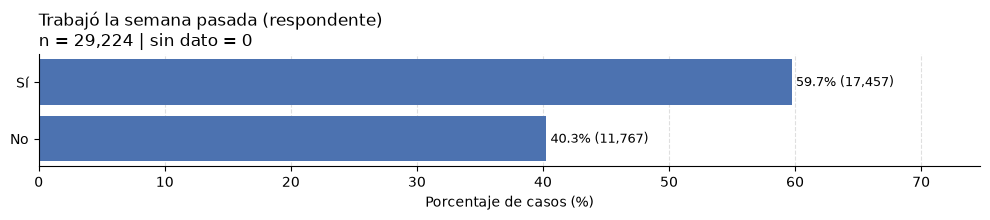

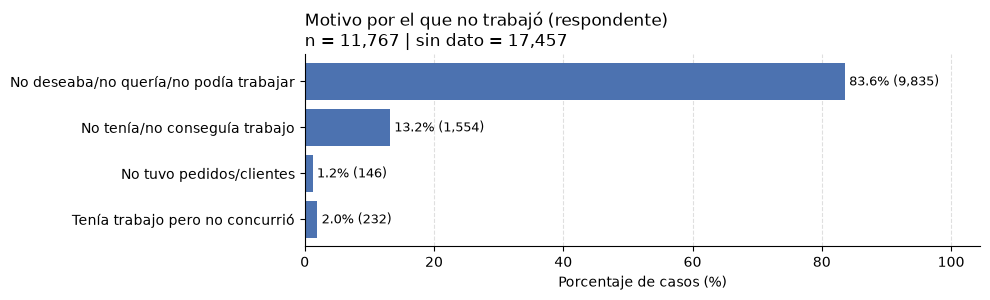

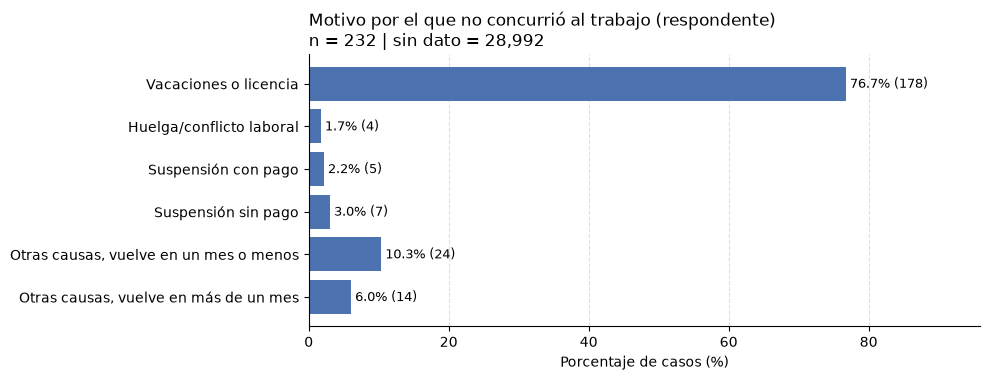

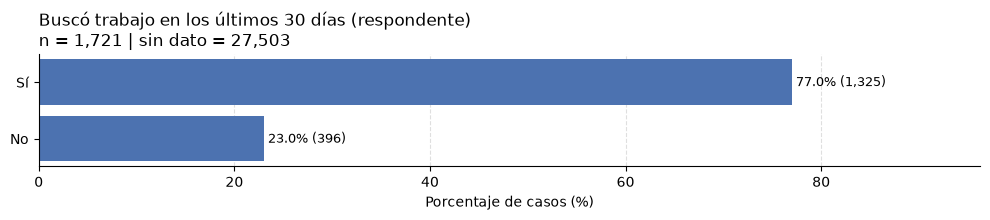

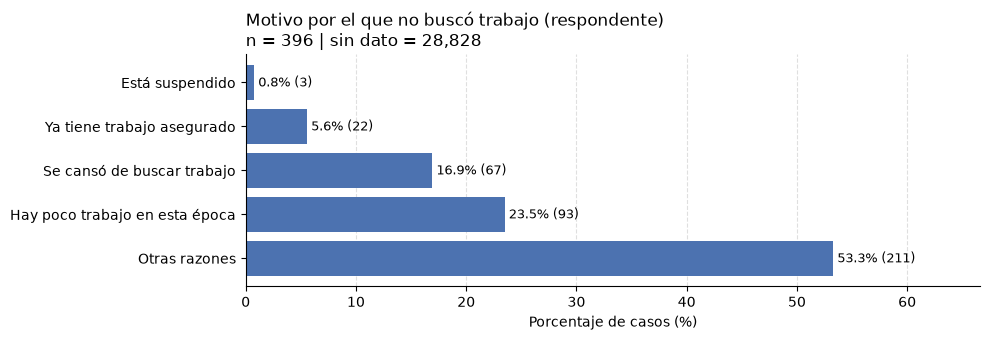

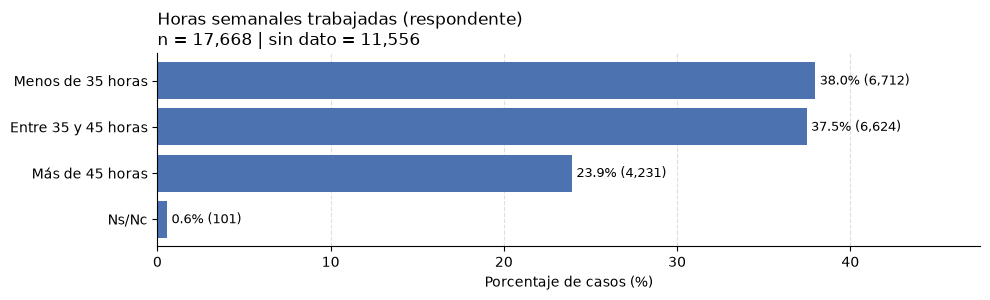

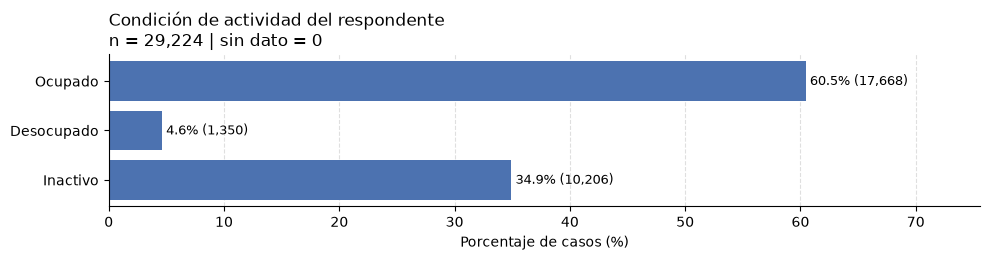

In [18]:
variables_132 = {
    "bisl01": ("Trabajó la semana pasada (respondente)", si_no),
    "bisl02": ("Motivo por el que no trabajó (respondente)", motivos_no_trabajo),
    "bisl03": ("Motivo por el que no concurrió al trabajo (respondente)", motivos_ausencia),
    "bisl04": ("Buscó trabajo en los últimos 30 días (respondente)", si_no),
    "bisl05": ("Motivo por el que no buscó trabajo (respondente)", motivos_no_busqueda),
    "bisl06": ("Horas semanales trabajadas (respondente)", horas_semanales),
    "condicion_actividad": ("Condición de actividad del respondente", condiciones_actividad),
}

for col, (titulo, etiquetas) in variables_132.items():
    graficar_variable(raw_data_situ_laboral[col], titulo, tipo="categorica", etiquetas=etiquetas)

### 1.3.3 Salud general

In [19]:
columnas = [ "id", 
            "bisg01",
            "bisg02",
            "bisg03",
            "bisg04",
            "bisg05",
            "bisg06",]
raw_data_salud_general = raw_data[columnas]

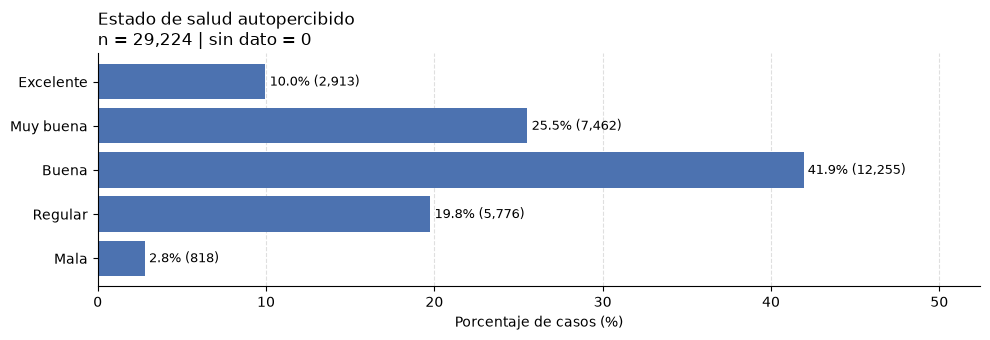

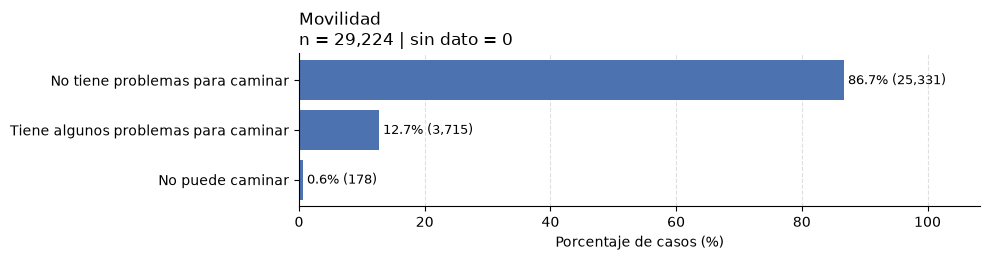

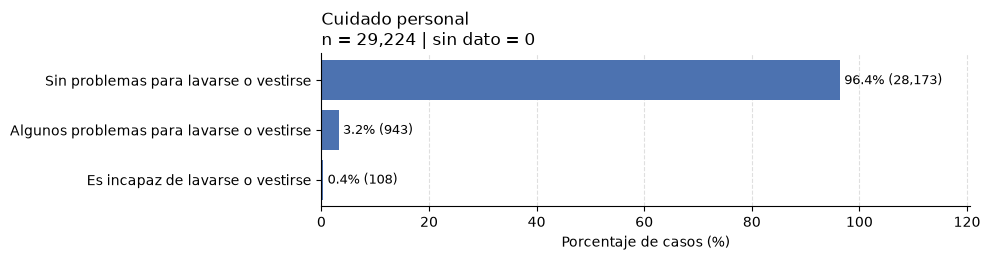

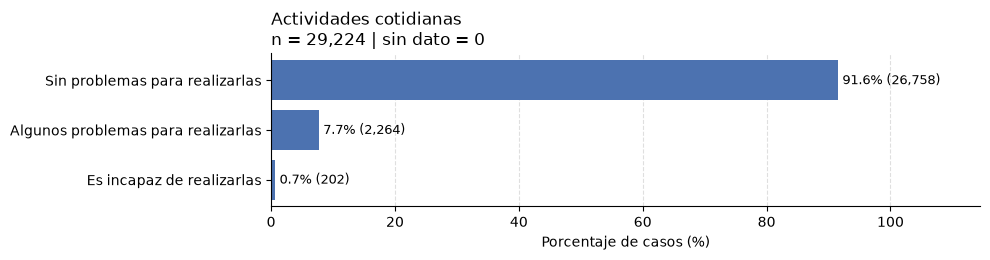

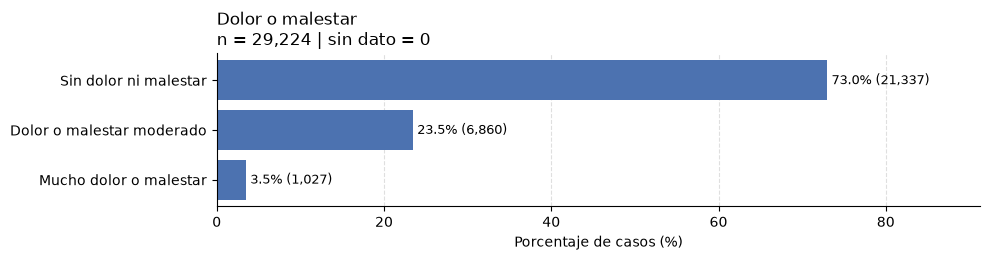

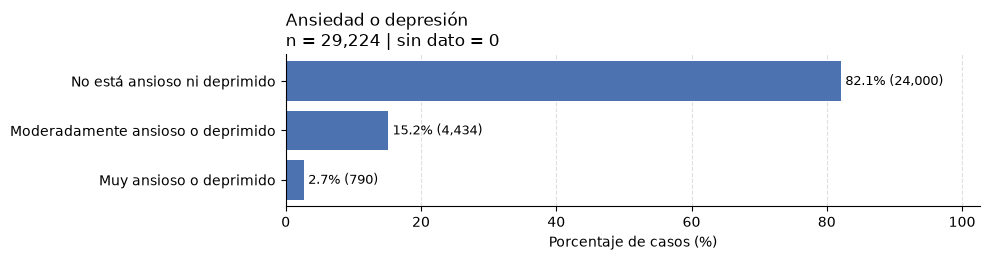

In [20]:
estados_salud = {1: "Excelente",  2: "Muy buena",
                 3: "Buena",      4: "Regular",
                 5: "Mala"
}

movilidades = {1: "No tiene problemas para caminar",  2: "Tiene algunos problemas para caminar",
               3: "No puede caminar"
}

cuidados_personales = {1: "Sin problemas para lavarse o vestirse",  2: "Algunos problemas para lavarse o vestirse",
                       3: "Es incapaz de lavarse o vestirse"
}

actividades_cotidianas = {1: "Sin problemas para realizarlas",  2: "Algunos problemas para realizarlas",
                          3: "Es incapaz de realizarlas"
}

dolores = {1: "Sin dolor ni malestar",  2: "Dolor o malestar moderado",
           3: "Mucho dolor o malestar"
}

ansiedades = {1: "No está ansioso ni deprimido",  2: "Moderadamente ansioso o deprimido",
              3: "Muy ansioso o deprimido"
}

variables_133 = {
    "bisg01": ("Estado de salud autopercibido", estados_salud),
    "bisg02": ("Movilidad", movilidades),
    "bisg03": ("Cuidado personal", cuidados_personales),
    "bisg04": ("Actividades cotidianas", actividades_cotidianas),
    "bisg05": ("Dolor o malestar", dolores),
    "bisg06": ("Ansiedad o depresión", ansiedades),
}

for col, (titulo, etiquetas) in variables_133.items():
    graficar_variable(raw_data_salud_general[col], titulo, tipo="categorica", etiquetas=etiquetas)

### 1.3.4 Actividad física

In [21]:
colunas = [ "id", 
           "biaf01",
           "biaf02_m",
           "biaf02_99",
           "biaf03",
           "biaf04_m",
           "biaf04_99",
           "biaf05",
           "biaf06_m",
           "biaf06_99",
           "biaf07_m",
           "biaf07_99",
           "biaf08",
           "biaf09",
           "biaf10_01",
           "biaf10_02",
           "biaf10_03",
           "biaf10_04",
           "nivel_actividad_fisica",
           "barreras_actividad_fisica"
           ]
raw_data_actividad_fisica = raw_data[colunas]

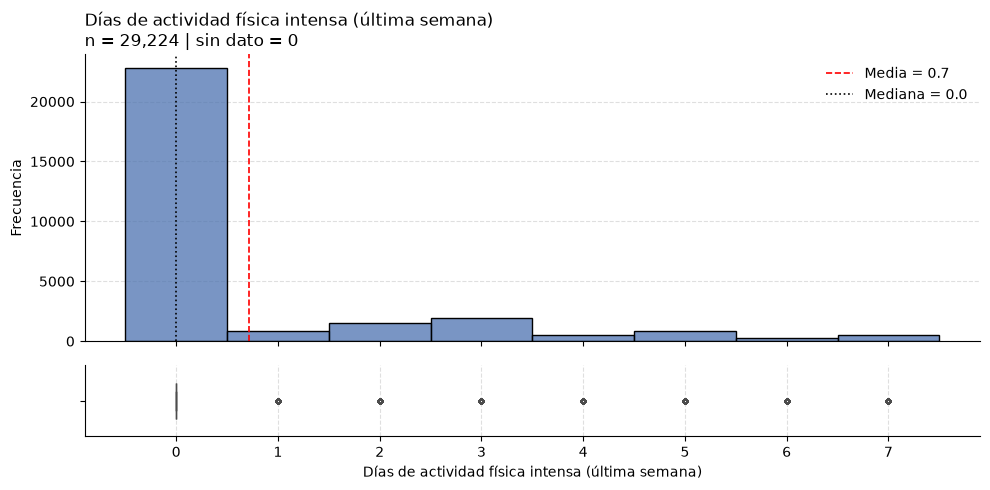

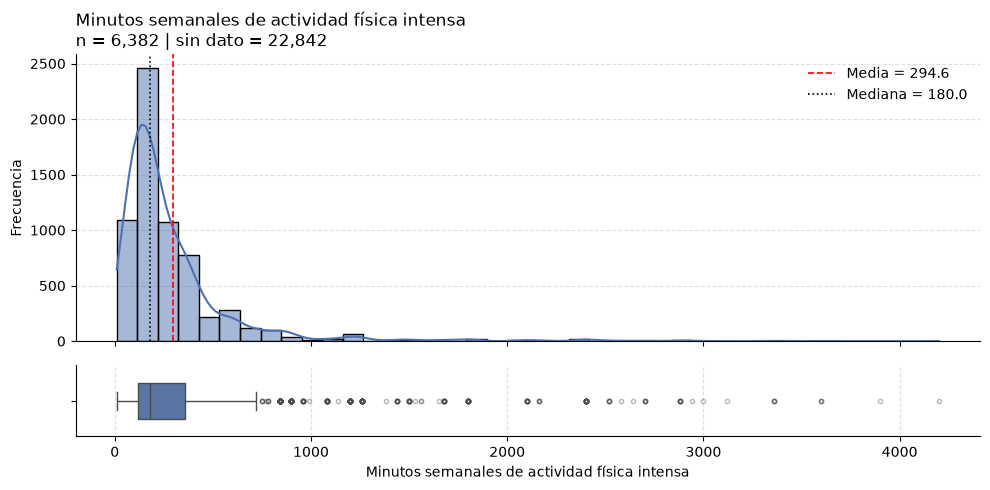

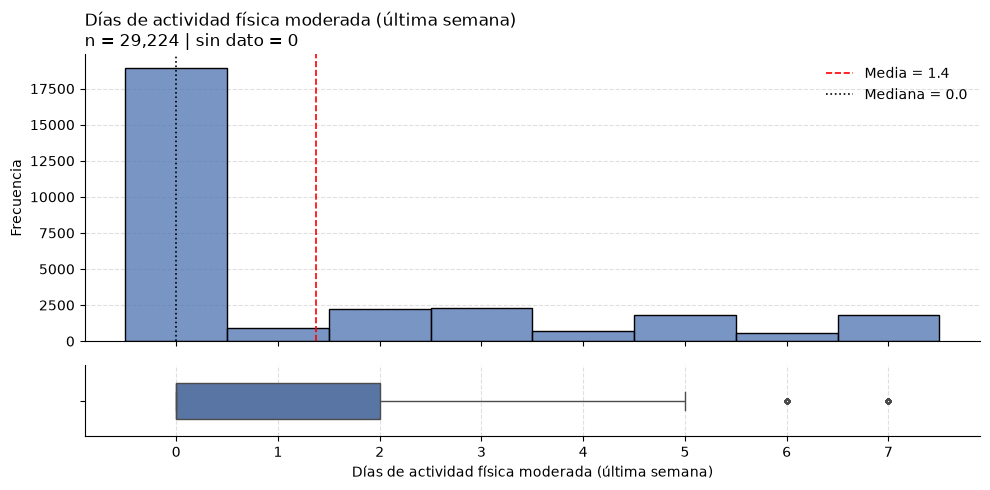

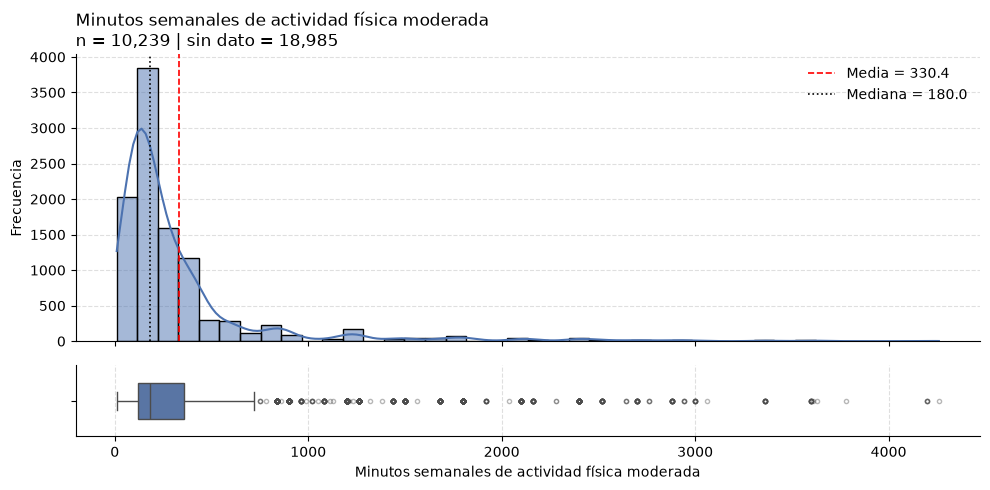

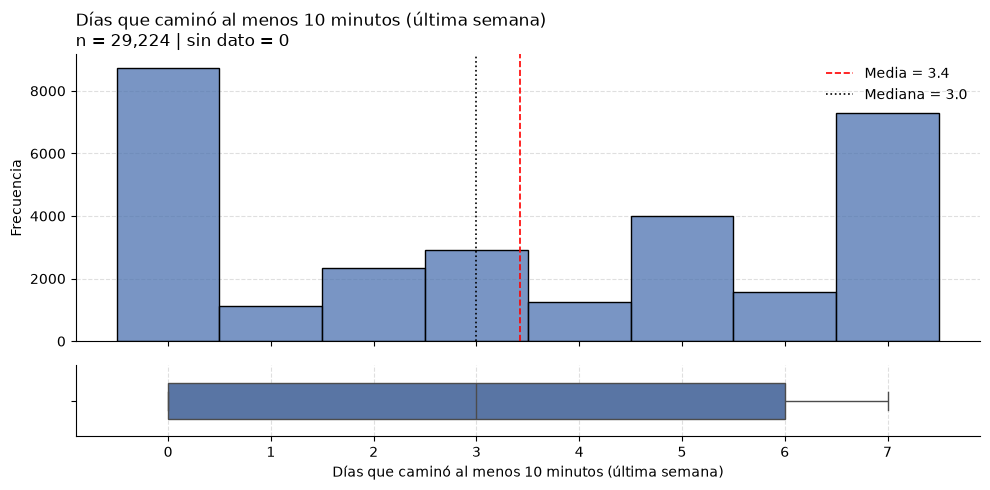

...

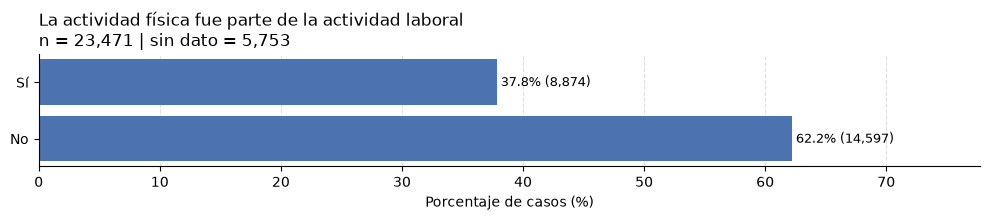

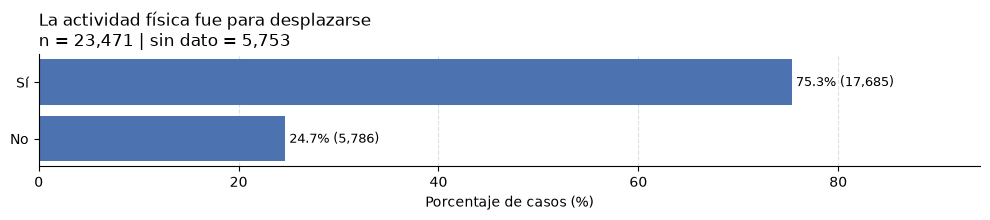

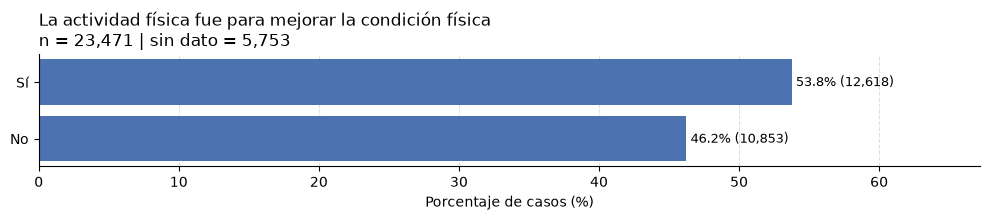

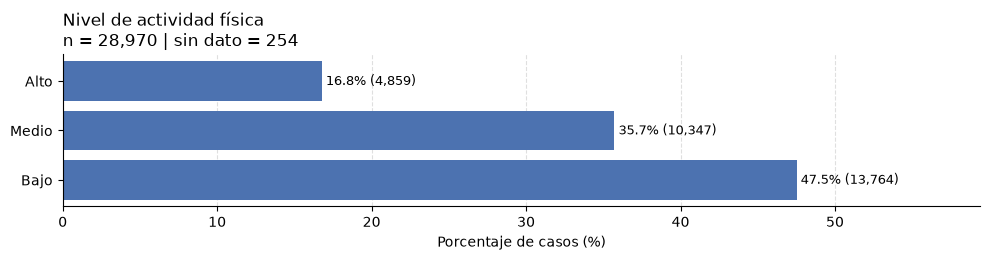

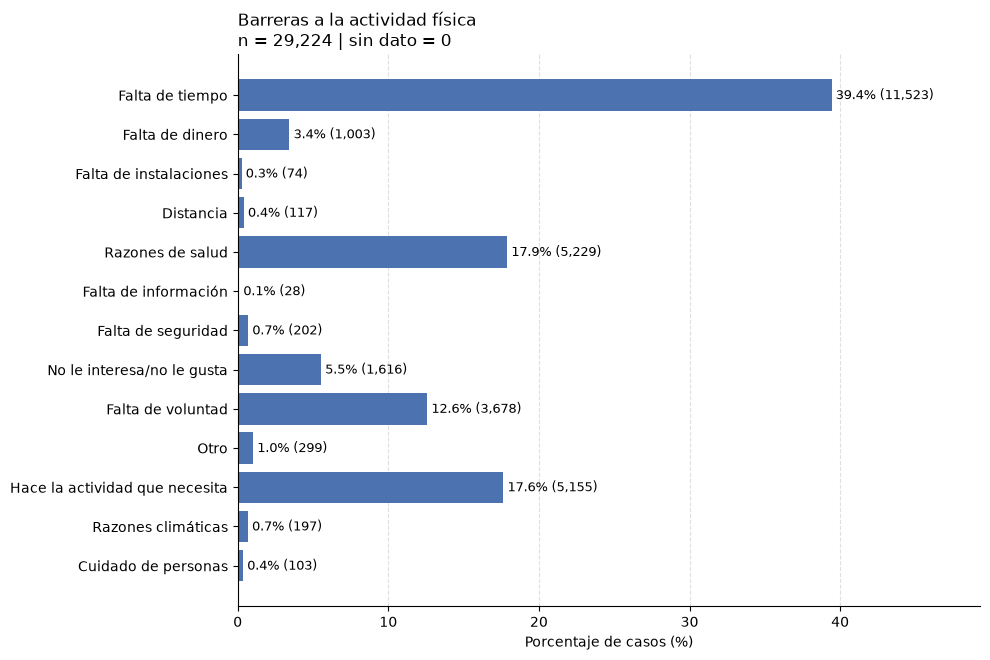

In [22]:
razones_sin_actividad = {1: "Falta de tiempo",             2: "Falta de dinero",
                         3: "Falta de instalaciones",      4: "Distancia",
                         5: "Razones de salud",            6: "Falta de información",
                         7: "Falta de seguridad",          8: "No le interesa/no le gusta",
                         9: "Falta de voluntad",           10: "Otro",
                         11: "Cuidado de personas"
}

razones_sin_mas_actividad = {1: "Hace la actividad que necesita",  2: "Falta de tiempo",
                             3: "Falta de dinero",                 4: "Falta de instalaciones",
                             5: "Distancia",                       6: "Razones de salud",
                             7: "Falta de información",            8: "Falta de seguridad",
                             9: "No le interesa/no le gusta",      10: "Falta de voluntad",
                             11: "Otro",                           12: "Razones climáticas",
                             13: "Cuidado de personas"
}

niveles_actividad = {1: "Alto",  2: "Medio",
                     3: "Bajo"
}

barreras_actividad = {1: "Falta de tiempo",             2: "Falta de dinero",
                      3: "Falta de instalaciones",      4: "Distancia",
                      5: "Razones de salud",            6: "Falta de información",
                      7: "Falta de seguridad",          8: "No le interesa/no le gusta",
                      9: "Falta de voluntad",           10: "Otro",
                      11: "Hace la actividad que necesita", 12: "Razones climáticas",
                      13: "Cuidado de personas"
}
variables_134 = {
    "biaf08": ("Razón principal para no hacer actividad física", razones_sin_actividad),
    "biaf09": ("Razón principal para no hacer más actividad física", razones_sin_mas_actividad),
    "biaf10_01": ("La actividad física fue parte de la actividad doméstica", si_no),
    "biaf10_02": ("La actividad física fue parte de la actividad laboral", si_no),
    "biaf10_03": ("La actividad física fue para desplazarse", si_no),
    "biaf10_04": ("La actividad física fue para mejorar la condición física", si_no),
    "nivel_actividad_fisica": ("Nivel de actividad física", niveles_actividad),
    "barreras_actividad_fisica": ("Barreras a la actividad física", barreras_actividad),
}

graficar_variable(raw_data_actividad_fisica["biaf01"], "Días de actividad física intensa (última semana)", tipo="discreta")
graficar_variable(raw_data_actividad_fisica["biaf02_m"], "Minutos semanales de actividad física intensa", tipo="continua")
graficar_variable(raw_data_actividad_fisica["biaf03"], "Días de actividad física moderada (última semana)", tipo="discreta")
graficar_variable(raw_data_actividad_fisica["biaf04_m"], "Minutos semanales de actividad física moderada", tipo="continua")
graficar_variable(raw_data_actividad_fisica["biaf05"], "Días que caminó al menos 10 minutos (última semana)", tipo="discreta")
graficar_variable(raw_data_actividad_fisica["biaf06_m"], "Minutos semanales de caminata", tipo="continua")
graficar_variable(raw_data_actividad_fisica["biaf07_m"], "Minutos diarios sentado", tipo="continua")

for col, (titulo, etiquetas) in variables_134.items():
    graficar_variable(raw_data_actividad_fisica[col], titulo, tipo="categorica", etiquetas=etiquetas)

### 1.3.5 Tabaco

In [23]:
columnas = [
    "id",
    "bita01",
    "bita02",
    "bita02_99",
    "bita03",
    "bita04",
    "bita04_01",
    "bita04_02",
    "bita05",
    "bita06_a",
    "bita06_b",
    "bita06_b_99",
    "bita06_c",
    "bita06_d",
    "bita07",
    "bita07_99",
    "bita08",
    "bita09_01",
    "bita09_02",
    "bita09_03",
    "bita09_04",
    "bita09_05",
    "bita09_06",
    "bita10_01",
    "bita10_02",
    "bita10_03",
    "bita10_04",
    "bita10_05",
    "bita10_06",
    "bita11",
    "bita12",
    "bita13",
    "bita14",
    "bita15",
    "bita16",
    "consumo_tabaco_100",
    "ta_paquete_y_armado",
    "ta_dejar_fumar",
    "ta_otros_productos",
    "hta_nofumadores",
    "ta_perc_publicidad",
    "ta_percepcion_riesgo",
    "imagenes_tabaco"
]
raw_data_tabaco = raw_data[columnas]

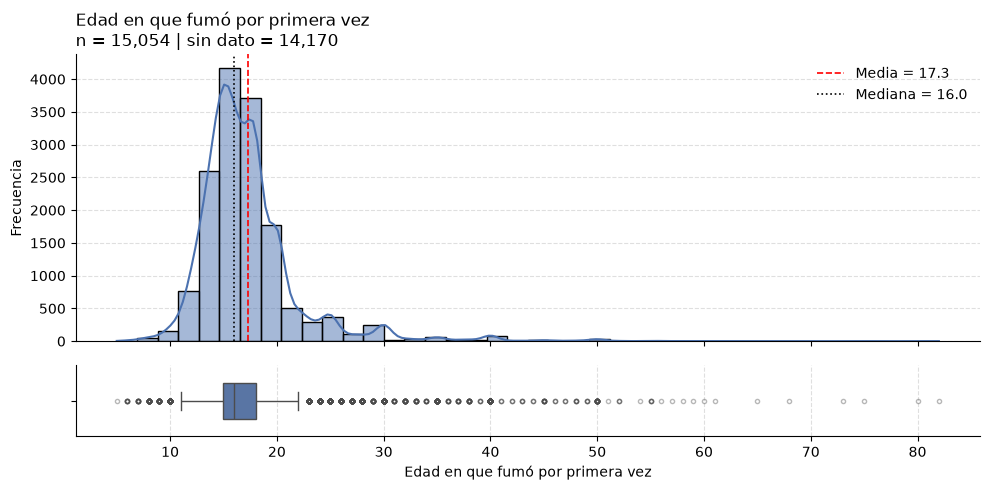

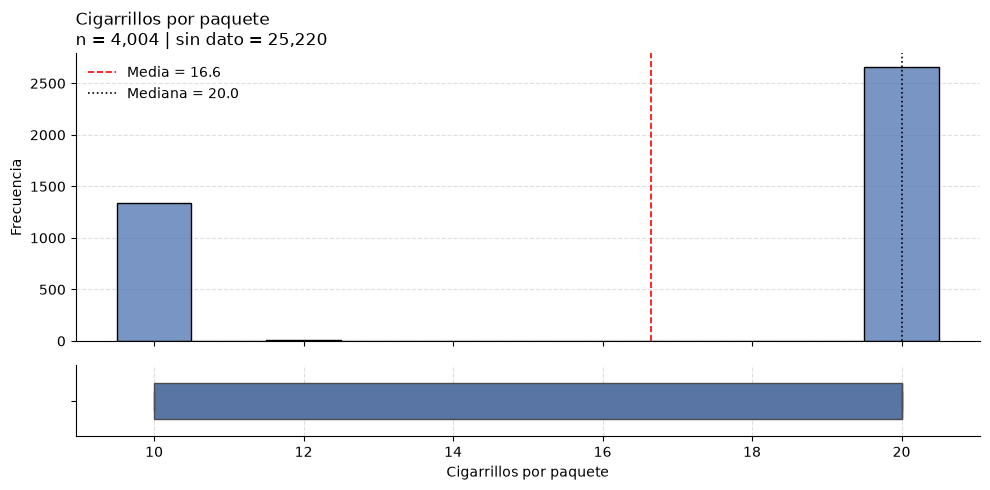

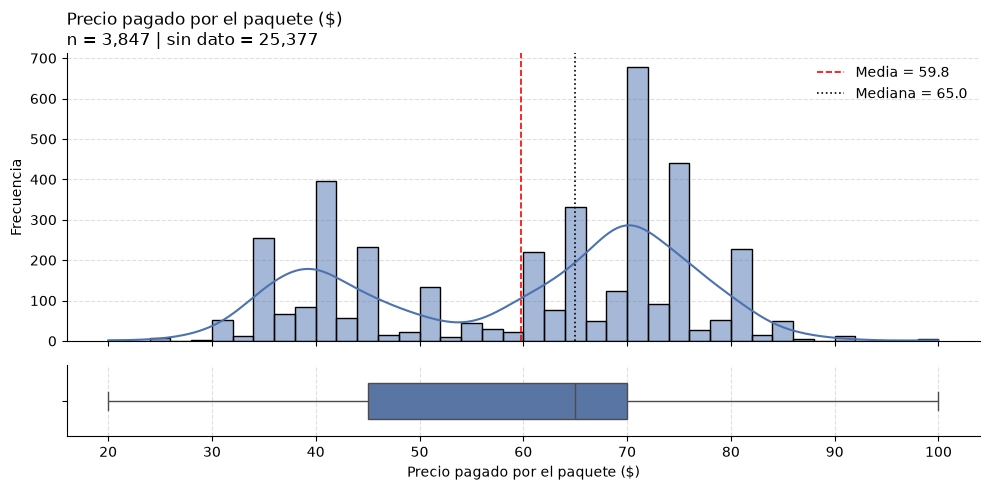

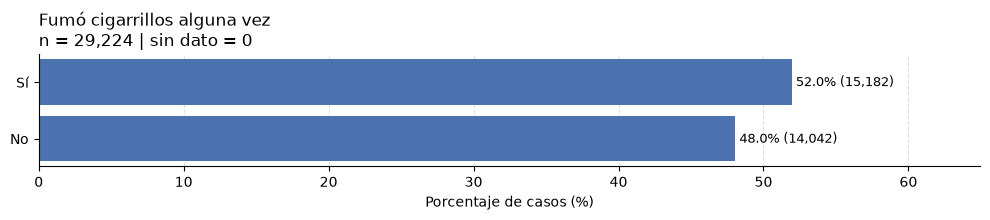

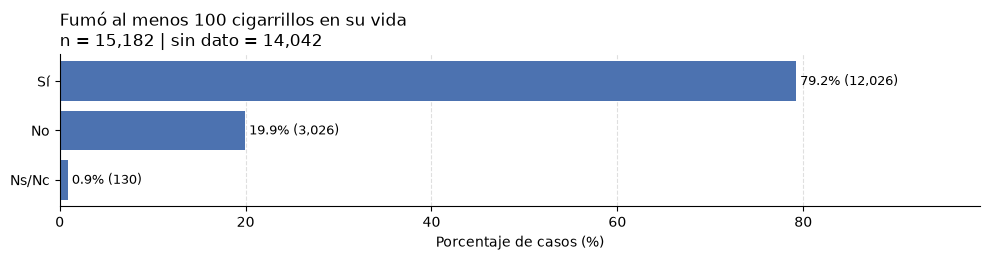

...

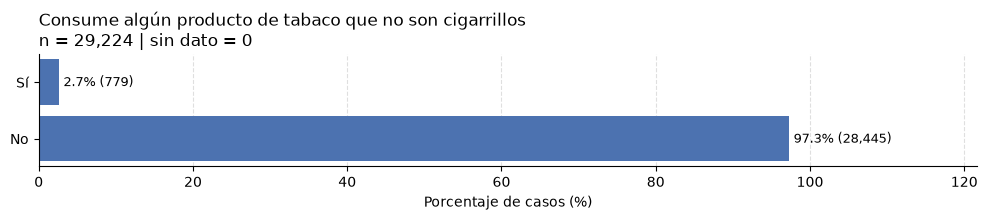

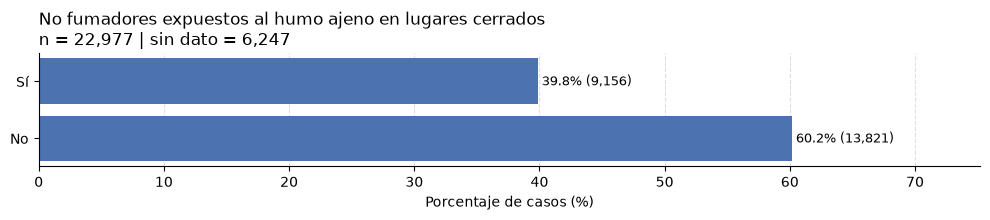

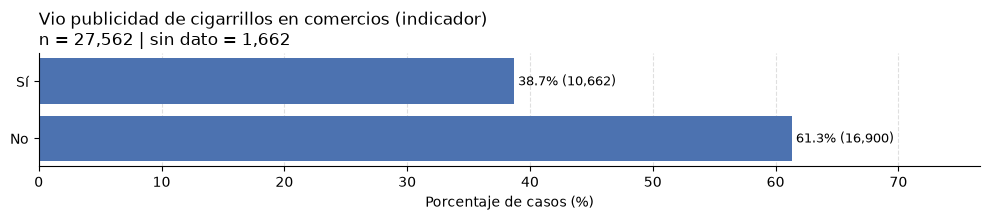

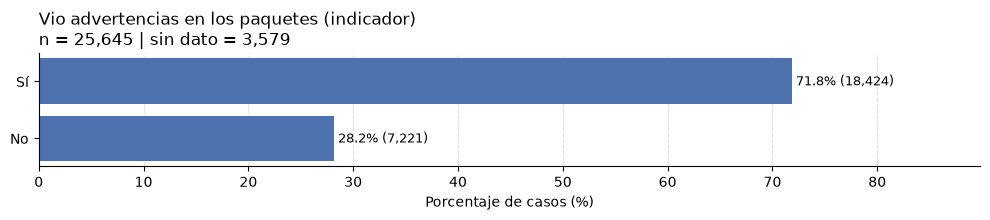

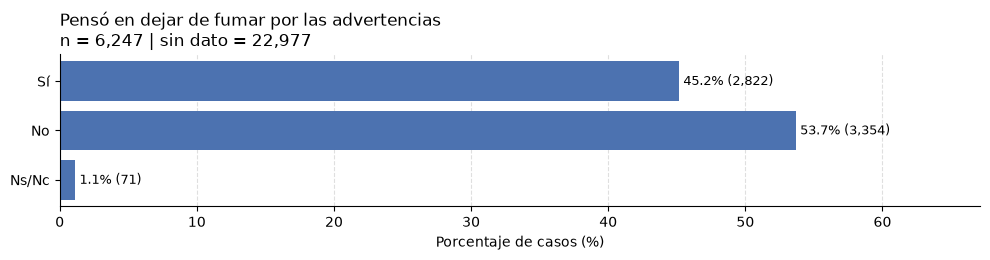

In [24]:
frecuencias_fumar = {1: "Todos los días",  2: "Algunos días",
                     3: "No fuma"
}

marcas = {1: "Lucky Strike",          2: "Camel",
          3: "Pall Mall",             4: "Marlboro",
          5: "Philip Morris",         6: "43/70",
          7: "Baltimore",             8: "Bashia",
          9: "Benson & Hedges 100s",  10: "Chesterfield",
          11: "CJ",                   12: "Dunhill fine cut master",
          13: "Freeport box",         14: "Gavilán",
          15: "Gitanes blondes",      16: "Gudang Garam",
          17: "Imparciales 100s",     18: "Inter gold",
          19: "Jockey club",          20: "John Player gold leaf",
          21: "L&M",                  22: "Melbourne",
          23: "Milenio",              24: "Paladium",
          25: "Parisiennes",          26: "Parliament",
          27: "Particulares",         28: "Red Point",
          29: "Rodeo",                30: "Rothmans",
          31: "V8",                   32: "Viceroy",
          33: "Virginia Slims 100s",  34: "Winston",
          35: "Otro"
}

tipos_paquete = {1: "Box",                       2: "Común (blando)",
                 98: "Fuma cigarrillos sueltos",  99: "Ns/Nc"
}

sabores = {1: "Común (sin saborizar)",  2: "Mentolados",
           3: "Otro sabor"
}

capsulas = {1: "Cápsula simple",  2: "Cápsula doble",
            99: "Ns/Nc"
}

si_no_no_estuvo = {1: "Sí",  2: "No",
                   98: "No estuvo"
}

si_no_comercios = {1: "Sí",  2: "No",
                   98: "No fue a comercios que venden cigarrillos"
}

si_no_paquetes = {1: "Sí",  2: "No",
                  98: "No vio paquetes de cigarrillos"
}

condiciones_fumador = {1: "Fumador actual",  2: "Ex fumador",
                       3: "No fumador"
}

variables_135 = {
    "bita01": ("Fumó cigarrillos alguna vez", si_no),
    "bita03": ("Fumó al menos 100 cigarrillos en su vida", si_no_nsnc),
    "bita04": ("Fuma actualmente", frecuencias_fumar),
    "bita04_01": ("Fuma cigarrillo armado", si_no),
    "bita04_02": ("Fuma cigarrillo de paquete", si_no),
    "bita05": ("Marca de cigarrillos que fuma habitualmente", marcas),
    "bita06_a": ("Tipo de paquete que compra", tipos_paquete),
    "bita06_c": ("Sabor de los cigarrillos", sabores),
    "bita06_d": ("Tipo de cápsula", capsulas),
    "bita08": ("Intentó dejar de fumar en el último año", si_no_nsnc),
    "bita09_01": ("Consume cigarros o habanos", si_no),
    "bita09_02": ("Consume cigarritos", si_no),
    "bita09_03": ("Consume pipa común", si_no),
    "bita09_04": ("Consume pipa de agua", si_no),
    "bita09_05": ("Consume tabaco para masticar", si_no),
    "bita09_06": ("Consume cigarrillo electrónico", si_no),
    "bita10_01": ("Vio fumar dentro de su casa (últimos 30 días)", si_no_no_estuvo),
    "bita10_02": ("Vio fumar dentro de su trabajo (últimos 30 días)", si_no_no_estuvo),
    "bita10_03": ("Vio fumar en instituciones educativas (últimos 30 días)", si_no_no_estuvo),
    "bita10_04": ("Vio fumar en bares o restaurantes (últimos 30 días)", si_no_no_estuvo),
    "bita10_05": ("Vio fumar en hospitales o centros de salud (últimos 30 días)", si_no_no_estuvo),
    "bita10_06": ("Vio fumar en otros lugares cerrados (últimos 30 días)", si_no_no_estuvo),
    "bita11": ("Vio publicidad de cigarrillos en comercios", si_no_comercios),
    "bita12": ("Recibió publicidad de cigarrillos por correo electrónico", si_no),
    "bita13": ("Se suscribió a una web de marcas de cigarrillos", si_no),
    "bita14": ("Vio advertencias sobre el riesgo de fumar en los paquetes", si_no_paquetes),
    "bita15": ("Las advertencias lo hicieron pensar en dejar de fumar", si_no_nsnc),
    "bita16": ("De acuerdo con aumentar el impuesto al tabaco", si_no_nsnc),
    "consumo_tabaco_100": ("Condición de fumador", condiciones_fumador),
    "ta_paquete_y_armado": ("Consume cigarrillos de paquete y armados", si_no),
    "ta_dejar_fumar": ("Intentó dejar de fumar en el último año (indicador)", si_no_nsnc),
    "ta_otros_productos": ("Consume algún producto de tabaco que no son cigarrillos", si_no),
    "hta_nofumadores": ("No fumadores expuestos al humo ajeno en lugares cerrados", si_no),
    "ta_perc_publicidad": ("Vio publicidad de cigarrillos en comercios (indicador)", si_no),
    "ta_percepcion_riesgo": ("Vio advertencias en los paquetes (indicador)", si_no),
    "imagenes_tabaco": ("Pensó en dejar de fumar por las advertencias", si_no_nsnc),
}

graficar_variable(raw_data_tabaco["bita02"], "Edad en que fumó por primera vez", tipo="continua")
graficar_variable(raw_data_tabaco["bita06_b"], "Cigarrillos por paquete", tipo="discreta")
graficar_variable(raw_data_tabaco["bita07"], "Precio pagado por el paquete ($)", tipo="continua")

for col, (titulo, etiquetas) in variables_135.items():
    graficar_variable(raw_data_tabaco[col], titulo, tipo="categorica", etiquetas=etiquetas)

### 1.3.6 Hipertensión arterial

In [25]:
columnas = [
    "id",
    "biha01",
    "biha02",
    "biha03",
    "biha04",
    "biha05_01",
    "biha05_02",
    "biha06",
    "biha06_99",
    "biha07",
    "biha08",
    "biha09",
    "biha10",
    "biha11",
    "biha11_99",
    "biha12",
    "biha13",
    "biha14",
    "biha15",
    "control_hipertension",
    "prevalencia_hipertension",
]
raw_data_hipertension = raw_data[columnas]
raw_data_hipertension.head(5)

,id,biha01,biha02,biha03,biha04,biha05_01,biha05_02,biha06,biha06_99,biha07,...,biha09,biha10,biha11,biha11_99,biha12,biha13,biha14,biha15,control_hipertension,prevalencia_hipertension
0,1128639,1,1.0,3,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,2.0
1,1709939,1,1.0,3,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,2.0
2,6874130,1,1.0,3,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,2.0
3,10319375,1,2.0,3,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,2.0
4,11140857,1,1.0,3,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,2.0


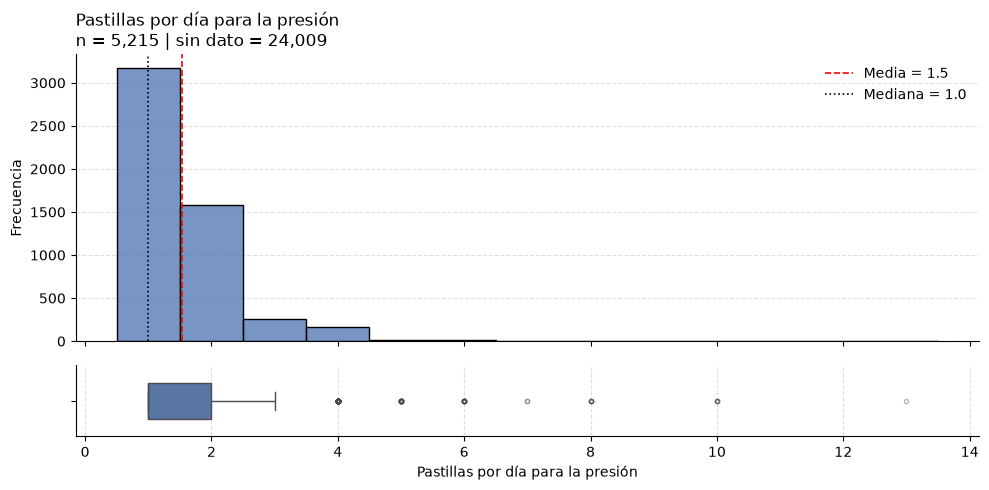

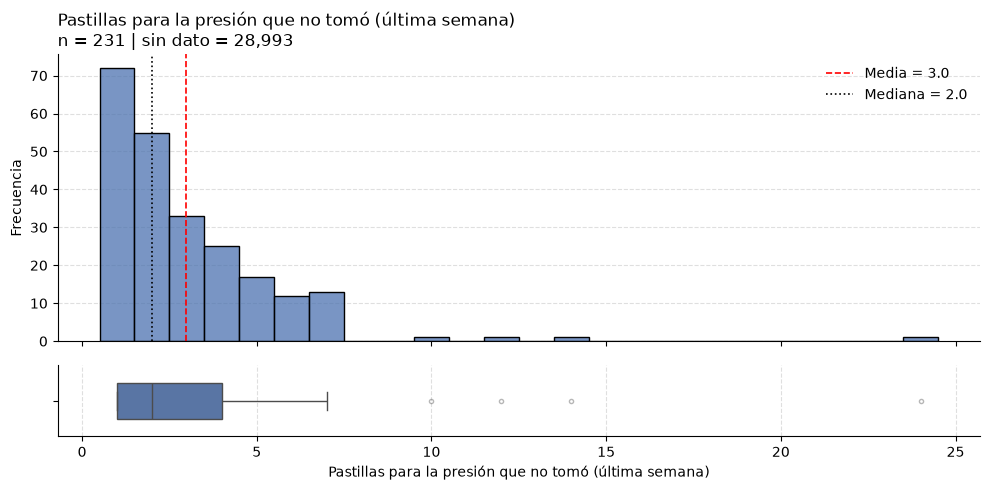

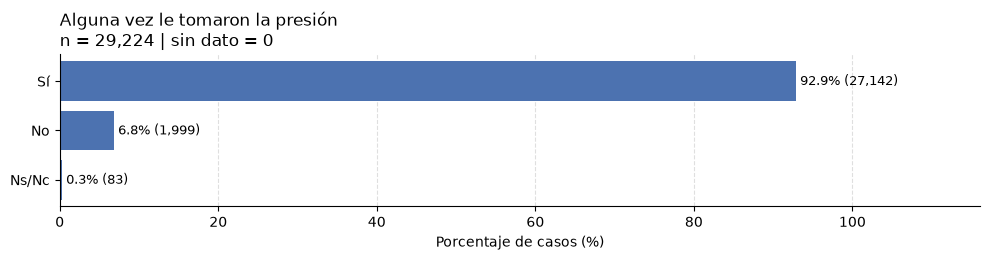

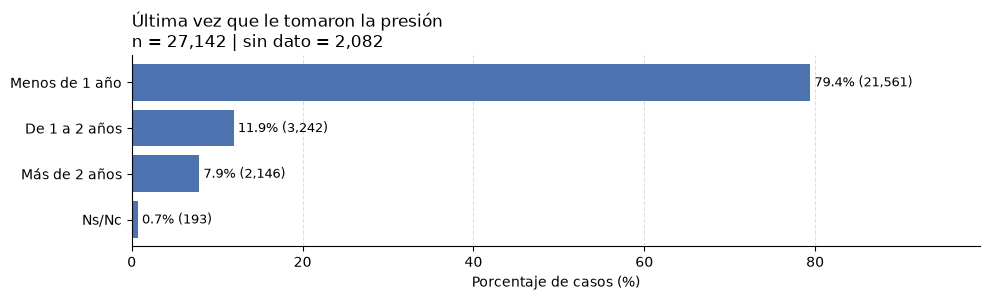

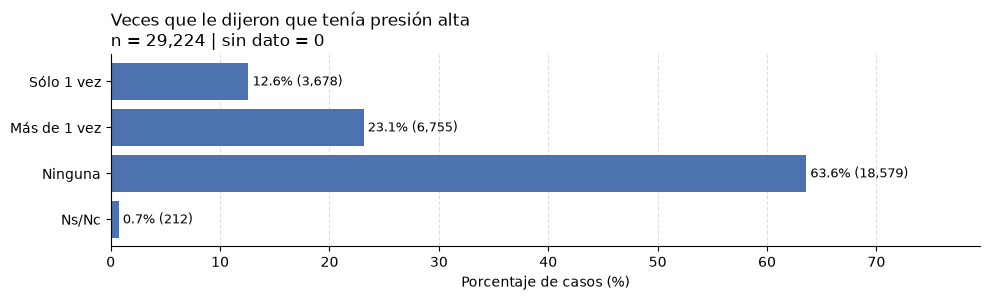

...

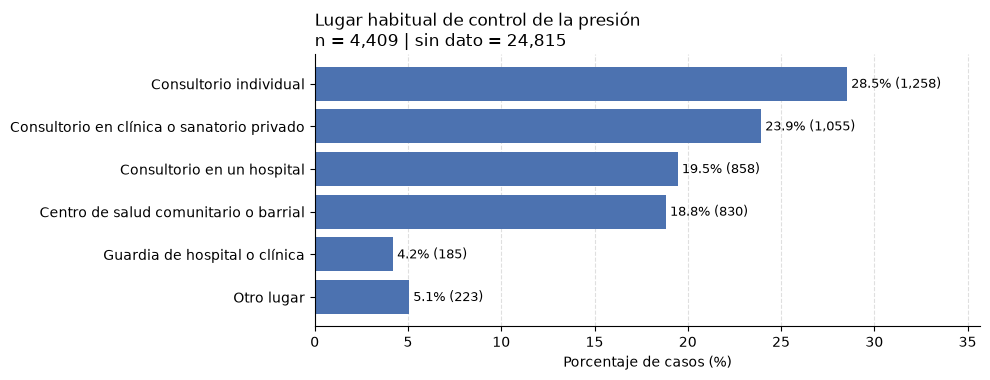

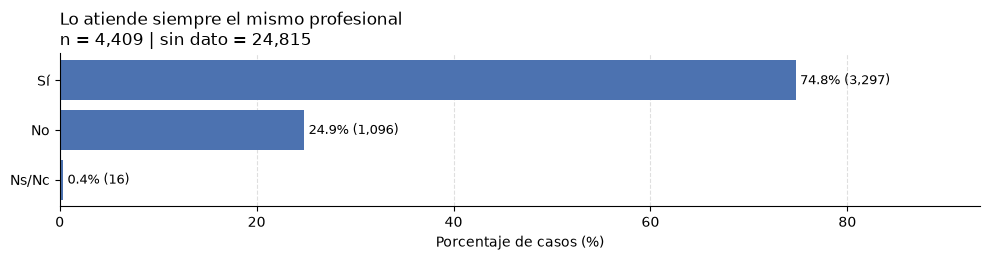

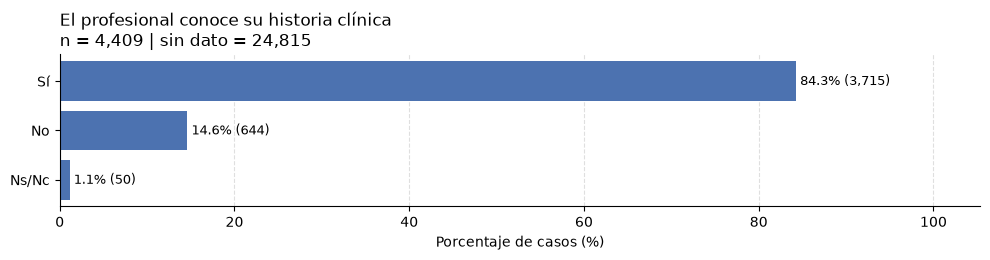

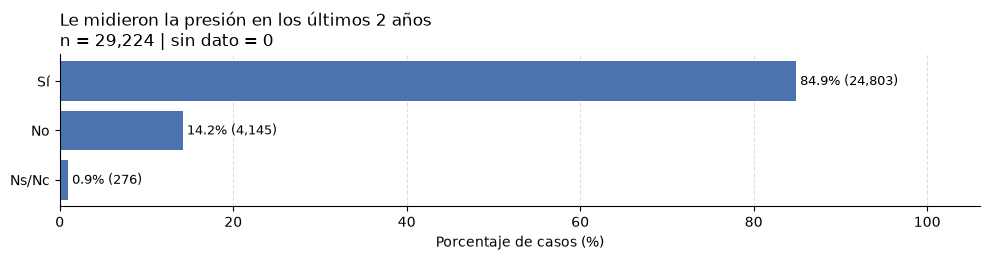

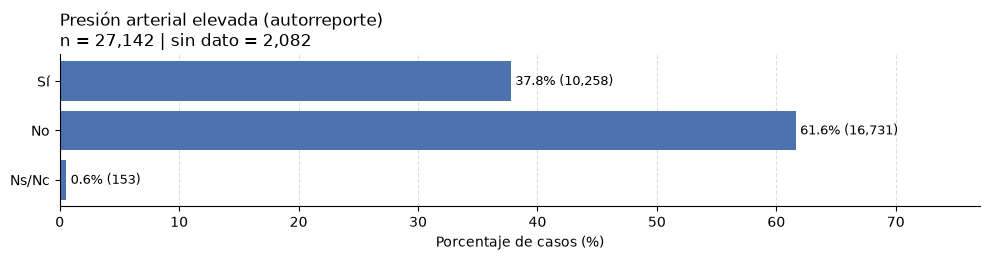

In [26]:
ultimas_mediciones = {1: "Menos de 1 año",  2: "De 1 a 2 años",
                      3: "Más de 2 años",   99: "Ns/Nc"
}

veces_presion_alta = {1: "Sólo 1 vez",  2: "Más de 1 vez",
                      3: "Ninguna",     99: "Ns/Nc"
}

tomas_pastillas = {1: "Tomó todas las pastillas",  2: "No tomó algunas",
                   3: "No tomó ninguna"
}

lugares_control = {1: "Consultorio individual",                2: "Consultorio en clínica o sanatorio privado",
                   3: "Consultorio en un hospital",            4: "Centro de salud comunitario o barrial",
                   5: "Guardia de hospital o clínica",         6: "Otro lugar"
}

variables_136 = {
    "biha01": ("Alguna vez le tomaron la presión", si_no_nsnc),
    "biha02": ("Última vez que le tomaron la presión", ultimas_mediciones),
    "biha03": ("Veces que le dijeron que tenía presión alta", veces_presion_alta),
    "biha04": ("Hace tratamiento para la presión (últimas 2 semanas)", si_no),
    "biha05_01": ("Tratamiento con dieta, ejercicio o reducción de peso", si_no),
    "biha05_02": ("Tratamiento con medicamentos", si_no),
    "biha07": ("Se olvida de tomar la medicación para la presión", si_no),
    "biha08": ("Deja la medicación cuando se siente bien", si_no_nsnc),
    "biha09": ("Deja la medicación cuando se siente mal", si_no_nsnc),
    "biha10": ("Toma de pastillas para la presión en la última semana", tomas_pastillas),
    "biha12": ("Tiene un lugar habitual de control de la presión", si_no),
    "biha13": ("Lugar habitual de control de la presión", lugares_control),
    "biha14": ("Lo atiende siempre el mismo profesional", si_no_nsnc),
    "biha15": ("El profesional conoce su historia clínica", si_no_nsnc),
    "control_hipertension": ("Le midieron la presión en los últimos 2 años", si_no_nsnc),
    "prevalencia_hipertension": ("Presión arterial elevada (autorreporte)", si_no_nsnc),
}

graficar_variable(raw_data_hipertension["biha06"], "Pastillas por día para la presión", tipo="discreta")
graficar_variable(raw_data_hipertension["biha11"], "Pastillas para la presión que no tomó (última semana)", tipo="discreta")

for col, (titulo, etiquetas) in variables_136.items():
    graficar_variable(raw_data_hipertension[col], titulo, tipo="categorica", etiquetas=etiquetas)

### 1.3.7 Peso corporal

In [27]:
columnas = [
    "id",
    "bipc01",
    "bipc02",
    "bipc03",
    "bipc04",
    "bipc04_99",
    "bipc05",
    "bipc05_99",
    "imc",
    "imc_categorias",
]
raw_data_peso_corporal = raw_data[columnas]
raw_data_peso_corporal.info()

<class 'pandas.DataFrame'>
RangeIndex: 29224 entries, 0 to 29223
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   id              29224 non-null  int64  
 1   bipc01          29224 non-null  int64  
 2   bipc02          9240 non-null   float64
 3   bipc03          23823 non-null  float64
 4   bipc04          28213 non-null  float64
 5   bipc04_99       1011 non-null   float64
 6   bipc05          27548 non-null  float64
 7   bipc05_99       1676 non-null   float64
 8   imc             26995 non-null  float64
 9   imc_categorias  29224 non-null  int64  
dtypes: float64(7), int64(3)
memory usage: 2.2 MB


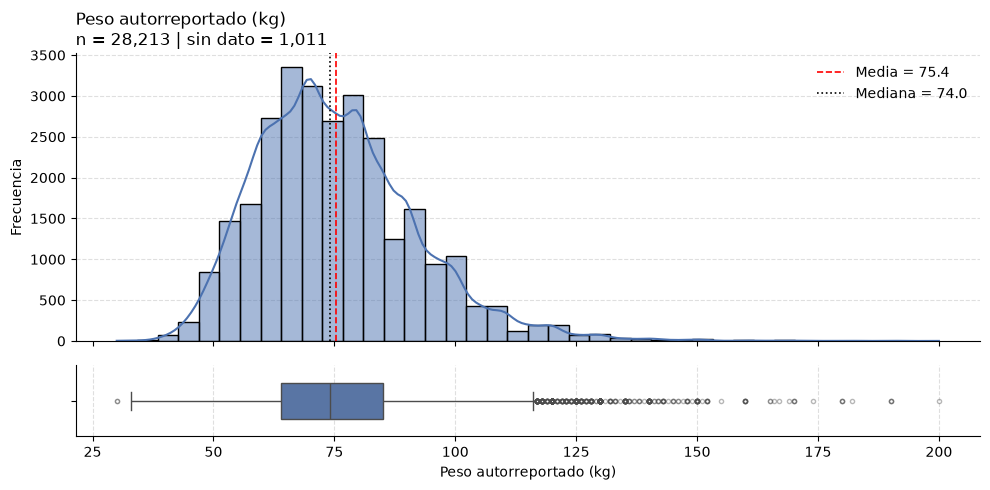

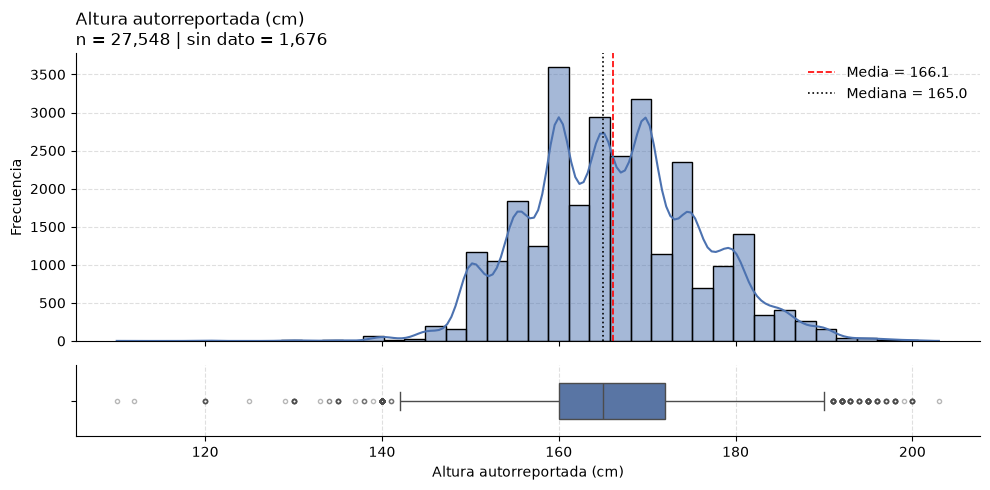

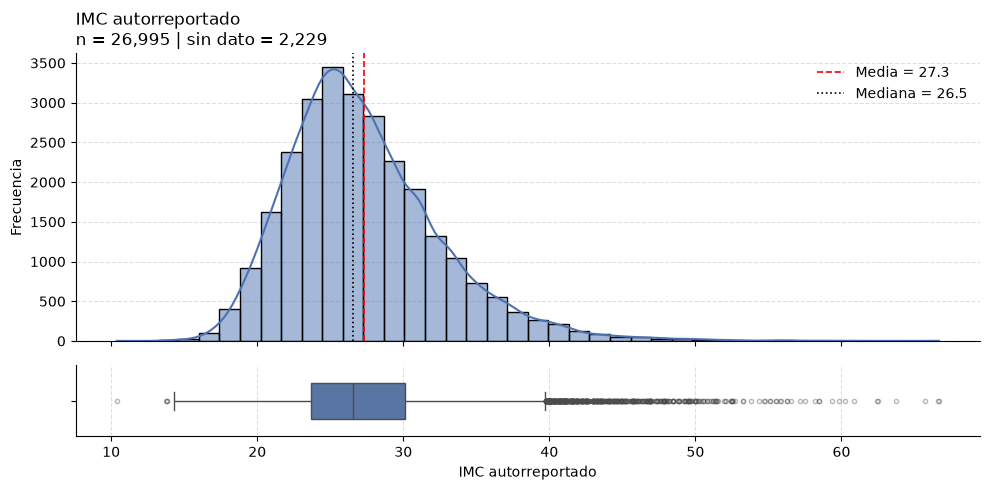

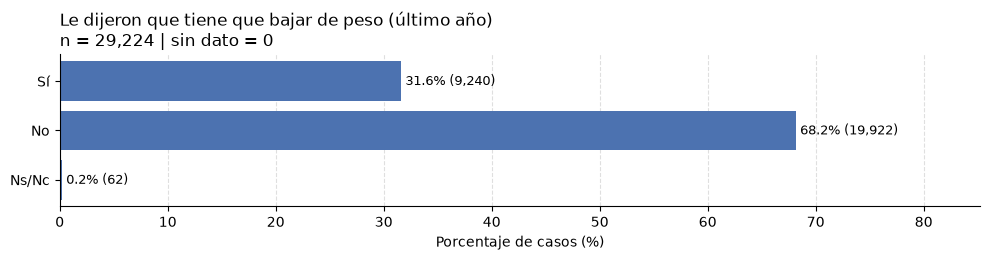

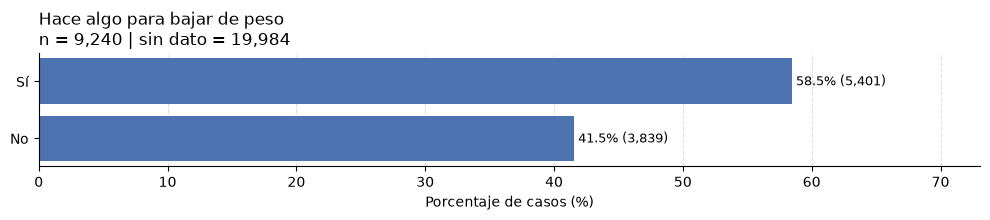

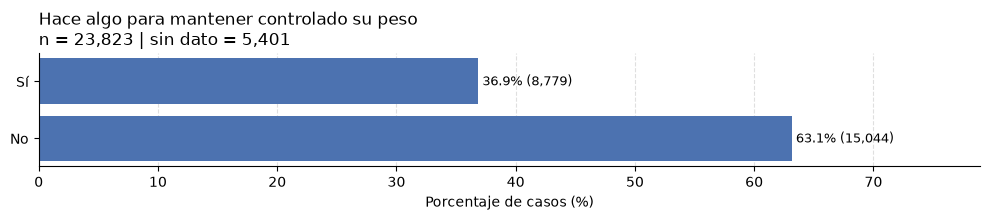

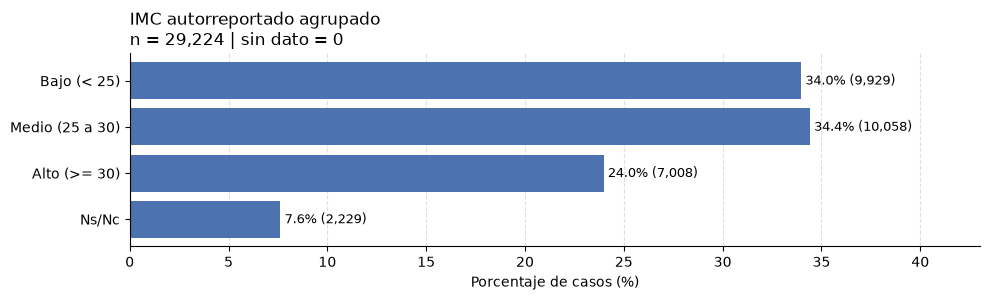

In [28]:
categorias_imc = {1: "Bajo (< 25)",   2: "Medio (25 a 30)",
                  3: "Alto (>= 30)",  99: "Ns/Nc"
}

variables_137 = {
    "bipc01": ("Le dijeron que tiene que bajar de peso (último año)", si_no_nsnc),
    "bipc02": ("Hace algo para bajar de peso", si_no),
    "bipc03": ("Hace algo para mantener controlado su peso", si_no),
    "imc_categorias": ("IMC autorreportado agrupado", categorias_imc),
}

graficar_variable(raw_data_peso_corporal["bipc04"], "Peso autorreportado (kg)", tipo="continua")
graficar_variable(raw_data_peso_corporal["bipc05"], "Altura autorreportada (cm)", tipo="continua")
graficar_variable(raw_data_peso_corporal["imc"], "IMC autorreportado", tipo="continua")

for col, (titulo, etiquetas) in variables_137.items():
    graficar_variable(raw_data_peso_corporal[col], titulo, tipo="categorica", etiquetas=etiquetas)

### 1.3.8 Alimentación

In [29]:
columnas= [
    "id",
    "bial01",
    "bial02",
    "bial03",
    "bial03_99",
    "bial04",
    "bial04_99",
    "bial05",
    "bial05_99",
    "bial06",
    "bial06_99",
    "bial07",
    "bial08",
    "bial09",
    "bial10",
    "promedio_fv_diario",
    "consumo_fv",
    "barreras_fyv",
    "tipo_dieta_razones",
]
raw_data_alimentacion = raw_data[columnas]
raw_data_alimentacion.head(5)

,id,bial01,bial02,bial03,bial03_99,bial04,bial04_99,bial05,bial05_99,bial06,bial06_99,bial07,bial08,bial09,bial10,promedio_fv_diario,consumo_fv,barreras_fyv,tipo_dieta_razones
0,1128639,2,3,7.0,NaN,3.0,NaN,7.0,NaN,1.0,NaN,8,2,NaN,2,4.00,2,1,NaN
1,1709939,2,2,7.0,NaN,5.0,NaN,5.0,NaN,2.0,NaN,1,2,NaN,1,6.43,1,4,NaN
2,6874130,1,1,5.0,NaN,2.0,NaN,5.0,NaN,2.0,NaN,2,2,NaN,2,2.86,2,1,NaN
3,10319375,99,1,3.0,NaN,1.0,NaN,7.0,NaN,1.0,NaN,9,2,NaN,99,1.43,2,1,NaN
4,11140857,1,3,7.0,NaN,1.0,NaN,3.0,NaN,1.0,NaN,2,2,NaN,1,1.43,2,1,NaN


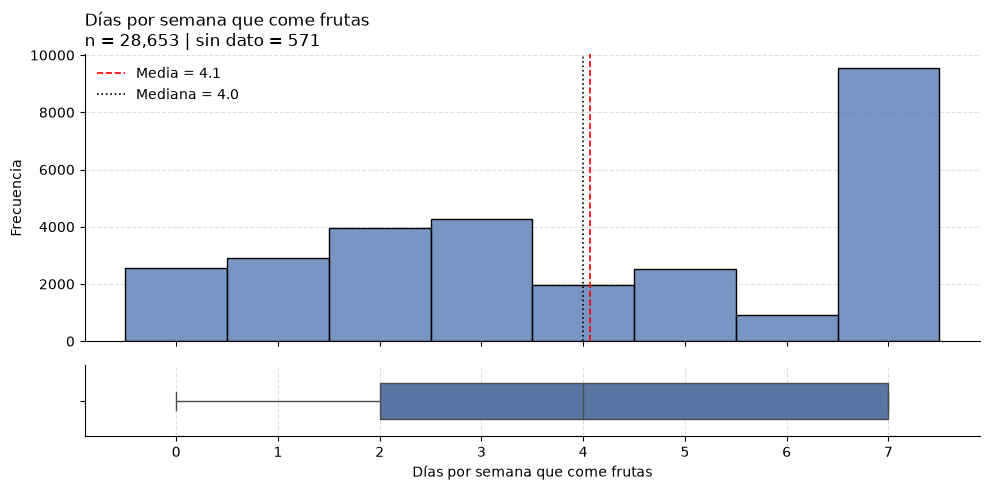

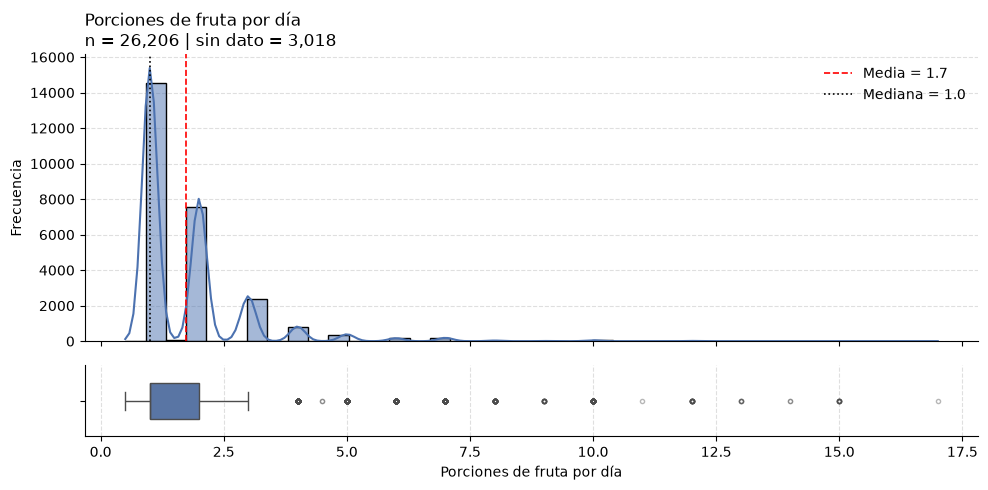

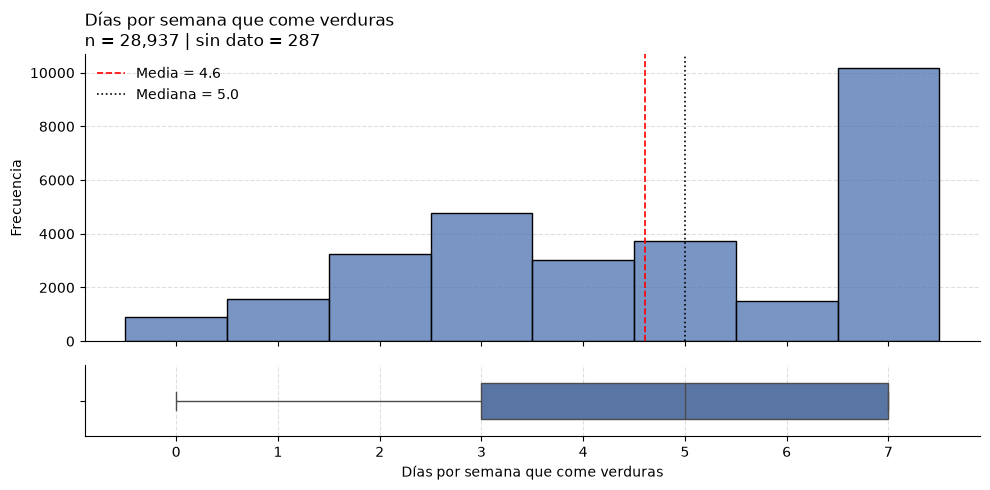

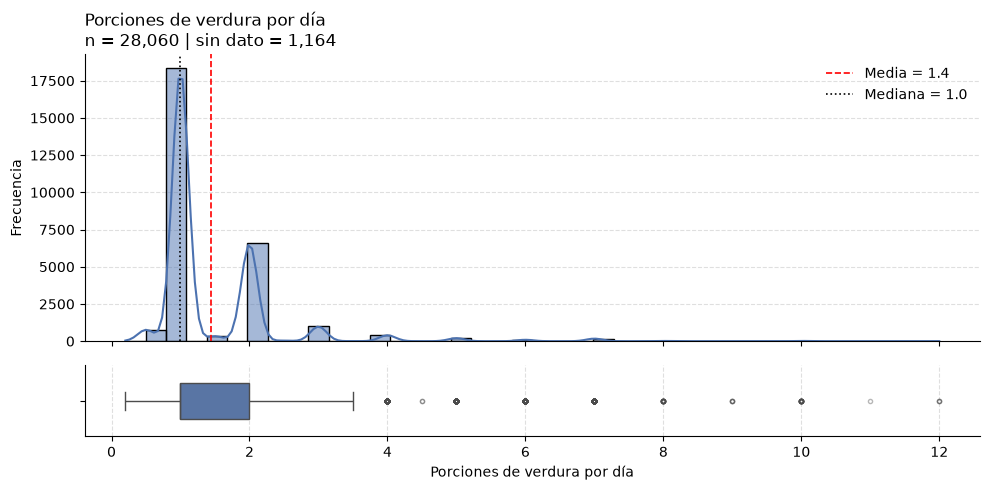

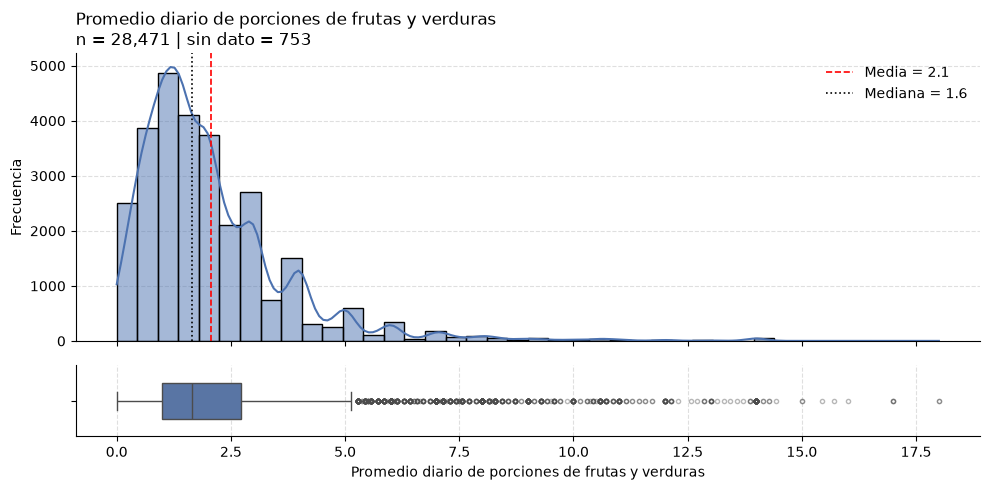

...

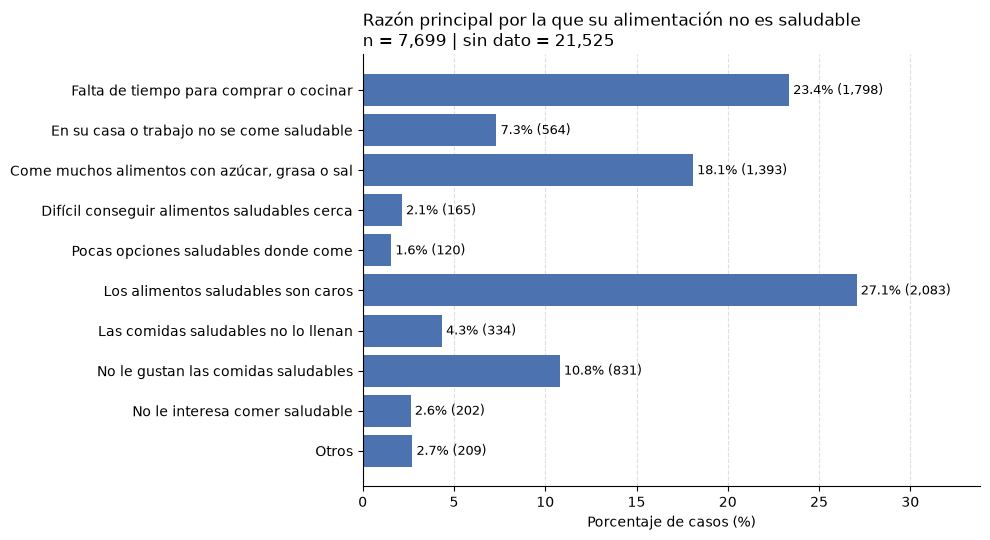

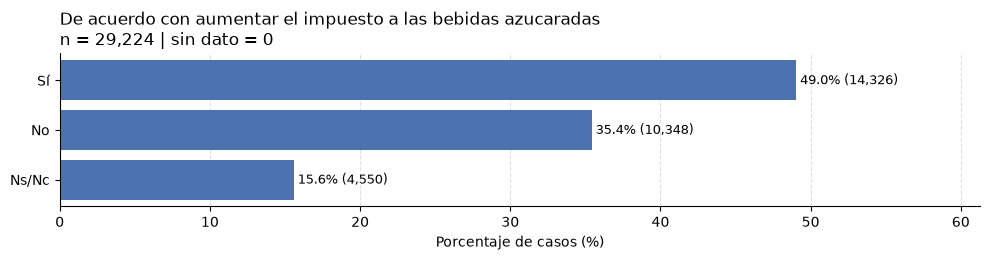

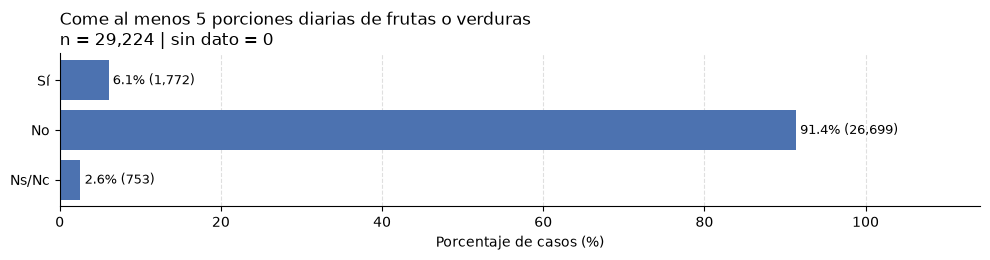

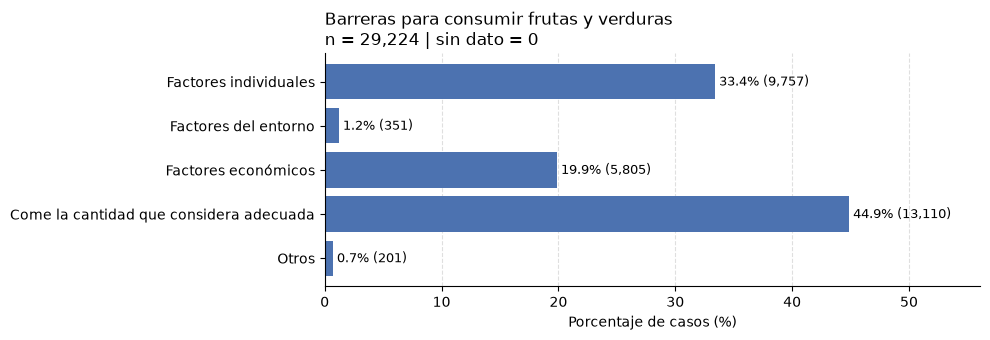

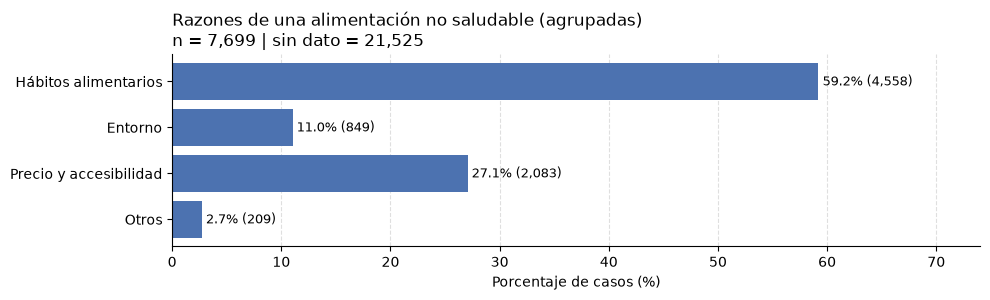

In [30]:
frecuencias_sal = {1: "Siempre o casi siempre",  2: "Raras veces",
                   3: "Nunca"
}

razones_pocas_fyv = {1: "Come la cantidad que considera adecuada",  2: "Comprarlas y prepararlas lleva tiempo",
                     3: "Pocas opciones en lugares de compra",      4: "Pocas opciones en lugares para comer",
                     5: "Son caras",                                6: "Falta de apoyo del entorno",
                     7: "No le gustan",                             8: "Prefiere otro tipo de comidas",
                     9: "Hábitos y exigencias de la vida cotidiana", 10: "Falta de voluntad",
                     11: "Otros",                                   12: "Código 12 (no documentado)",
                     13: "Código 13 (no documentado)"
}

valoraciones_dieta = {1: "Muy saludable",  2: "Bastante saludable",
                      3: "Poco saludable", 4: "Nada saludable",
                      99: "Ns/Nc"
}

razones_dieta = {1: "Falta de tiempo para comprar o cocinar",       2: "En su casa o trabajo no se come saludable",
                 3: "Come muchos alimentos con azúcar, grasa o sal", 4: "Difícil conseguir alimentos saludables cerca",
                 5: "Pocas opciones saludables donde come",          6: "Los alimentos saludables son caros",
                 7: "Las comidas saludables no lo llenan",           8: "No le gustan las comidas saludables",
                 9: "No le interesa comer saludable",                10: "Otros"
}

barreras_fyv = {1: "Factores individuales",       2: "Factores del entorno",
                3: "Factores económicos",         4: "Come la cantidad que considera adecuada",
                5: "Otros"
}

razones_dieta_agrupadas = {1: "Hábitos alimentarios",    2: "Entorno",
                           3: "Precio y accesibilidad",  4: "Otros"
}

# Los códigos 12 y 13 de bial07 no están ni en el diccionario ni en el cuestionario
variables_138 = {
    "bial01": ("Agrega sal durante la cocción", si_no_nsnc),
    "bial02": ("Agrega sal una vez cocida la comida o en la mesa", frecuencias_sal),
    "bial07": ("Razón principal para no comer más frutas y verduras", razones_pocas_fyv),
    "bial08": ("Valoración de la propia alimentación", valoraciones_dieta),
    "bial09": ("Razón principal por la que su alimentación no es saludable", razones_dieta),
    "bial10": ("De acuerdo con aumentar el impuesto a las bebidas azucaradas", si_no_nsnc),
    "consumo_fv": ("Come al menos 5 porciones diarias de frutas o verduras", si_no_nsnc),
    "barreras_fyv": ("Barreras para consumir frutas y verduras", barreras_fyv),
    "tipo_dieta_razones": ("Razones de una alimentación no saludable (agrupadas)", razones_dieta_agrupadas),
}

graficar_variable(raw_data_alimentacion["bial03"], "Días por semana que come frutas", tipo="discreta")
graficar_variable(raw_data_alimentacion["bial04"], "Porciones de fruta por día", tipo="continua")
graficar_variable(raw_data_alimentacion["bial05"], "Días por semana que come verduras", tipo="discreta")
graficar_variable(raw_data_alimentacion["bial06"], "Porciones de verdura por día", tipo="continua")
graficar_variable(raw_data_alimentacion["promedio_fv_diario"], "Promedio diario de porciones de frutas y verduras", tipo="continua")

for col, (titulo, etiquetas) in variables_138.items():
    graficar_variable(raw_data_alimentacion[col], titulo, tipo="categorica", etiquetas=etiquetas)

### 1.3.9 Colesterol

In [31]:
columnas = [
    "id",
    "bico01",
    "bico02",
    "bico03",
    "bico04",
    "bico05_01",
    "bico05_02",
    "control_colesterol",
    "prevalencia_colesterol",
]
raw_data_colesterol = raw_data[columnas]
raw_data_colesterol.head(5)

,id,bico01,bico02,bico03,bico04,bico05_01,bico05_02,control_colesterol,prevalencia_colesterol
0,1128639,1,2.0,2,NaN,NaN,NaN,NaN,2.0
1,1709939,1,2.0,1,2.0,NaN,NaN,1.0,1.0
2,6874130,1,2.0,2,NaN,NaN,NaN,NaN,2.0
3,10319375,1,2.0,1,1.0,2.0,1.0,1.0,1.0
4,11140857,1,1.0,2,NaN,NaN,NaN,NaN,2.0


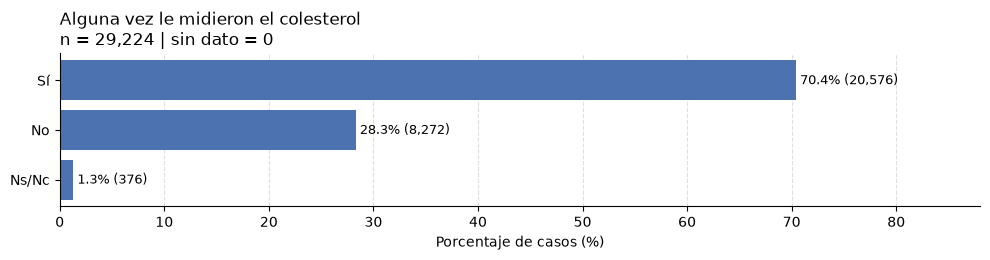

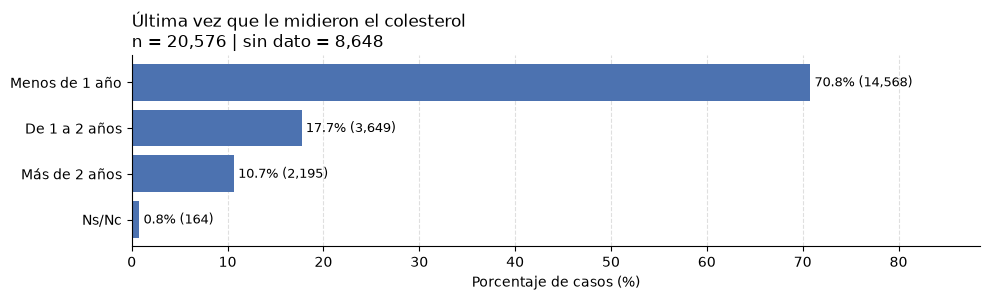

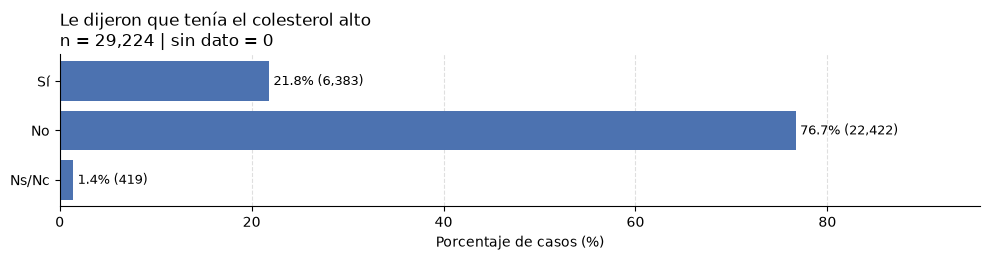

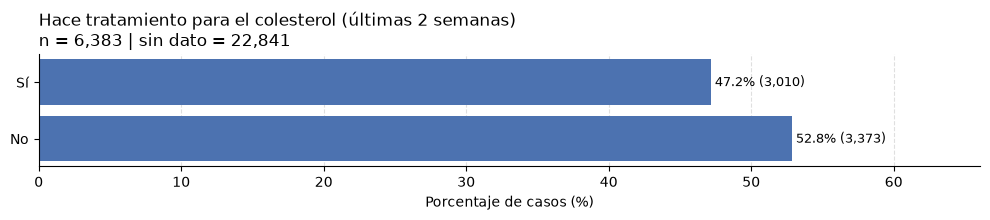

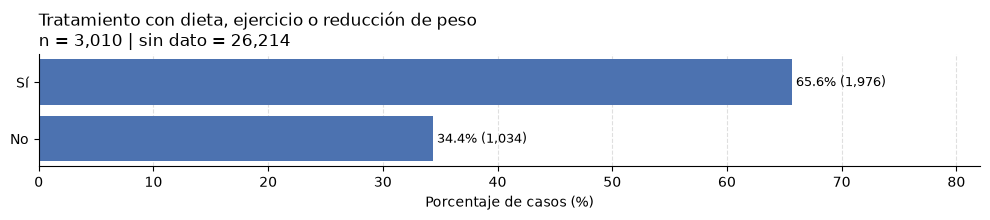

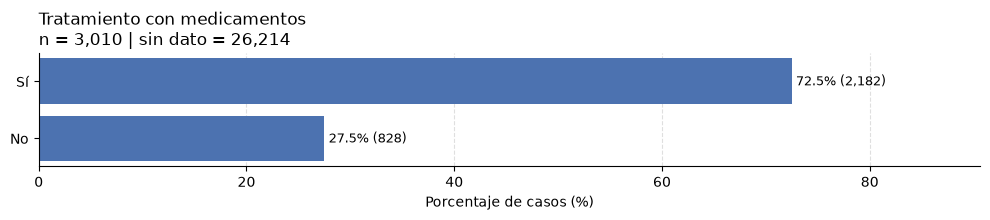

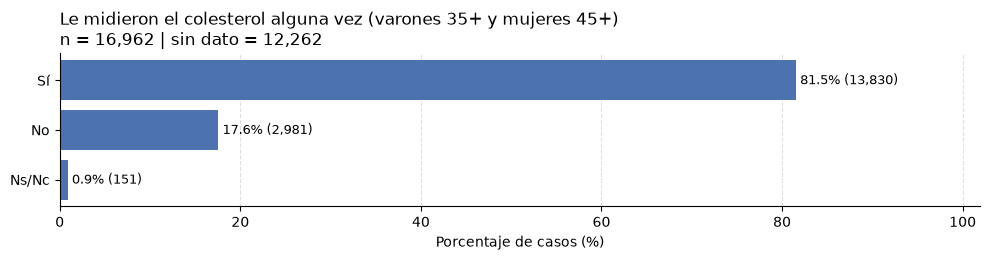

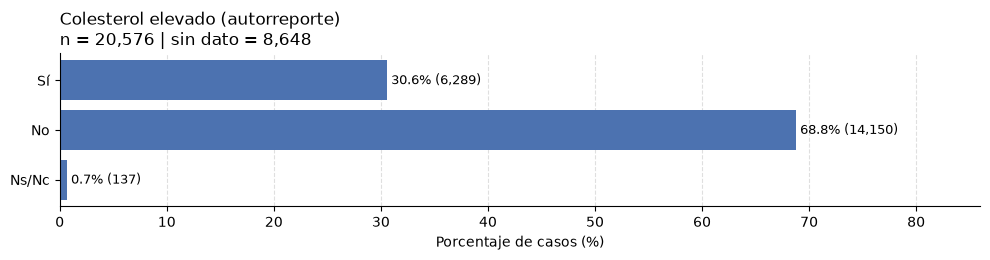

In [32]:
variables_139 = {
    "bico01": ("Alguna vez le midieron el colesterol", si_no_nsnc),
    "bico02": ("Última vez que le midieron el colesterol", ultimas_mediciones),
    "bico03": ("Le dijeron que tenía el colesterol alto", si_no_nsnc),
    "bico04": ("Hace tratamiento para el colesterol (últimas 2 semanas)", si_no),
    "bico05_01": ("Tratamiento con dieta, ejercicio o reducción de peso", si_no),
    "bico05_02": ("Tratamiento con medicamentos", si_no),
    "control_colesterol": ("Le midieron el colesterol alguna vez (varones 35+ y mujeres 45+)", si_no_nsnc),
    "prevalencia_colesterol": ("Colesterol elevado (autorreporte)", si_no_nsnc),
}

for col, (titulo, etiquetas) in variables_139.items():
    graficar_variable(raw_data_colesterol[col], titulo, tipo="categorica", etiquetas=etiquetas)

### 1.3.10 Consumo de alcohol

In [33]:
columnas = [
    "id",
    "bica01",
    "bica02",
    "bica03_01",
    "bica03_02",
    "bica03_99",
    "bica04_01_b",
    "bica04_01_c",
    "bica04_02_b",
    "bica04_02_c",
    "bica04_03_b",
    "bica04_03_c",
    "bica04_04",
    "bica05_01_b",
    "bica05_01_c",
    "bica05_02_b",
    "bica05_02_c",
    "bica05_03_b",
    "bica05_03_c",
    "bica05_04",
    "bica06",
    "bica07",
    "consumo_regular_riesgo",
    "consumo_episodico_excesivo",
]
raw_data_alcohol = raw_data[columnas]
raw_data_alcohol.head(5)

,id,bica01,bica02,bica03_01,bica03_02,bica03_99,bica04_01_b,bica04_01_c,bica04_02_b,bica04_02_c,...,bica05_01_c,bica05_02_b,bica05_02_c,bica05_03_b,bica05_03_c,bica05_04,bica06,bica07,consumo_regular_riesgo,consumo_episodico_excesivo
0,1128639,1,1.0,1.0,NaN,NaN,1.0,NaN,NaN,98.0,...,NaN,1.0,NaN,NaN,98.0,2.0,2.0,2,2.0,2.0
1,1709939,1,1.0,NaN,1.0,NaN,NaN,98.0,1.0,NaN,...,98.0,NaN,98.0,NaN,98.0,2.0,2.0,2,2.0,2.0
2,6874130,1,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,2.0,2.0
3,10319375,1,3.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,2.0,2.0
4,11140857,1,1.0,1.0,NaN,NaN,1.5,NaN,NaN,98.0,...,98.0,NaN,98.0,NaN,98.0,2.0,2.0,99,2.0,2.0


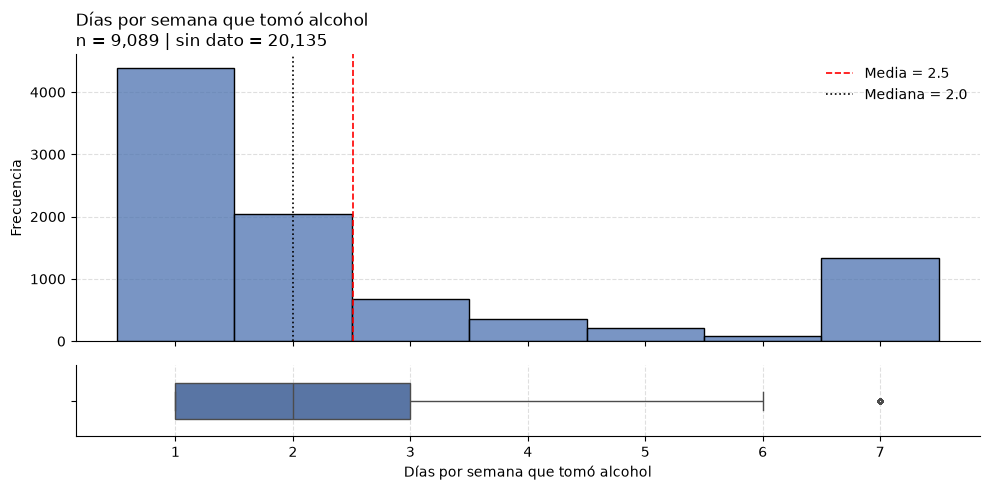

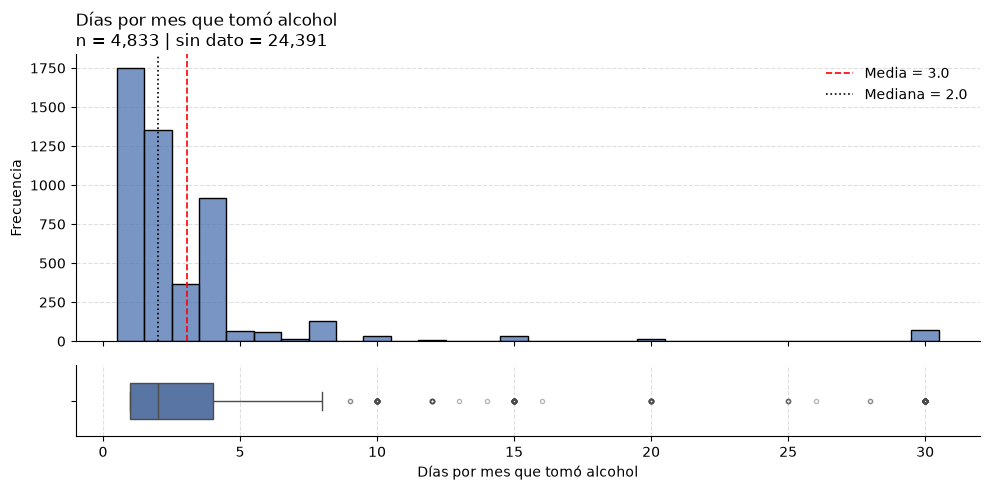

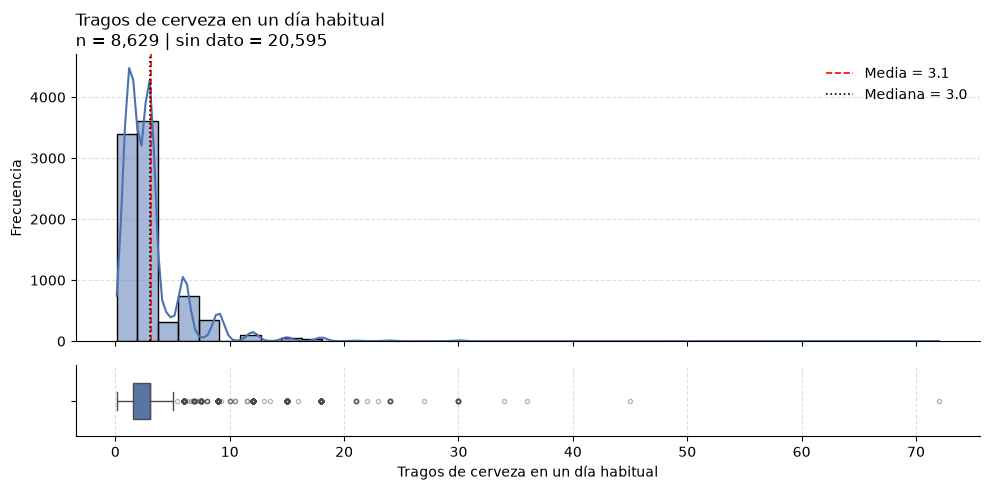

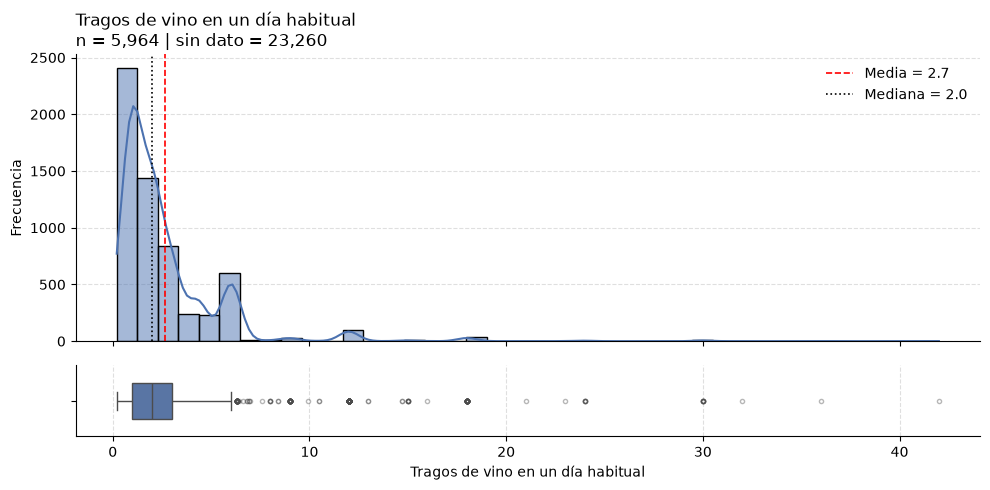

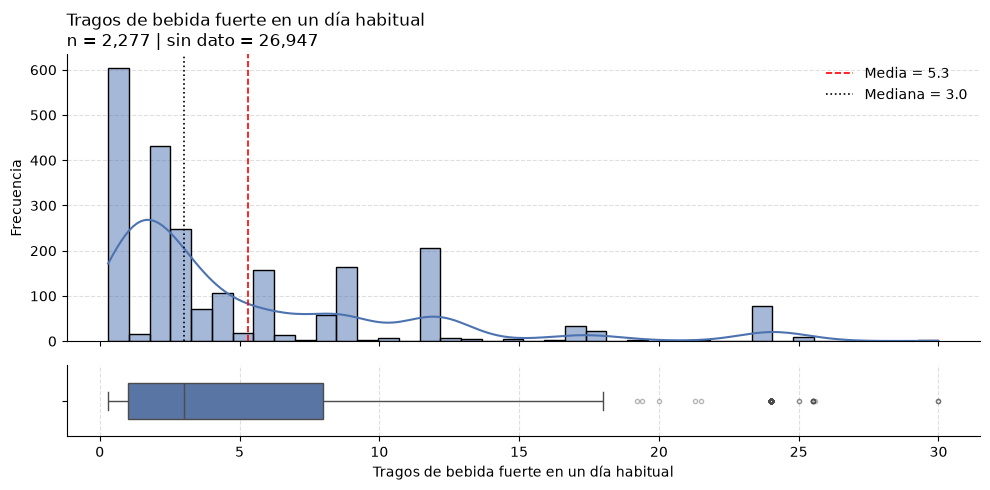

...

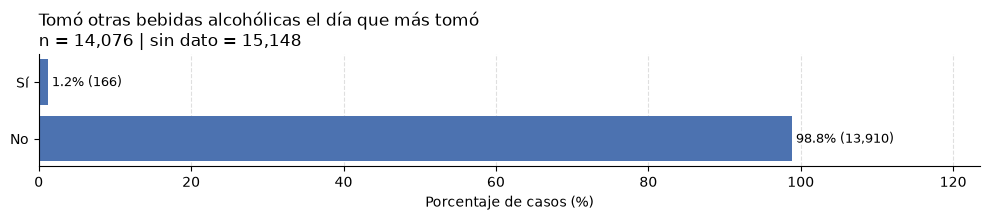

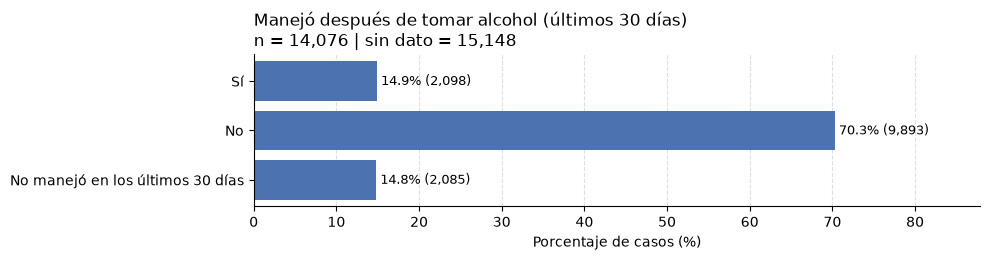

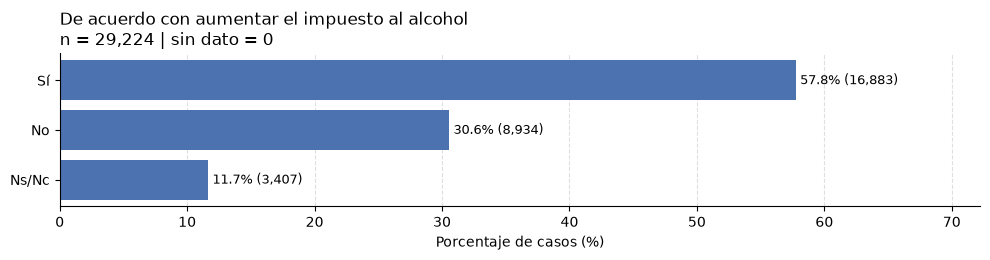

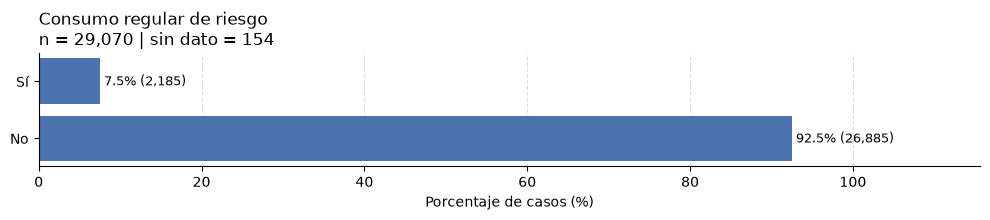

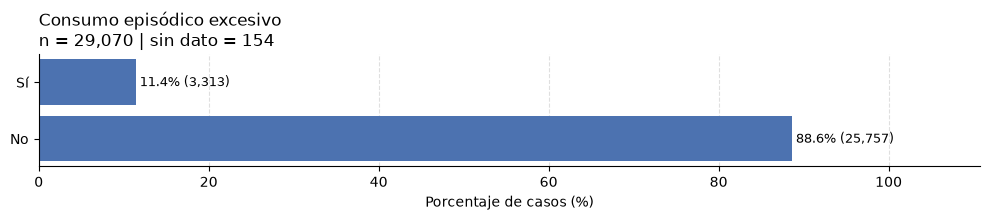

In [34]:
ultimos_consumos = {1: "Durante los últimos 30 días",      2: "Hace más de un mes, hasta un año",
                    3: "Hace más de un año",               99: "Ns/Nc"
}

si_no_manejo = {1: "Sí",  2: "No",
                98: "No manejó en los últimos 30 días"
}

# bica04 es un día habitual y bica05 el día que más tomó en los últimos 30 días (según el cuestionario).
# Las columnas _c (98 = no toma) y _99 (Ns/Nc) solo marcan la respuesta, así que no se grafican.
variables_1310 = {
    "bica01": ("Tomó alcohol alguna vez", si_no_nsnc),
    "bica02": ("Última vez que tomó alcohol", ultimos_consumos),
    "bica04_04": ("Toma otras bebidas alcohólicas en un día habitual", si_no),
    "bica05_04": ("Tomó otras bebidas alcohólicas el día que más tomó", si_no),
    "bica06": ("Manejó después de tomar alcohol (últimos 30 días)", si_no_manejo),
    "bica07": ("De acuerdo con aumentar el impuesto al alcohol", si_no_nsnc),
    "consumo_regular_riesgo": ("Consumo regular de riesgo", si_no),
    "consumo_episodico_excesivo": ("Consumo episódico excesivo", si_no),
}

graficar_variable(raw_data_alcohol["bica03_01"], "Días por semana que tomó alcohol", tipo="discreta")
graficar_variable(raw_data_alcohol["bica03_02"], "Días por mes que tomó alcohol", tipo="discreta")
graficar_variable(raw_data_alcohol["bica04_01_b"], "Tragos de cerveza en un día habitual", tipo="continua")
graficar_variable(raw_data_alcohol["bica04_02_b"], "Tragos de vino en un día habitual", tipo="continua")
graficar_variable(raw_data_alcohol["bica04_03_b"], "Tragos de bebida fuerte en un día habitual", tipo="continua")
graficar_variable(raw_data_alcohol["bica05_01_b"], "Tragos de cerveza el día que más tomó", tipo="continua")
graficar_variable(raw_data_alcohol["bica05_02_b"], "Tragos de vino el día que más tomó", tipo="continua")
graficar_variable(raw_data_alcohol["bica05_03_b"], "Tragos de bebida fuerte el día que más tomó", tipo="continua")

for col, (titulo, etiquetas) in variables_1310.items():
    graficar_variable(raw_data_alcohol[col], titulo, tipo="categorica", etiquetas=etiquetas)

### 1.3.11 Diabetes

In [35]:
columnas = [
    "id",
    "bidi01",
    "bidi02",
    "bidi03",
    "bidi04_01",
    "bidi04_02",
    "bidi04_03",
    "bidi05",
    "bidi06_01",
    "bidi06_02",
    "bidi07",
    "bidi08",
    "bidi09",
    "bidi10",
    "bidi11",
    "bidi12",
    "bidi13",
    "bidi14",
    "control_diabetes",
    "prevalencia_diabetes",
]
raw_data_diabetes = raw_data[columnas]
raw_data_diabetes.head(5)

,id,bidi01,bidi02,bidi03,bidi04_01,bidi04_02,bidi04_03,bidi05,bidi06_01,bidi06_02,bidi07,bidi08,bidi09,bidi10,bidi11,bidi12,bidi13,bidi14,control_diabetes,prevalencia_diabetes
0,1128639,2,NaN,NaN,NaN,NaN,NaN,NaN,2,2,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,2
1,1709939,2,NaN,NaN,NaN,NaN,NaN,NaN,2,2,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,2
2,6874130,2,NaN,NaN,NaN,NaN,NaN,NaN,2,2,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,2
3,10319375,2,NaN,NaN,NaN,NaN,NaN,NaN,2,1,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,2
4,11140857,2,NaN,NaN,NaN,NaN,NaN,NaN,2,99,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,2


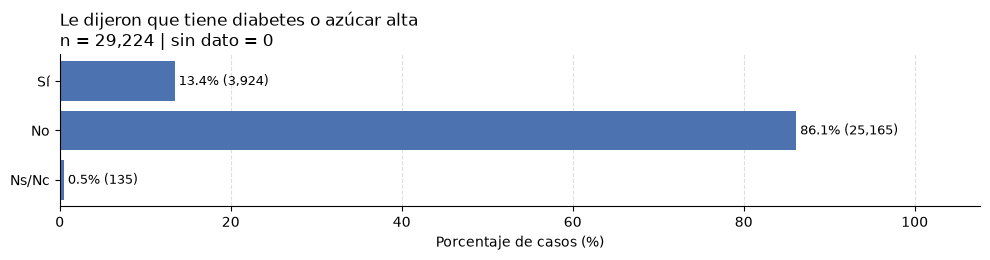

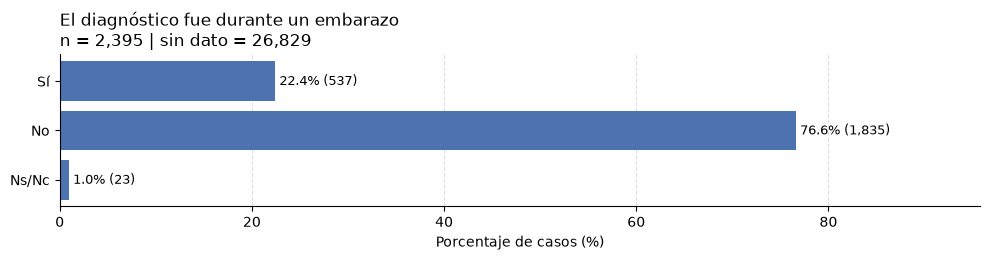

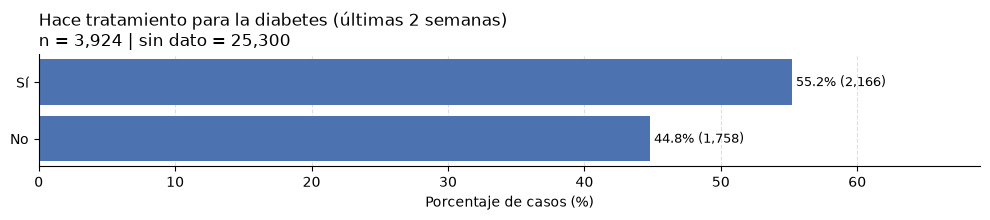

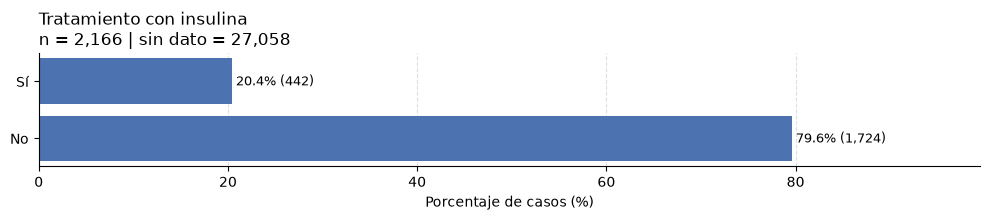

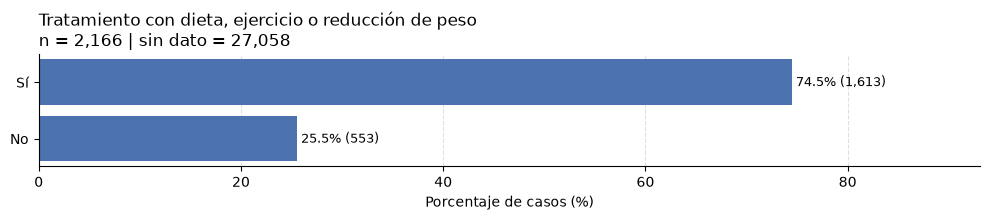

...

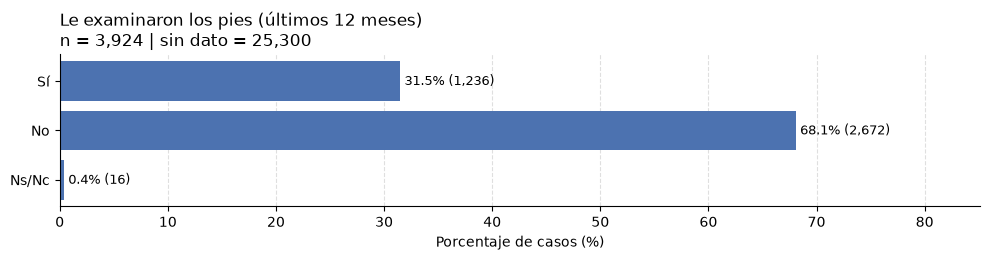

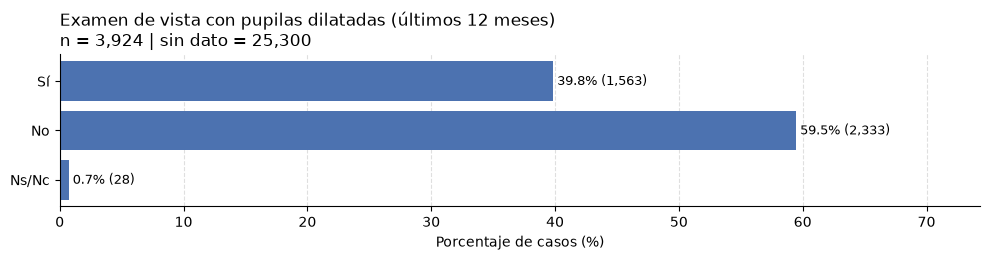

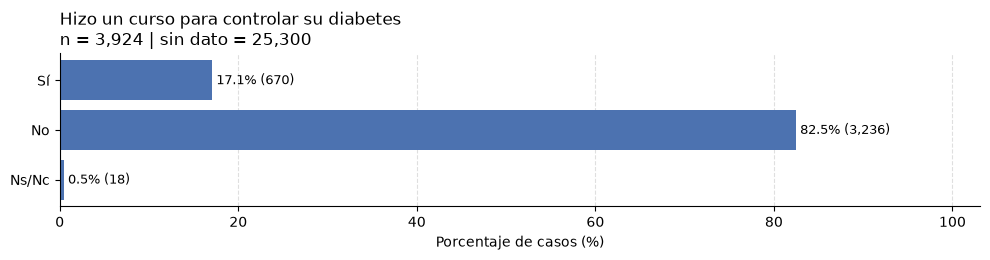

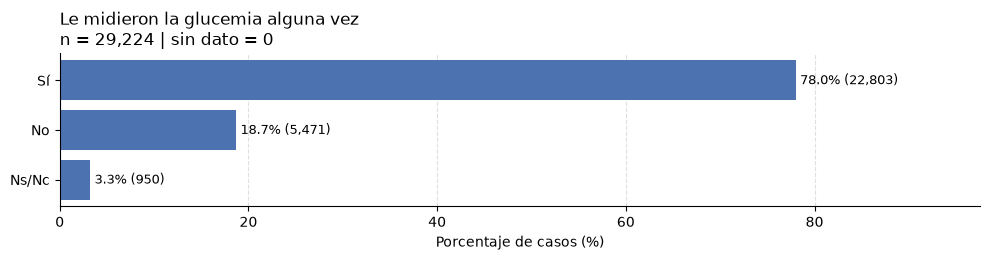

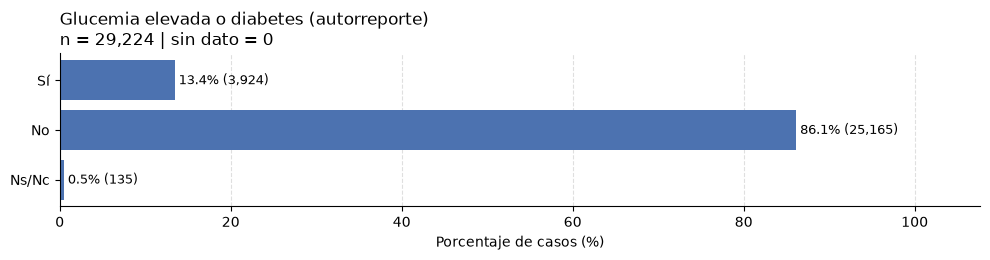

In [36]:
ultimas_glucemias = {1: "Menos de 1 año",     2: "De 1 a 2 años",
                     3: "Más de 2 años",      4: "Nunca se la midió",
                     99: "Ns/Nc"
}

variables_1311 = {
    "bidi01": ("Le dijeron que tiene diabetes o azúcar alta", si_no_nsnc),
    "bidi02": ("El diagnóstico fue durante un embarazo", si_no_nsnc),
    "bidi03": ("Hace tratamiento para la diabetes (últimas 2 semanas)", si_no),
    "bidi04_01": ("Tratamiento con insulina", si_no),
    "bidi04_02": ("Tratamiento con dieta, ejercicio o reducción de peso", si_no),
    "bidi04_03": ("Tratamiento con medicamentos", si_no),
    "bidi05": ("Es insulinodependiente", si_no),
    "bidi06_01": ("Diabetes en familiares directos", si_no_nsnc),
    "bidi06_02": ("Diabetes en otros familiares", si_no_nsnc),
    "bidi07": ("Última vez que le midieron la glucemia", ultimas_glucemias),
    "bidi08": ("Tiene un lugar habitual de control de la diabetes", si_no),
    "bidi09": ("Lugar habitual de control de la diabetes", lugares_control),
    "bidi10": ("Lo atiende siempre el mismo profesional", si_no_nsnc),
    "bidi11": ("El profesional conoce su historia clínica", si_no_nsnc),
    "bidi12": ("Le examinaron los pies (últimos 12 meses)", si_no_nsnc),
    "bidi13": ("Examen de vista con pupilas dilatadas (últimos 12 meses)", si_no_nsnc),
    "bidi14": ("Hizo un curso para controlar su diabetes", si_no_nsnc),
    "control_diabetes": ("Le midieron la glucemia alguna vez", si_no_nsnc),
    "prevalencia_diabetes": ("Glucemia elevada o diabetes (autorreporte)", si_no_nsnc),
}

for col, (titulo, etiquetas) in variables_1311.items():
    graficar_variable(raw_data_diabetes[col], titulo, tipo="categorica", etiquetas=etiquetas)

### 1.3.12 Lesiones

In [37]:
columnas = [ "id", "bile01",
    "bile02",
    "bile03", ]

raw_data_lesiones = raw_data[columnas]
raw_data_lesiones.head(5)

,id,bile01,bile02,bile03
0,1128639,1,98,1
1,1709939,98,98,1
2,6874130,98,1,1
3,10319375,98,98,1
4,11140857,98,98,1


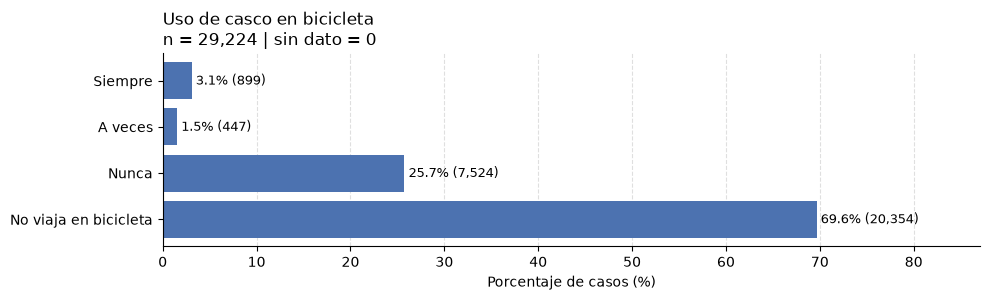

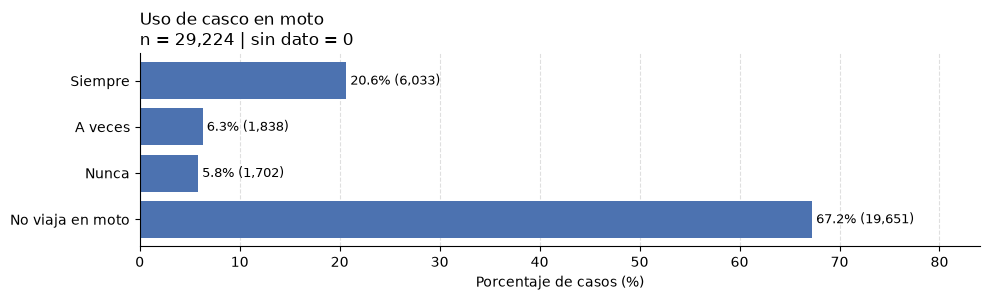

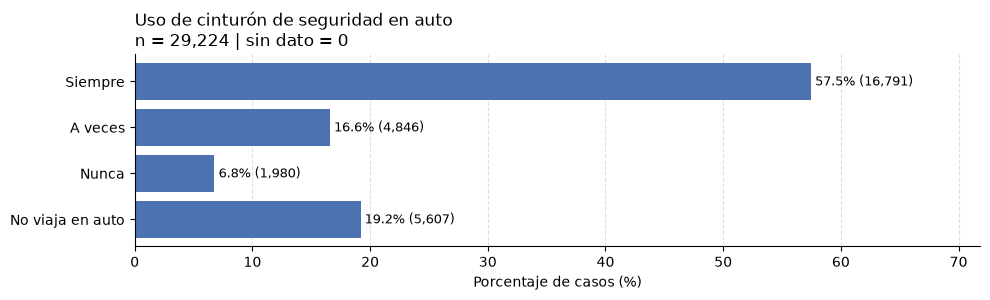

In [38]:
cascos_bicicleta = {1: "Siempre",  2: "A veces",
                    3: "Nunca",    98: "No viaja en bicicleta"
}

cascos_moto = {1: "Siempre",  2: "A veces",
               3: "Nunca",    98: "No viaja en moto"
}

cinturones = {1: "Siempre",  2: "A veces",
              3: "Nunca",    98: "No viaja en auto"
}

variables_1312 = {
    "bile01": ("Uso de casco en bicicleta", cascos_bicicleta),
    "bile02": ("Uso de casco en moto", cascos_moto),
    "bile03": ("Uso de cinturón de seguridad en auto", cinturones),
}

for col, (titulo, etiquetas) in variables_1312.items():
    graficar_variable(raw_data_lesiones[col], titulo, tipo="categorica", etiquetas=etiquetas)

### 1.3.13 Prácticas preventivas

In [39]:
columnas = [
    "id",
    "bipp01",
    "bipp02",
    "bipp03",
    "bipp04",
    "control_mamografia",
    "control_pap",
]
raw_data_practicas_preventivas = raw_data[columnas]
raw_data_practicas_preventivas.head(5)

,id,bipp01,bipp02,bipp03,bipp04,control_mamografia,control_pap
0,1128639,NaN,NaN,NaN,NaN,NaN,NaN
1,1709939,1.0,1.0,1.0,1.0,1.0,1.0
2,6874130,2.0,NaN,1.0,1.0,2.0,1.0
3,10319375,1.0,3.0,1.0,2.0,2.0,1.0
4,11140857,NaN,NaN,NaN,NaN,NaN,NaN


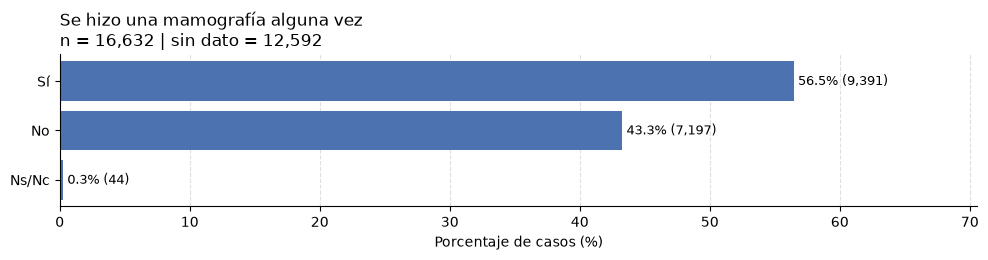

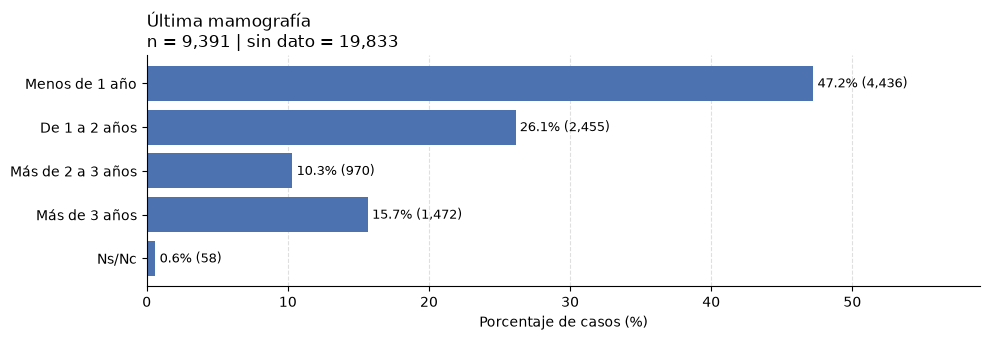

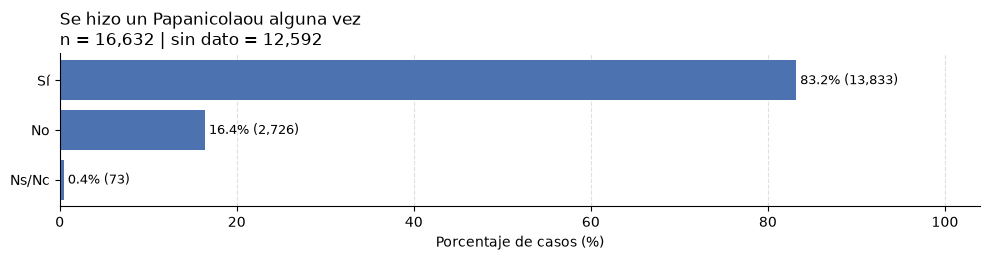

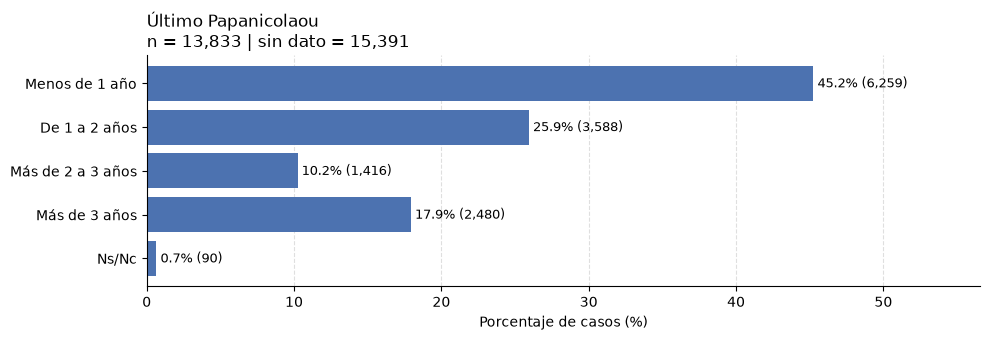

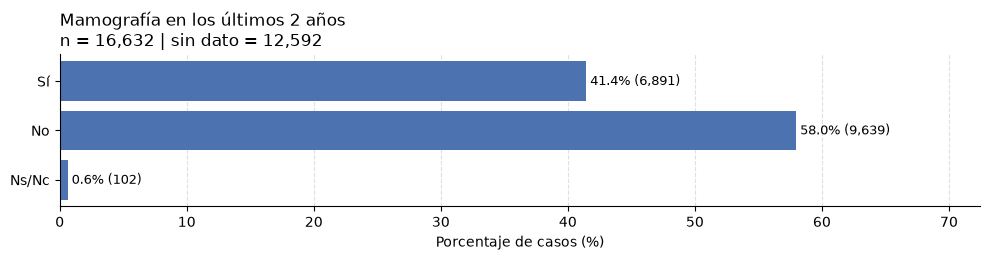

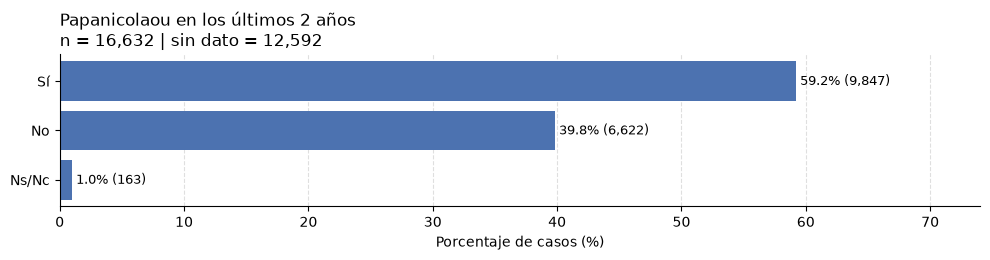

In [40]:
ultimos_estudios = {1: "Menos de 1 año",     2: "De 1 a 2 años",
                    3: "Más de 2 a 3 años",  4: "Más de 3 años",
                    99: "Ns/Nc"
}

variables_1313 = {
    "bipp01": ("Se hizo una mamografía alguna vez", si_no_nsnc),
    "bipp02": ("Última mamografía", ultimos_estudios),
    "bipp03": ("Se hizo un Papanicolaou alguna vez", si_no_nsnc),
    "bipp04": ("Último Papanicolaou", ultimos_estudios),
    "control_mamografia": ("Mamografía en los últimos 2 años", si_no_nsnc),
    "control_pap": ("Papanicolaou en los últimos 2 años", si_no_nsnc),
}

for col, (titulo, etiquetas) in variables_1313.items():
    graficar_variable(raw_data_practicas_preventivas[col], titulo, tipo="categorica", etiquetas=etiquetas)

### 1.3.14 Prevención del cáncer colorrectal

In [41]:
columnas = [
    "id",
    "bicc01_01",
    "bicc01_02",
    "bicc01_03",
    "bicc02",
    "bicc03",
    "control_colon",
]
raw_data_cancer_colorrectal = raw_data[columnas]
raw_data_cancer_colorrectal.head(5)

,id,bicc01_01,bicc01_02,bicc01_03,bicc02,bicc03,control_colon
0,1128639,NaN,NaN,NaN,NaN,NaN,NaN
1,1709939,2.0,1.0,2.0,2.0,3.0,1.0
2,6874130,NaN,NaN,NaN,NaN,NaN,NaN
3,10319375,2.0,1.0,2.0,2.0,1.0,1.0
4,11140857,NaN,NaN,NaN,NaN,NaN,NaN


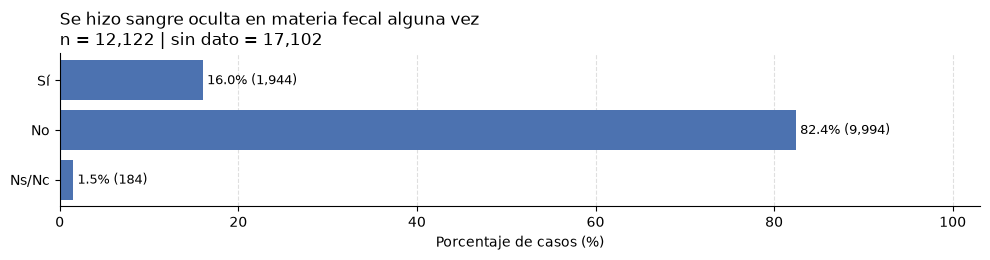

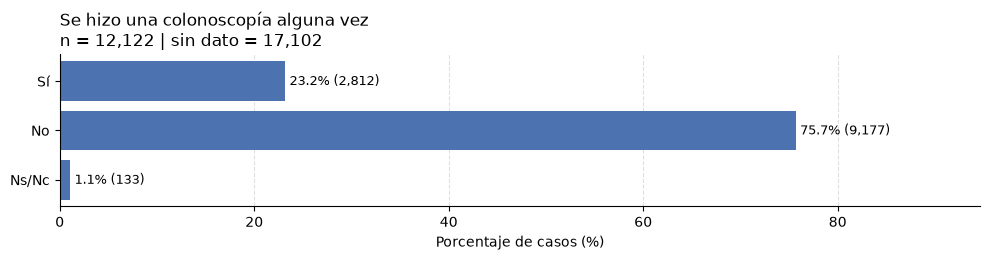

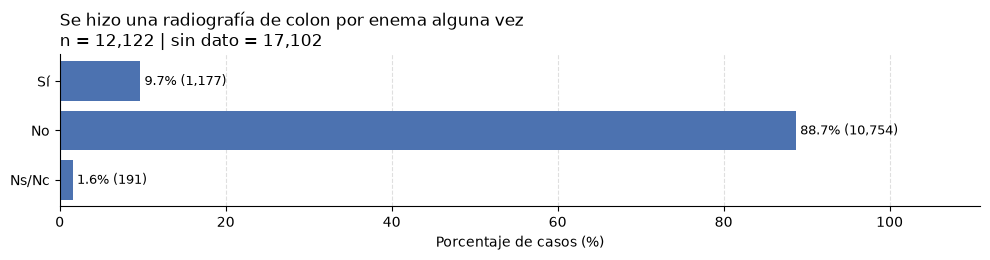

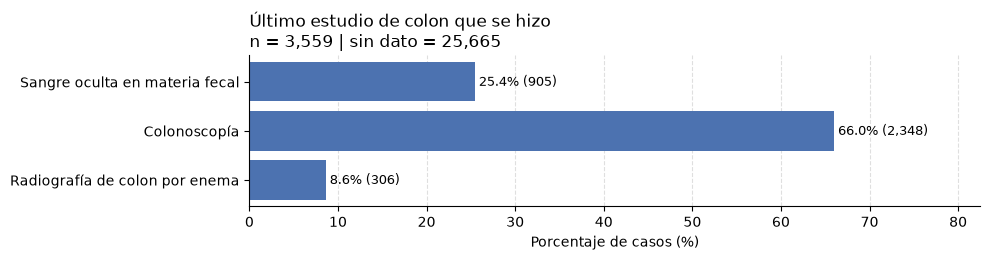

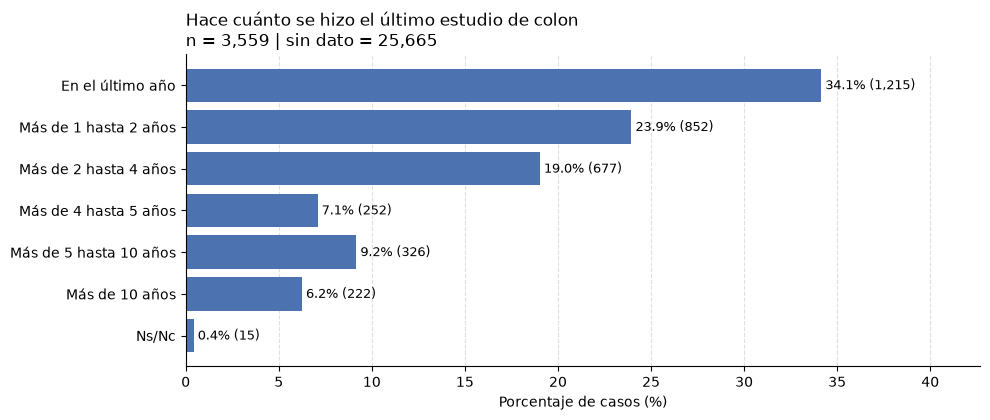

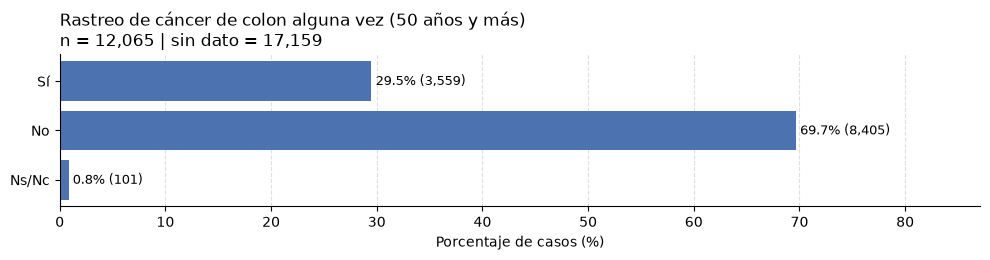

In [42]:
estudios_colon = {1: "Sangre oculta en materia fecal",  2: "Colonoscopía",
                  3: "Radiografía de colon por enema"
}

antiguedades_estudio = {1: "En el último año",        2: "Más de 1 hasta 2 años",
                        3: "Más de 2 hasta 4 años",   4: "Más de 4 hasta 5 años",
                        5: "Más de 5 hasta 10 años",  6: "Más de 10 años",
                        99: "Ns/Nc"
}

variables_1314 = {
    "bicc01_01": ("Se hizo sangre oculta en materia fecal alguna vez", si_no_nsnc),
    "bicc01_02": ("Se hizo una colonoscopía alguna vez", si_no_nsnc),
    "bicc01_03": ("Se hizo una radiografía de colon por enema alguna vez", si_no_nsnc),
    "bicc02": ("Último estudio de colon que se hizo", estudios_colon),
    "bicc03": ("Hace cuánto se hizo el último estudio de colon", antiguedades_estudio),
    "control_colon": ("Rastreo de cáncer de colon alguna vez (50 años y más)", si_no_nsnc),
}

for col, (titulo, etiquetas) in variables_1314.items():
    graficar_variable(raw_data_cancer_colorrectal[col], titulo, tipo="categorica", etiquetas=etiquetas)

### 1.3.15 Mediciones antropométricas

In [43]:
columnas = [
    "id",
    "bima01",
    "bima02",
    "bima03",
    "bima04_01_a",
    "bima04_01_b",
    "bima04_02_a",
    "bima04_02_b",
    "bima04_03_a",
    "bima04_03_b",
    "promedio_sistolica",
    "promedio_diastolica",
    "ta_elevada",
    "prevalencia_hipertension_combinada",
    "bima06",
    "bima07",
    "bima09",
    "bima10",
    "imc_bima",
    "imc_categorias_bima",
    "bima12",
    "bima13",
    "bima14",
]

raw_data_mediciones_antro = raw_data[columnas]
raw_data_mediciones_antro.head(5)

,id,bima01,bima02,bima03,bima04_01_a,bima04_01_b,bima04_02_a,bima04_02_b,bima04_03_a,bima04_03_b,...,prevalencia_hipertension_combinada,bima06,bima07,bima09,bima10,imc_bima,imc_categorias_bima,bima12,bima13,bima14
0,1128639,1.0,2.0,1.0,151.0,99.0,147.0,100.0,148.0,97.0,...,1.0,1.0,181.0,1.0,106.0,32.36,3.0,1.0,103.0,2.0
1,1709939,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,6874130,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,10319375,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,11140857,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


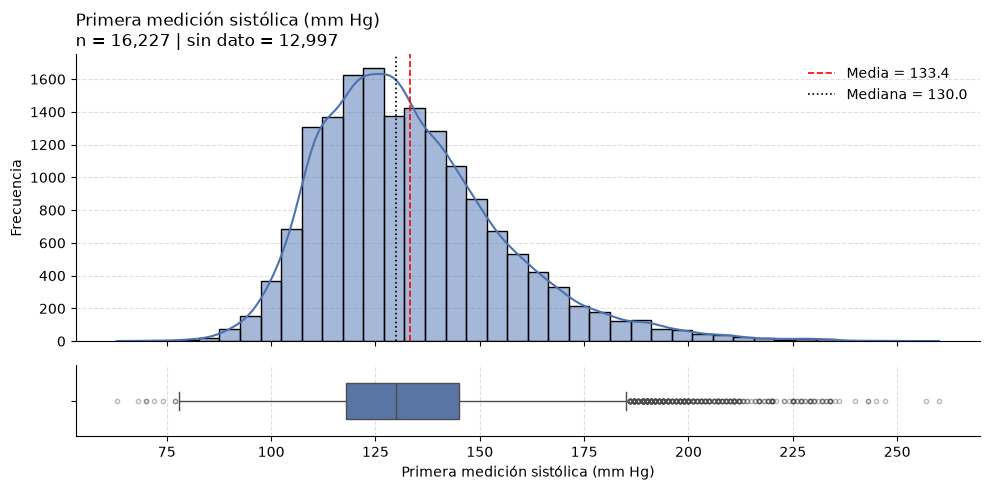

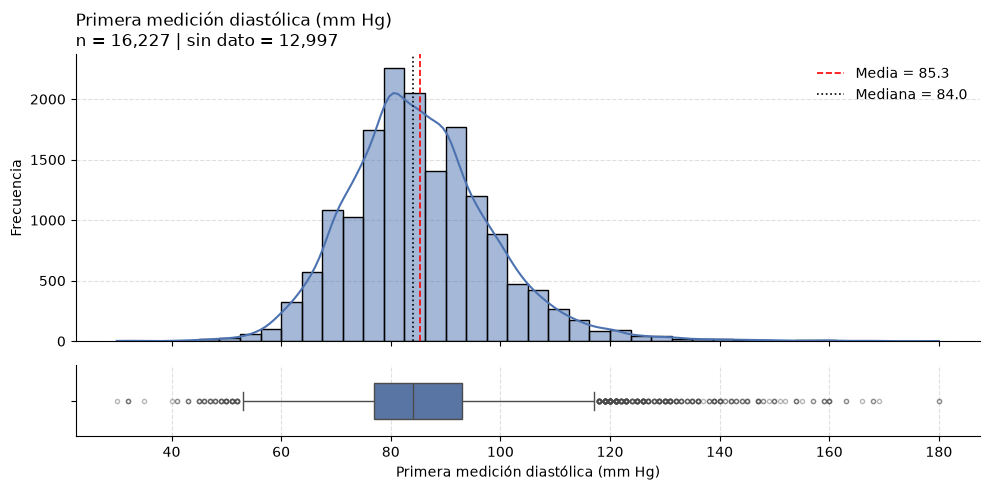

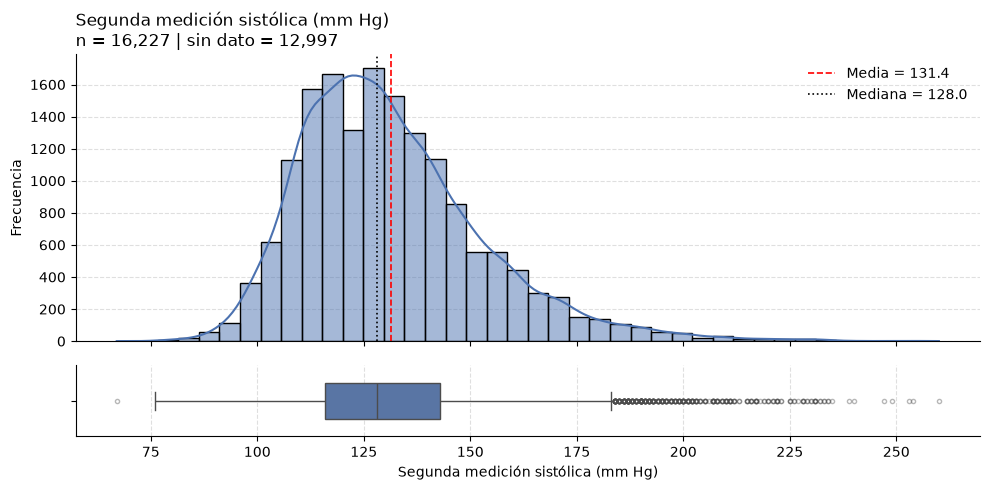

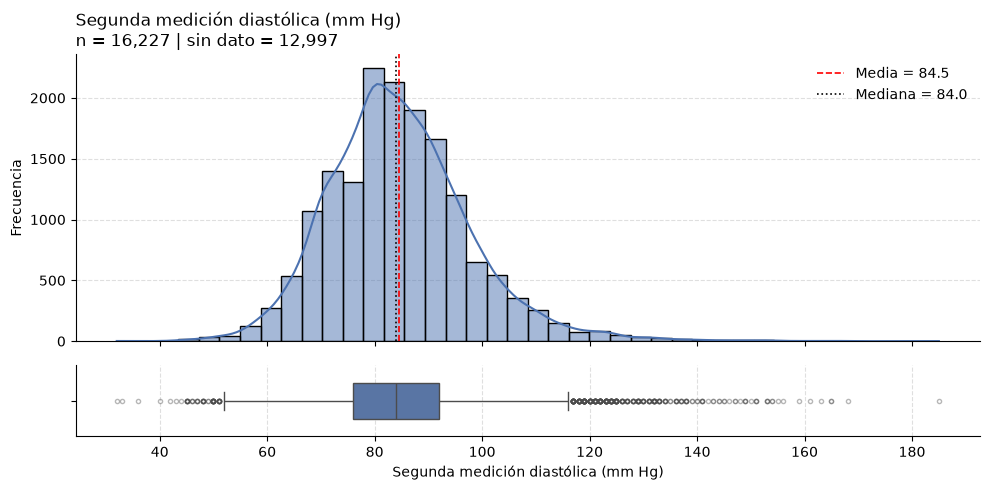

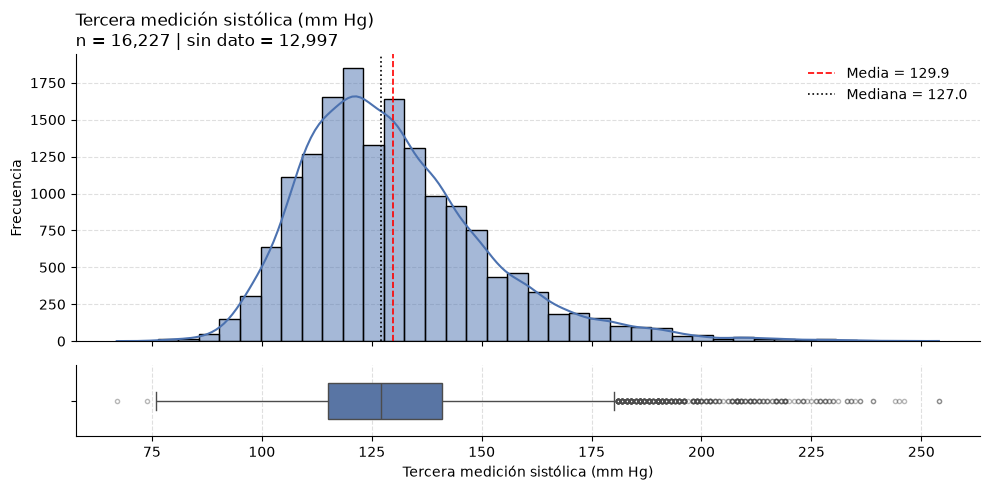

...

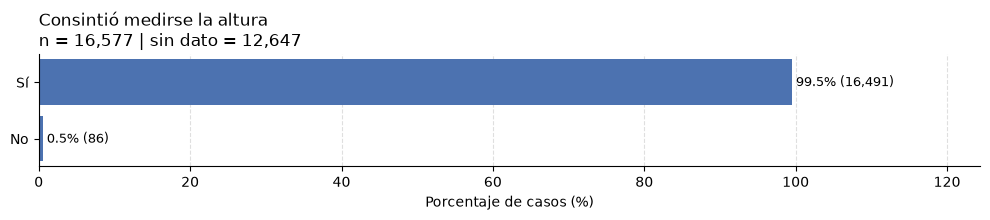

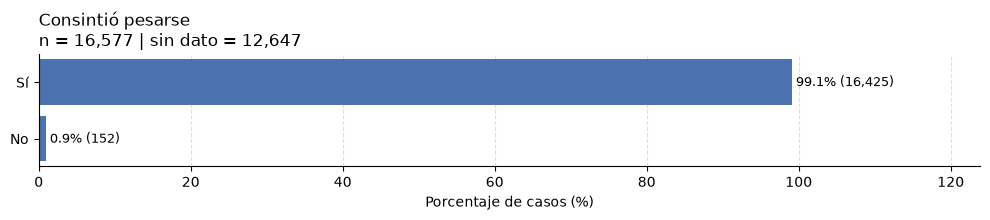

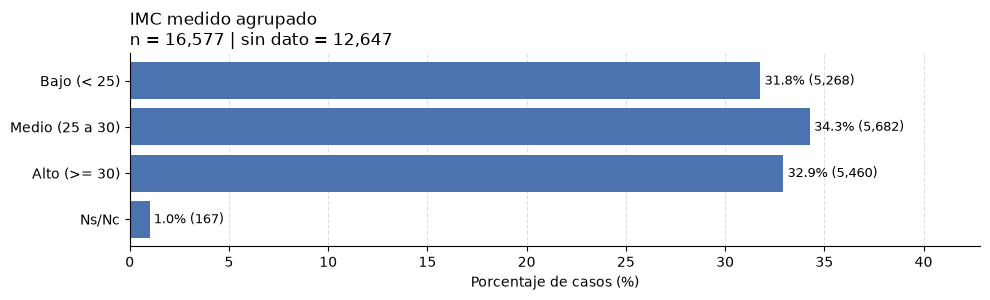

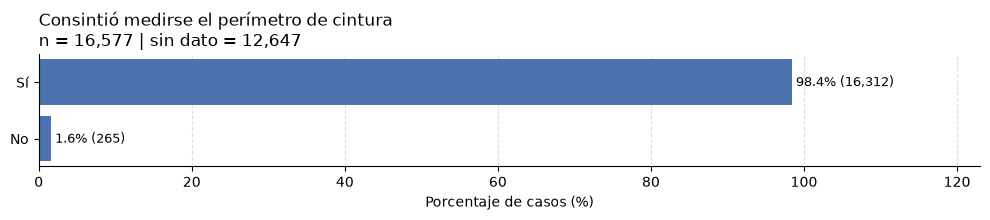

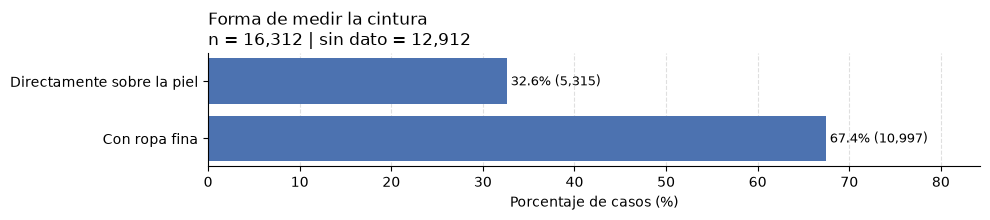

In [44]:
elevadas = {1: "Elevada",  2: "No elevada"}

formas_medicion = {1: "Directamente sobre la piel",  2: "Con ropa fina"}

variables_1315 = {
    "bima01": ("Respuesta válida al Paso 2", si_no),
    "bima02": ("Tomó bebidas con cafeína esta mañana", si_no),
    "bima03": ("Consintió medirse la presión", si_no),
    "ta_elevada": ("Presión arterial elevada (medición física)", elevadas),
    "prevalencia_hipertension_combinada": ("Presión arterial elevada (autorreporte o medición)", elevadas),
    "bima06": ("Consintió medirse la altura", si_no),
    "bima09": ("Consintió pesarse", si_no),
    "imc_categorias_bima": ("IMC medido agrupado", categorias_imc),
    "bima12": ("Consintió medirse el perímetro de cintura", si_no),
    "bima14": ("Forma de medir la cintura", formas_medicion),
}

graficar_variable(raw_data_mediciones_antro["bima04_01_a"], "Primera medición sistólica (mm Hg)", tipo="continua")
graficar_variable(raw_data_mediciones_antro["bima04_01_b"], "Primera medición diastólica (mm Hg)", tipo="continua")
graficar_variable(raw_data_mediciones_antro["bima04_02_a"], "Segunda medición sistólica (mm Hg)", tipo="continua")
graficar_variable(raw_data_mediciones_antro["bima04_02_b"], "Segunda medición diastólica (mm Hg)", tipo="continua")
graficar_variable(raw_data_mediciones_antro["bima04_03_a"], "Tercera medición sistólica (mm Hg)", tipo="continua")
graficar_variable(raw_data_mediciones_antro["bima04_03_b"], "Tercera medición diastólica (mm Hg)", tipo="continua")
graficar_variable(raw_data_mediciones_antro["promedio_sistolica"], "Presión sistólica promedio (mm Hg)", tipo="continua")
graficar_variable(raw_data_mediciones_antro["promedio_diastolica"], "Presión diastólica promedio (mm Hg)", tipo="continua")
graficar_variable(raw_data_mediciones_antro["bima07"], "Altura medida (cm)", tipo="continua")
graficar_variable(raw_data_mediciones_antro["bima10"], "Peso medido (kg)", tipo="continua")
graficar_variable(raw_data_mediciones_antro["imc_bima"], "IMC medido", tipo="continua")
graficar_variable(raw_data_mediciones_antro["bima13"], "Perímetro de cintura (cm)", tipo="continua")

for col, (titulo, etiquetas) in variables_1315.items():
    graficar_variable(raw_data_mediciones_antro[col], titulo, tipo="categorica", etiquetas=etiquetas)

### 1.3.16 Mediciones químicas

In [45]:
columnas = [
    "id",
    "bimq01",
    "bimq05",
    "bimq05_01",
    "glucemia_elevada",
    "prevalencia_glucemia_elevada_combinada",
    "findrisc",
    "bimq06",
    "bimq06_01",
    "colesterol_elevado",
    "prevalencia_colesterol_combinada",
]
raw_data_mediciones_quimi = raw_data[columnas]
raw_data_mediciones_quimi.head(5)

,id,bimq01,bimq05,bimq05_01,glucemia_elevada,prevalencia_glucemia_elevada_combinada,findrisc,bimq06,bimq06_01,colesterol_elevado,prevalencia_colesterol_combinada
0,1128639,2.0,NaN,NaN,NaN,NaN,2.0,NaN,NaN,NaN,NaN
1,1709939,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,6874130,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,10319375,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,11140857,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


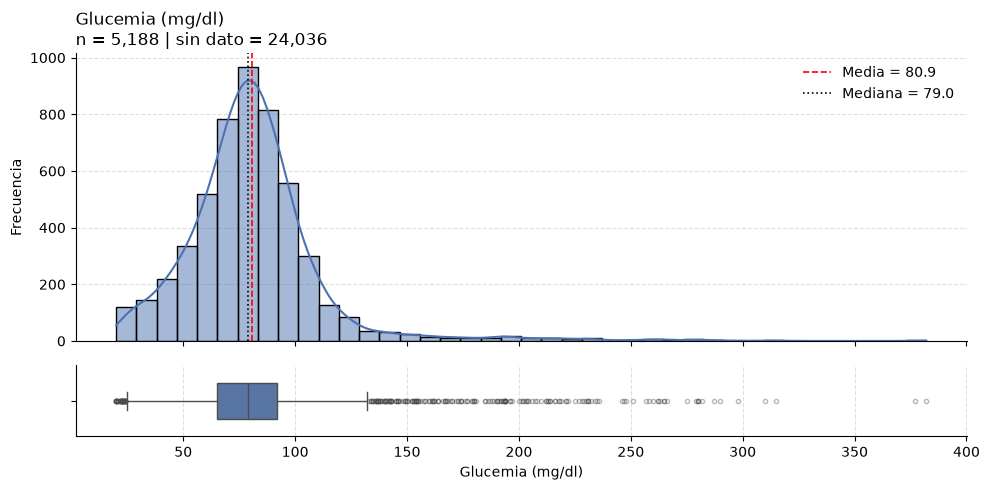

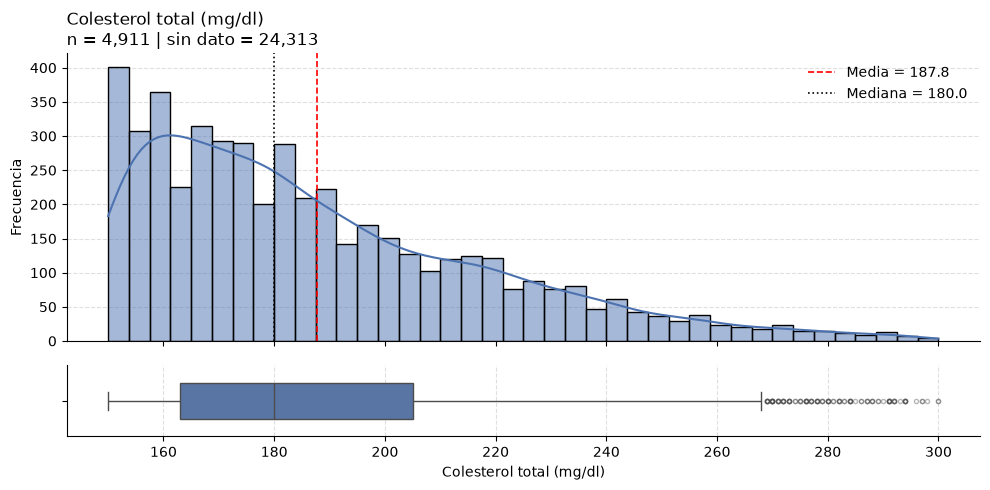

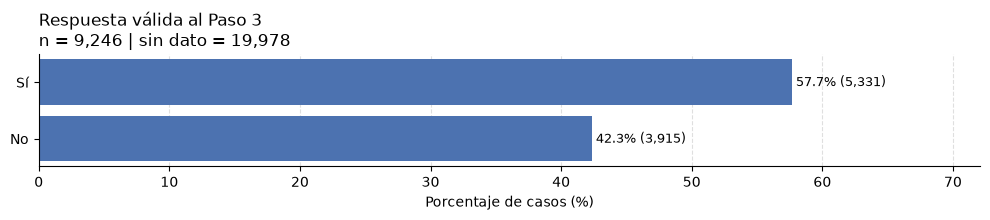

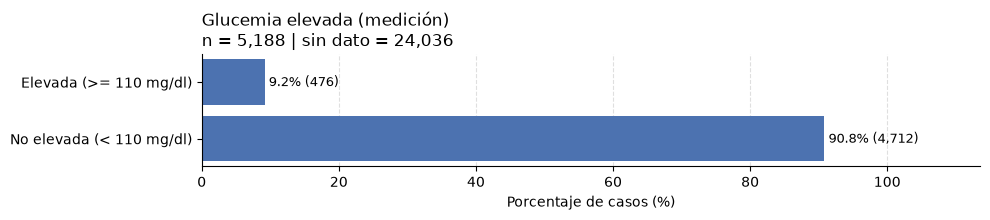

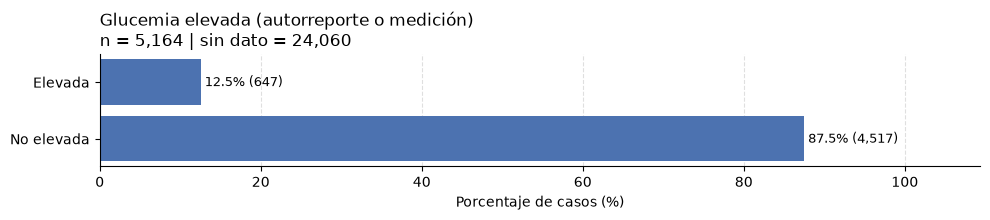

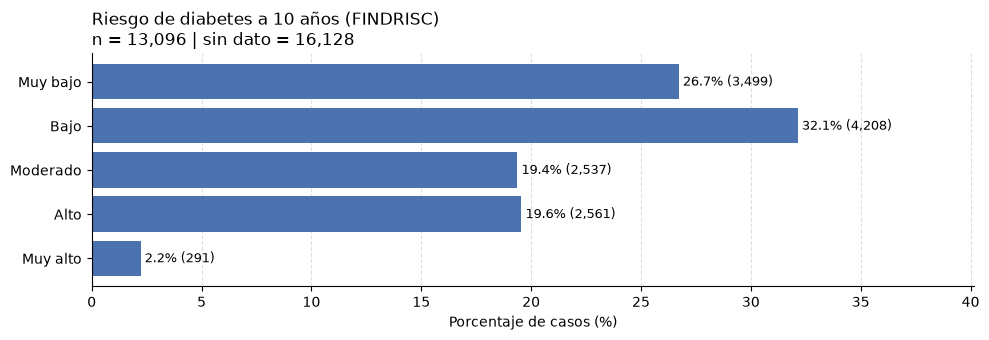

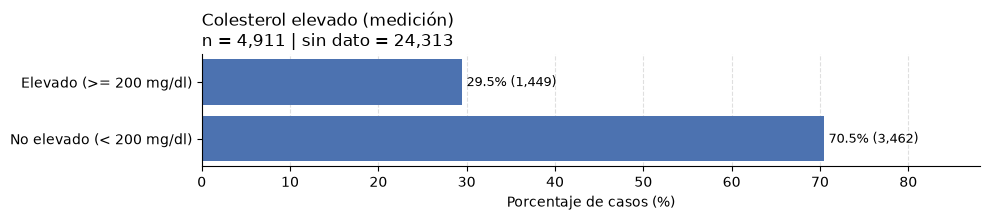

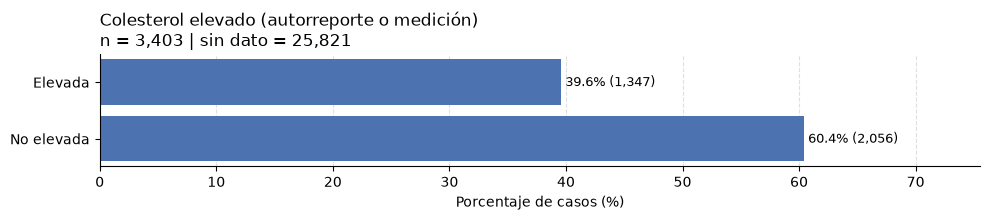

In [46]:
glucemias_elevadas = {1: "Elevada (>= 110 mg/dl)",  2: "No elevada (< 110 mg/dl)"}

colesteroles_elevados = {1: "Elevado (>= 200 mg/dl)",  2: "No elevado (< 200 mg/dl)"}

riesgos_findrisc = {1: "Muy bajo",  2: "Bajo",
                    3: "Moderado",  4: "Alto",
                    5: "Muy alto"
}

# bimq05_01 y bimq06_01 solo marcan que el aparato no registró el valor, así que no se grafican
variables_1316 = {
    "bimq01": ("Respuesta válida al Paso 3", si_no),
    "glucemia_elevada": ("Glucemia elevada (medición)", glucemias_elevadas),
    "prevalencia_glucemia_elevada_combinada": ("Glucemia elevada (autorreporte o medición)", elevadas),
    "findrisc": ("Riesgo de diabetes a 10 años (FINDRISC)", riesgos_findrisc),
    "colesterol_elevado": ("Colesterol elevado (medición)", colesteroles_elevados),
    "prevalencia_colesterol_combinada": ("Colesterol elevado (autorreporte o medición)", elevadas),
}

graficar_variable(raw_data_mediciones_quimi["bimq05"], "Glucemia (mg/dl)", tipo="continua")
graficar_variable(raw_data_mediciones_quimi["bimq06"], "Colesterol total (mg/dl)", tipo="continua")

for col, (titulo, etiquetas) in variables_1316.items():
    graficar_variable(raw_data_mediciones_quimi[col], titulo, tipo="categorica", etiquetas=etiquetas)

### 1.3.17 Factores de ponderacion muestral

In [47]:
columnas = [ "id",      
            "wf1p",
            "wf2p",
            "wf3p"]
raw_data_factores_ponderacion = raw_data[columnas]
raw_data_factores_ponderacion.head(5)
raw_data_factores_ponderacion["wf1p"].value_counts()

wf1p
189     58
150     57
227     56
126     55
154     55
        ..
1832     1
2184     1
26       1
2088     1
1414     1
Name: count, Length: 4175, dtype: int64

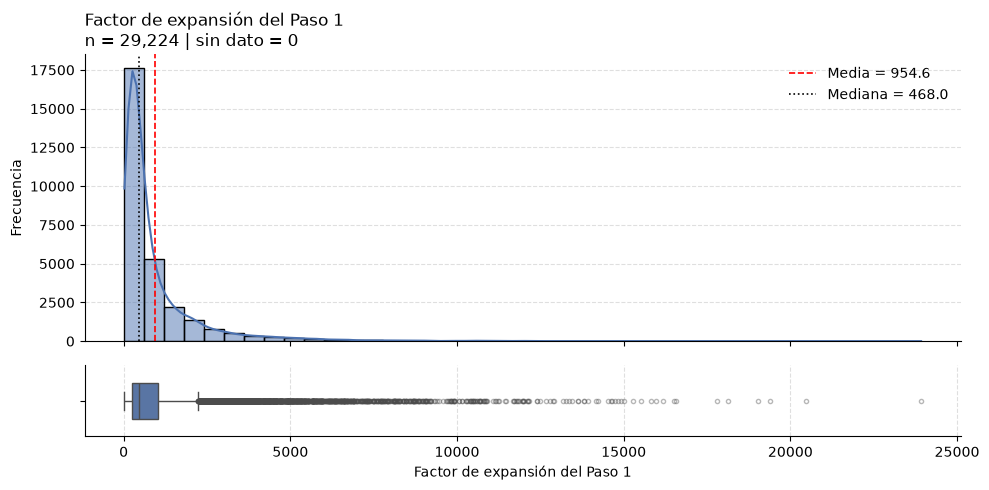

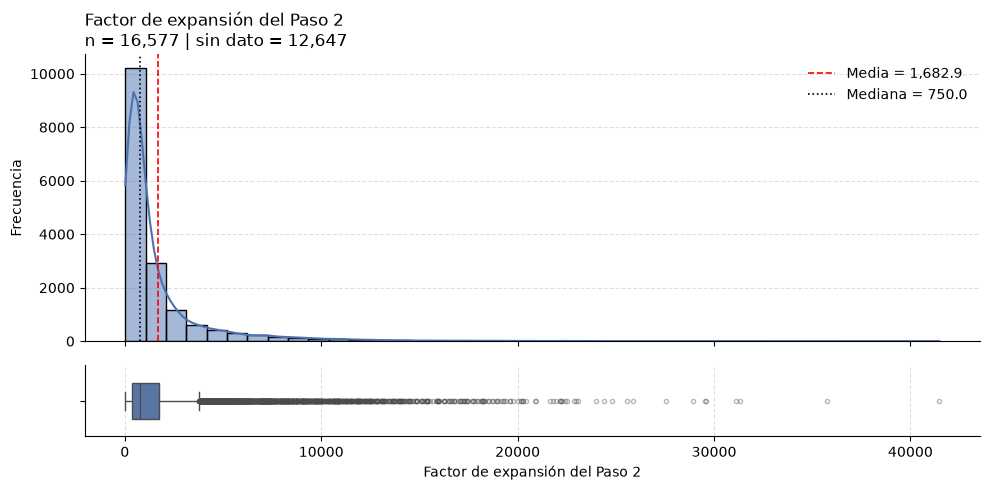

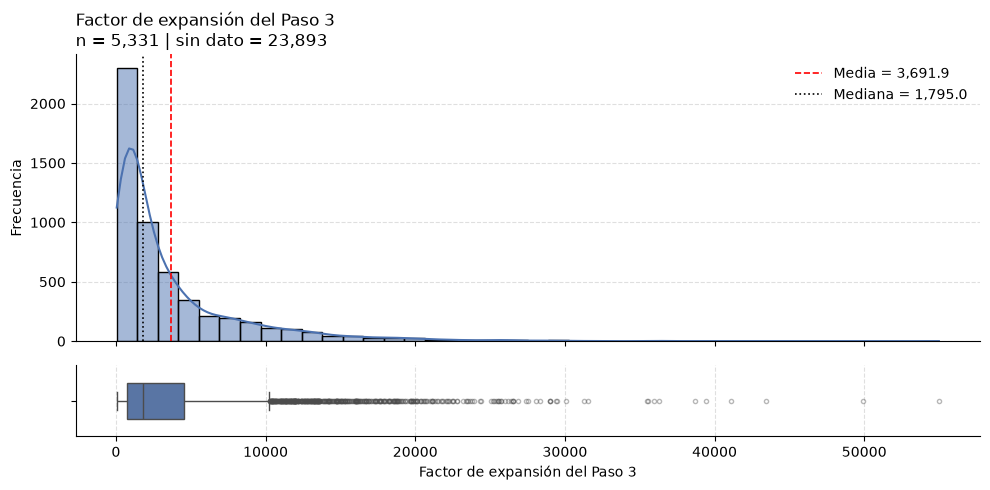

In [48]:
graficar_variable(raw_data_factores_ponderacion["wf1p"], "Factor de expansión del Paso 1", tipo="continua")

# Un factor 0 indica que el caso no participó de ese paso, así que se descarta en vez de graficarlo como valor
graficar_variable(raw_data_factores_ponderacion["wf2p"], "Factor de expansión del Paso 2", tipo="continua", nsnc=(0,))
graficar_variable(raw_data_factores_ponderacion["wf3p"], "Factor de expansión del Paso 3", tipo="continua", nsnc=(0,))

In [49]:
subdatasets = [
    df_id_ub,
    df_vivienda,
    df_hogar,
    df_ingresos,
    df_componentes,
    df_sit_laboral,
    raw_data_sociodemografico,
    raw_data_situ_laboral,
    raw_data_salud_general,
    raw_data_actividad_fisica,
    raw_data_tabaco,
    raw_data_hipertension,
    raw_data_peso_corporal,
    raw_data_alimentacion,
    raw_data_colesterol,
    raw_data_alcohol,
    raw_data_diabetes,
    raw_data_lesiones,
    raw_data_practicas_preventivas,
    raw_data_cancer_colorrectal,
    raw_data_mediciones_antro,
    raw_data_mediciones_quimi,
    raw_data_factores_ponderacion,
]

cols_agrupadas = set()
for sub in subdatasets:
    cols_agrupadas.update(sub.columns)

cols_sin_grupo = [col for col in raw_data.columns if col not in cols_agrupadas]

print(f"Columnas totales: {len(raw_data.columns)}")
print(f"Columnas agrupadas: {len(cols_agrupadas)}")
print(f"Columnas sin grupo: {len(cols_sin_grupo)}")


Columnas totales: 287
Columnas agrupadas: 287
Columnas sin grupo: 0


# 2. Hipótesis NUESTRAS

## 2.1 Hipótesis univariada

Todas las provincias están representadas en proporción a la distribución de la población argentina en 2018.

- H0: la proporción de la muestra en cada provincia es igual a su proporción en la población.
- H1: al menos una provincia no está correctamente representada.

Lo probamos con un test chi-cuadrado de bondad de ajuste, con α = 0,05.

### 2.1.1 Factor de expansión

Para comparar necesitamos saber cuánta gente vive en cada provincia, y eso lo trae la misma encuesta. Investigando encontramos que `wf1p` es el factor de expansión del INDEC: indica a cuántas personas de la población representa cada caso. Si sumamos el `wf1p` de todos los casos de una provincia, obtenemos su población proyectada de 18 años o más en 2018. En todo el país suma unos 27,9 millones de personas, y eso es lo que usamos como "población real".

In [50]:
import numpy as np
from scipy.stats import chisquare

df_prov = raw_data[["cod_provincia", "wf1p"]].assign(provincia=raw_data["cod_provincia"].map(provincias))
assert df_prov["provincia"].notna().all(), "Hay códigos de provincia no reconocidos"

resumen_provincia = df_prov.groupby("provincia").agg(casos=("wf1p", "size"), poblacion=("wf1p", "sum"))
resumen_provincia["% muestra"] = resumen_provincia["casos"] / resumen_provincia["casos"].sum() * 100
resumen_provincia["% poblacion"] = resumen_provincia["poblacion"] / resumen_provincia["poblacion"].sum() * 100
resumen_provincia["diferencia (pp)"] = resumen_provincia["% muestra"] - resumen_provincia["% poblacion"]
resumen_provincia = resumen_provincia.sort_values("% poblacion", ascending=False)

print(f"Casos totales: {resumen_provincia['casos'].sum():,}")
print(f"Población total expandida (18+): {resumen_provincia['poblacion'].sum():,.0f}")
resumen_provincia.round(2)


Casos totales: 29,224
Población total expandida (18+): 27,897,076


,casos,poblacion,% muestra,% poblacion,diferencia (pp)
provincia,,,,,
Buenos Aires,5572,11710384,19.07,41.98,-22.91
Córdoba,1985,2317236,6.79,8.31,-1.51
Ciudad de Buenos Aires,1372,2290361,4.69,8.21,-3.52
Santa Fe,1773,2163516,6.07,7.76,-1.69
Mendoza,983,1083326,3.36,3.88,-0.52
Tucumán,948,901072,3.24,3.23,0.01
Entre Ríos,1611,793420,5.51,2.84,2.67
Salta,1283,790882,4.39,2.83,1.56
Chaco,1021,634311,3.49,2.27,1.22


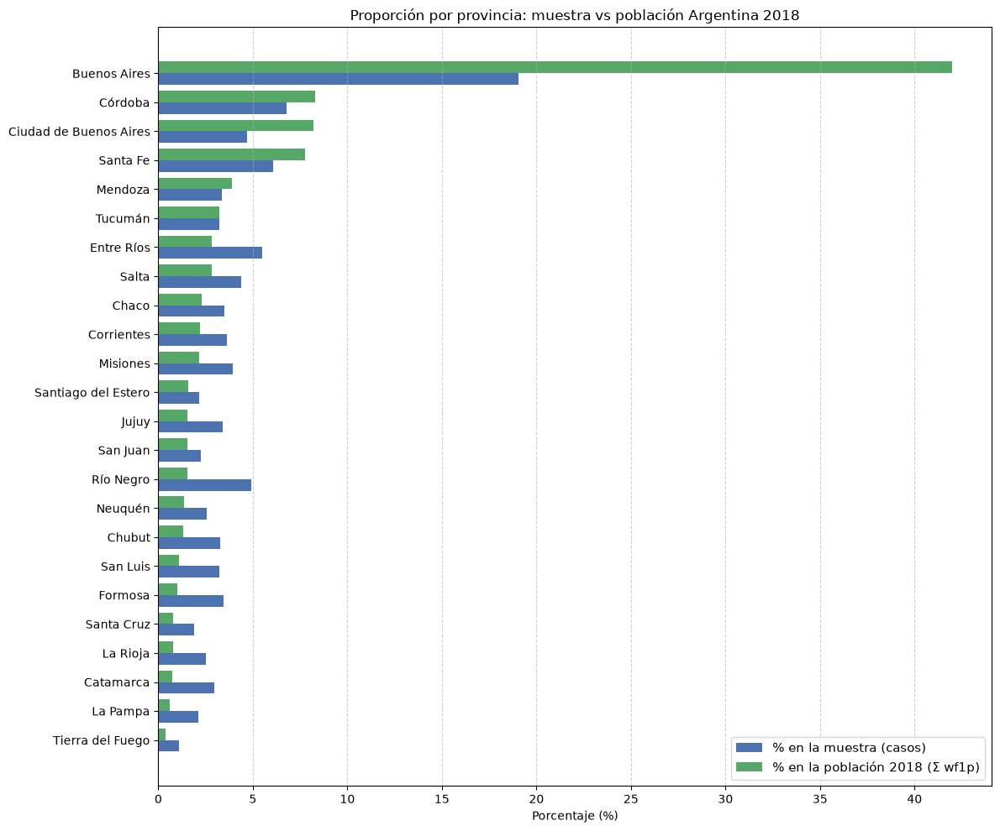

In [51]:
df_graf = resumen_provincia.sort_values("% poblacion")
y = np.arange(len(df_graf))
alto = 0.4

fig, ax = plt.subplots(figsize=(12, 10))
ax.barh(y - alto / 2, df_graf["% muestra"], alto, label="% en la muestra (casos)", color="#4C72B0")
ax.barh(y + alto / 2, df_graf["% poblacion"], alto, label="% en la población 2018 (Σ wf1p)", color="#55A868")
ax.set_yticks(y)
ax.set_yticklabels(df_graf.index)
ax.set_xlabel("Porcentaje (%)")
ax.set_title("Proporción por provincia: muestra vs población Argentina 2018")
ax.legend(fontsize=11)
ax.grid(axis="x", linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

Con el gráfico ya se ve que la hipótesis no se va a cumplir. Buenos Aires tiene el 19% de los casos de la muestra pero el 42% de la población, casi 23 puntos de diferencia. Con las provincias chicas pasa lo contrario: Río Negro o Catamarca tienen muchos más casos de los que les corresponderían. Igual lo confirmamos con un test.

### 2.1.2 Test chi-cuadrado de bondad de ajuste

Usamos este test porque tenemos una sola variable categórica (la provincia) y queremos ver si su distribución en la muestra coincide con una distribución conocida (la de la población).

Además del p-valor calculamos la w de Cohen, que mide qué tan grande es la diferencia (0,1 es chica, 0,3 mediana y 0,5 o más grande). La necesitamos porque con casi 30 mil casos hasta una diferencia mínima sale significativa.

In [52]:
n = resumen_provincia["casos"].sum()
observados = resumen_provincia["casos"]
esperados = resumen_provincia["poblacion"] / resumen_provincia["poblacion"].sum() * n

chi2, p_valor = chisquare(f_obs=observados, f_exp=esperados)
gl = len(observados) - 1
w_cohen = np.sqrt(chi2 / n)  

# Con un chi² tan grande el p-valor es más chico que el menor float, y scipy devuelve 0
p_txt = f"{p_valor:.3e}" if p_valor > 0 else "< 1e-300"
print(f"Chi² = {chi2:,.2f} | gl = {gl} | p-valor = {p_txt}")
print(f"w de Cohen = {w_cohen:.3f}")
print("Se rechaza H0" if p_valor < 0.05 else "No se rechaza H0", "(α = 0.05)")

resumen_provincia["esperados"] = esperados
resumen_provincia["residuo"] = (observados - esperados) / np.sqrt(esperados)
resumen_provincia[["casos", "esperados", "residuo"]].sort_values("residuo").round(2)


Chi² = 18,376.43 | gl = 23 | p-valor = < 1e-300
w de Cohen = 0.793
Se rechaza H0 (α = 0.05)


,casos,esperados,residuo
provincia,,,
Buenos Aires,5572,12267.39,-60.45
Ciudad de Buenos Aires,1372,2399.30,-20.97
Santa Fe,1773,2266.42,-10.36
Córdoba,1985,2427.46,-8.98
Mendoza,983,1134.85,-4.51
Tucumán,948,943.93,0.13
Santiago del Estero,632,467.42,7.61
San Juan,654,452.37,9.48
Chaco,1021,664.48,13.83


### 2.1.3 Conclusión

Rechazamos H0: el chi-cuadrado da 18.376 y p < 0,001. Y no es solo por tener muchos casos: la w de Cohen da 0,79, un efecto grande. La muestra no está repartida como la población.

Las provincias grandes tienen menos casos de los que deberían: Buenos Aires (19% contra 42%), CABA, Santa Fe, Córdoba y Mendoza. Las chicas tienen más: Catamarca, La Pampa, Formosa, La Rioja, Río Negro y San Luis tienen entre 3 y 4 veces los casos esperados. Tucumán es la única que queda prácticamente igual.

Tiene sentido que pase. La ENFR está pensada para dar resultados por provincia, así que a las provincias chicas les asigna más casos de los que les tocarían por su población. Para el resto del trabajo, esto significa que si queremos sacar conclusiones para todo el país hay que ponderar con `wf1p`. Si no, los resultados quedan inclinados hacia las provincias chicas.

Por eso rechazar H0 era esperable: la muestra se armó así a propósito. Lo que importa del test es el tamaño de la diferencia (w = 0,79) y hacia dónde va. Además, el chi-cuadrado supone un muestreo aleatorio simple y la ENFR tiene un diseño por estratos y conglomerados, así que el p-valor es orientativo. La "población real" son las proyecciones del INDEC que trae `wf1p`, no un censo.

## 2.2 Hipótesis bivariada

El tamaño de la ciudad (aglomerado) se relaciona con los hábitos nocivos para la salud: fumar y el consumo episódico excesivo de alcohol.

- H0: el tamaño del aglomerado y los hábitos nocivos son independientes.
- H1: el tamaño del aglomerado y los hábitos nocivos están asociados, es decir, los hábitos cambian según el tamaño de la ciudad.

Lo probamos con un test chi-cuadrado de independencia, con α = 0,05.

### 2.2.1 Variables que usamos

Usamos variables:

- Tabaco (`consumo_tabaco_100`): separamos a los fumadores actuales del resto. Los ex fumadores quedan junto con los que nunca fumaron.
- Alcohol (`consumo_episodico_excesivo`): sí o no. Elegimos esta y no "tomó en los últimos 30 días" porque esa también cuenta a quien toma una copa de vez en cuando, y eso no es un hábito nocivo.
- Con las dos armamos un patrón de hábitos con cuatro categorías: ninguno, solo tabaco, solo alcohol excesivo y ambos.
- Tamaño del aglomerado (`tamanio_aglomerado`): más de 1,5 millones de habitantes, de 500 mil a 1,5 millones, de 150 mil a 500 mil y menos de 150 mil. La categoría más grande es solo el Gran Buenos Aires, así que en la práctica es "GBA".

Sacamos los casos que no tienen dato en alguna de estas variables.

In [53]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency

df_bi = raw_data[["id", "tamanio_aglomerado", "consumo_tabaco_100", "consumo_episodico_excesivo"]].copy()
df_bi = df_bi[
    df_bi["consumo_tabaco_100"].isin([1, 2, 3]) & df_bi["consumo_episodico_excesivo"].isin([1, 2])
].dropna(subset=["tamanio_aglomerado"]).copy()

#fumador actual (código 1) y consumo episódico excesivo (código 1)
df_bi["fuma"] = (df_bi["consumo_tabaco_100"] == 1).astype(int)
df_bi["toma"] = (df_bi["consumo_episodico_excesivo"] == 1).astype(int)

df_bi["patron_habito"] = np.select(
    [
        (df_bi["fuma"] == 0) & (df_bi["toma"] == 0),
        (df_bi["fuma"] == 1) & (df_bi["toma"] == 0),
        (df_bi["fuma"] == 0) & (df_bi["toma"] == 1),
    ],
    ["Ninguno", "Solo tabaco", "Solo alcohol excesivo"],
    default="Ambos",
)

# Tamaños de aglomerado según ENFR 2018
tam_etiquetas = {
    1: "> 1.5M hab. (GBA)",
    2: "500k - 1.5M hab.",
    3: "150k - 500k hab.",
    4: "< 150k hab. (Pequeñas)",
}
df_bi["tamanio_ciudad"] = df_bi["tamanio_aglomerado"].map(tam_etiquetas)
categorias_orden = list(tam_etiquetas.values())
habito_orden = ["Ninguno", "Solo tabaco", "Solo alcohol excesivo", "Ambos"]

# Tablas de contingencia observada y porcentajes fila (%)
tabla_obs = pd.crosstab(df_bi["tamanio_ciudad"], df_bi["patron_habito"]).reindex(index=categorias_orden, columns=habito_orden)
tabla_pct = pd.crosstab(df_bi["tamanio_ciudad"], df_bi["patron_habito"], normalize="index").reindex(index=categorias_orden, columns=habito_orden) * 100

print("--- Frecuencias Observadas (Casos) ---")
display(tabla_obs)
print("\n--- Proporciones Fila (%) ---")
display(tabla_pct.round(2))

--- Frecuencias Observadas (Casos) ---


patron_habito,Ninguno,Solo tabaco,Solo alcohol excesivo,Ambos
tamanio_ciudad,,,,
> 1.5M hab. (GBA),2484,571,294,195
500k - 1.5M hab.,2051,558,207,167
150k - 500k hab.,3986,923,433,279
< 150k hab. (Pequeñas),12366,2818,1049,689



--- Proporciones Fila (%) ---


patron_habito,Ninguno,Solo tabaco,Solo alcohol excesivo,Ambos
tamanio_ciudad,,,,
> 1.5M hab. (GBA),70.09,16.11,8.30,5.50
500k - 1.5M hab.,68.76,18.71,6.94,5.60
150k - 500k hab.,70.91,16.42,7.70,4.96
< 150k hab. (Pequeñas),73.08,16.65,6.20,4.07


### 2.2.2 Test chi-cuadrado de independencia

Como vimos en la cátedra, el chi-cuadrado de independencia es el test que corresponde cuando las dos variables son categóricas, como el tamaño de la ciudad y el patrón de hábitos. Compara los casos de cada celda de la tabla con los que habría si las variables fueran independientes. El test necesita que todos los esperados sean al menos 5, y acá el más chico es 136.

Además calculamos:
- La V de Cramér, que mide qué tan fuerte es la asociación (va de 0 a 1). La necesitamos porque con unos 29 mil casos el p-valor sale significativo casi siempre.
- Los residuos de Pearson de cada celda, para ver dónde está la diferencia. Igual que en la univariada, a partir de 2 (o −2) ya es un desvío importante.

In [54]:
# Test chi-cuadrado de independencia con frecuencias observadas
chi2_stat, p_val, dof, esperados = chi2_contingency(tabla_obs)

# Tamaño del efecto: V de Cramér
n_total = tabla_obs.values.sum()
r, k = tabla_obs.shape
v_cramer = np.sqrt(chi2_stat / (n_total * (min(r, k) - 1)))

# Residuos de Pearson y aporte de cada categoría de hábito al chi²
esperados_df = pd.DataFrame(esperados, index=tabla_obs.index, columns=tabla_obs.columns)
residuos = (tabla_obs - esperados_df) / np.sqrt(esperados_df)

print(f"Chi² = {chi2_stat:,.2f} | Grados de libertad = {dof} | p-valor = {p_val:.3e}")
print(f"Frecuencia esperada mínima = {esperados.min():.1f} (supuesto del chi²: todas > 5)")
print(f"V de Cramér = {v_cramer:.4f}")
print("\nResiduos de Pearson:")
display(residuos.round(2))
print("Aporte de cada hábito al chi²:")
display((residuos ** 2).sum().round(1).to_frame("aporte").T)
print("Resultado: Se rechaza H0 (hay asociación estadísticamente significativa)" if p_val < 0.05 else "No se rechaza H0")

Chi² = 69.95 | Grados de libertad = 9 | p-valor = 1.557e-11
Frecuencia esperada mínima = 136.5 (supuesto del chi²: todas > 5)
V de Cramér = 0.0283

Residuos de Pearson:


patron_habito,Ninguno,Solo tabaco,Solo alcohol excesivo,Ambos
tamanio_ciudad,,,,
> 1.5M hab. (GBA),-1.24,-0.93,3.36,2.58
500k - 1.5M hab.,-1.99,2.61,0.25,2.61
150k - 500k hab.,-0.83,-0.61,2.53,1.36
< 150k hab. (Pequeñas),1.88,-0.32,-3.10,-3.06


Aporte de cada hábito al chi²:


patron_habito,Ninguno,Solo tabaco,Solo alcohol excesivo,Ambos
aporte,9.7,8.1,27.4,24.7


Resultado: Se rechaza H0 (hay asociación estadísticamente significativa)


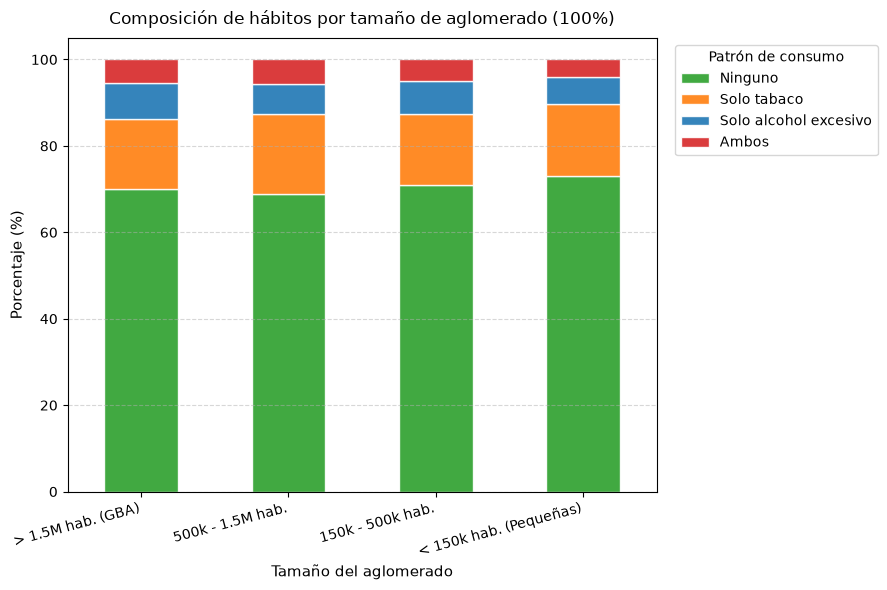

In [55]:
fig, ax = plt.subplots(figsize=(9, 6))

# Barras apiladas al 100% (composición relativa de hábitos por tamaño)
colores = ["#2ca02c", "#ff7f0e", "#1f77b4", "#d62728"]
tabla_pct.plot(kind="bar", stacked=True, ax=ax, color=colores, edgecolor="white", alpha=0.9)
ax.set_title("Composición de hábitos por tamaño de aglomerado (100%)", fontsize=12, pad=10)
ax.set_xlabel("Tamaño del aglomerado", fontsize=11)
ax.set_ylabel("Porcentaje (%)", fontsize=11)
ax.set_xticklabels(ax.get_xticklabels(), rotation=15, ha="right")
ax.legend(title="Patrón de consumo", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

In [56]:
# --- Chequeo sin Gran Buenos Aires ---
# Todos los casos de la categoría > 1.5M son de una sola región, así que se verifica
# que la asociación no dependa solo de GBA.
tabla_sin_gba = tabla_obs.iloc[1:]
chi2_sg, p_sg, dof_sg, _ = chi2_contingency(tabla_sin_gba)
v_sg = np.sqrt(chi2_sg / (tabla_sin_gba.values.sum() * (min(tabla_sin_gba.shape) - 1)))
print(f"Sin GBA: Chi² = {chi2_sg:,.2f} | gl = {dof_sg} | p-valor = {p_sg:.3e} | V de Cramér = {v_sg:.4f}")

Sin GBA: Chi² = 47.66 | gl = 6 | p-valor = 1.383e-08 | V de Cramér = 0.0306


### 2.2.3 Cuánto aporta cada hábito?

Para ver si la asociación viene del alcohol, del tabaco o de los dos, repetimos el test con cada hábito por separado, sobre los mismos casos.

Alcohol excesivo: Chi² = 54.31 | gl = 3 | p-valor = 9.629e-12 | V de Cramér = 0.0432 | OR (> 1.5M vs < 150k) = 1.40
Tabaco: Chi² = 19.61 | gl = 3 | p-valor = 2.048e-04 | V de Cramér = 0.0260 | OR (> 1.5M vs < 150k) = 1.05


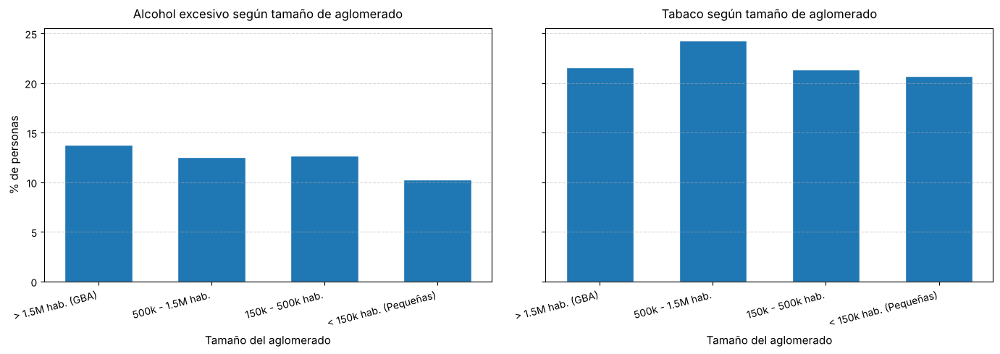

In [57]:
resultados = {}
for nombre, col in [("Alcohol excesivo", "toma"), ("Tabaco", "fuma")]:
    tab = pd.crosstab(df_bi["tamanio_ciudad"], df_bi[col]).reindex(index=categorias_orden, columns=[0, 1])
    chi2_h, p_h, dof_h, _ = chi2_contingency(tab)
    v_h = np.sqrt(chi2_h / tab.values.sum())  # min(r, k) - 1 = 1
    pct_h = tab[1] / tab.sum(axis=1) * 100
    odds = (pct_h.iloc[0] / (100 - pct_h.iloc[0])) / (pct_h.iloc[-1] / (100 - pct_h.iloc[-1]))
    resultados[nombre] = pct_h
    print(f"{nombre}: Chi² = {chi2_h:,.2f} | gl = {dof_h} | p-valor = {p_h:.3e} | V de Cramér = {v_h:.4f} | OR (> 1.5M vs < 150k) = {odds:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
x = np.arange(len(categorias_orden))
for ax, (nombre, pct_h) in zip(axes, resultados.items()):
    ax.bar(x, pct_h.values, 0.6, color="#1f77b4", edgecolor="white")
    ax.set_title(f"{nombre} según tamaño de aglomerado", fontsize=12, pad=10)
    ax.set_xlabel("Tamaño del aglomerado", fontsize=11)
    ax.set_xticks(x)
    ax.set_xticklabels(categorias_orden, rotation=15, ha="right")
    ax.grid(axis="y", linestyle="--", alpha=0.5)
axes[0].set_ylabel("% de personas", fontsize=11)

plt.tight_layout()
plt.show()

#### 2.2.3.1 Cómo leer estos dos gráficos

Lo que importa es cómo cambian las barras de izquierda a derecha, no qué tan altas son. La altura solo dice qué tan común es el hábito: fuma cerca del 22% de la gente y toma en exceso cerca del 12%, por eso las barras de tabaco son más altas en todas las ciudades. Eso no quiere decir que el tabaco dependa más del tamaño de la ciudad.

| | > 1.5M (GBA) | 500k - 1.5M | 150k - 500k | < 150k | V de Cramér | OR (GBA vs < 150k) |
|---|---|---|---|---|---|---|
| Alcohol excesivo | 13,8% | 12,5% | 12,7% | 10,3% | 0,043 | 1,40 |
| Tabaco | 21,6% | 24,3% | 21,4% | 20,7% | 0,026 | 1,05 |

- Alcohol excesivo: baja de las ciudades grandes a las chicas, hay un patrón claro.
- Tabaco: sube y baja sin orden, y GBA y las ciudades chicas quedan casi iguales. No hay patrón.

Por eso el tabaco aporta menos a la hipótesis, aunque tenga las barras más altas.

#### 2.2.3.2 Chequeo: alcohol en los últimos 30 días

Elegimos el consumo episódico excesivo y no "tomó alcohol en los últimos 30 días". Para ver cuánto cambia el resultado con esa otra definición, repetimos el test con ella. Sale de dos preguntas: `bica01` (si tomó alguna vez) y `bica02` (cuándo fue la última vez; el código 1 es en los últimos 30 días).

In [58]:
alcohol = raw_data.loc[df_bi.index, ["bica01", "bica02"]]
# 1 = tomó en los últimos 30 días, 0 = nunca tomó o la última vez fue antes, -1 = Ns/Nc (se descarta)
toma_30 = np.select([(alcohol["bica01"] == 1) & (alcohol["bica02"] == 1),
                     (alcohol["bica01"] == 2) | alcohol["bica02"].isin([2, 3])], [1, 0], default=-1)
con_dato = toma_30 >= 0
tab_30 = pd.crosstab(df_bi.loc[con_dato, "tamanio_ciudad"], toma_30[con_dato]).reindex(index=categorias_orden)
chi2_30, p_30, gl_30, _ = chi2_contingency(tab_30)
v_30 = np.sqrt(chi2_30 / tab_30.values.sum())  # min(r, k) - 1 = 1
print(f"Alcohol últimos 30 días: Chi² = {chi2_30:,.2f} | gl = {gl_30} | p-valor = {p_30:.2e} | V de Cramér = {v_30:.4f}")
print("\n% que tomó en los últimos 30 días:")
print((tab_30[1] / tab_30.sum(axis=1) * 100).round(1))

Alcohol últimos 30 días: Chi² = 180.37 | gl = 3 | p-valor = 7.35e-39 | V de Cramér = 0.0790

% que tomó en los últimos 30 días:
tamanio_ciudad
> 1.5M hab. (GBA)         56.6
500k - 1.5M hab.          53.4
150k - 500k hab.          47.9
< 150k hab. (Pequeñas)    45.5
dtype: float64


### 2.2.4 Conclusión

Rechazamos H0: el chi-cuadrado da 69,95 con 9 grados de libertad y p ≈ 1,6 × 10⁻¹¹. El tamaño de la ciudad y los hábitos nocivos están asociados. Pero la asociación es muy débil: la V de Cramér da 0,028. El test sale significativo sobre todo porque tenemos unos 29 mil casos.

La diferencia está casi toda en el alcohol. GBA tiene más casos de los esperados y las ciudades chicas, menos.

- Solo alcohol excesivo: 8,3% en GBA contra 6,2% en ciudades de menos de 150 mil habitantes.
- Ambos hábitos: 5,5% contra 4,1%.
- Ninguno: 70,1% contra 73,1%.
- Solo tabaco: se mueve entre 16,1% y 18,7% sin una tendencia clara.

Con cada hábito por separado se ve lo mismo. El alcohol excesivo baja de forma ordenada del 13,8% en GBA al 10,3% en las ciudades chicas: es un 34% más frecuente en GBA (OR ≈ 1,40, V ≈ 0,043). El tabaco no sigue el tamaño: sube al 24,3% en las ciudades de 500 mil a 1,5 millones y queda casi igual en GBA (21,6%) y en las chicas (20,7%), con OR ≈ 1,05 y V ≈ 0,026. 

Límites:
- La categoría más grande es solo GBA, así que el efecto "ciudad grande" en realidad es "GBA contra el resto". Sin GBA la asociación sigue, pero más débil.
- Con "tomó alcohol en los últimos 30 días" la asociación es más fuerte (V ≈ 0,079; 56,6% en GBA contra 45,5% en las ciudades chicas), pero esa variable también incluye el consumo moderado, que no es un hábito nocivo.

En resumen: rechazamos H0. El tamaño de la ciudad se asocia con los hábitos nocivos, sobre todo con el consumo excesivo de alcohol, que es más común en las ciudades grandes (en especial en GBA). El tabaco casi no cambia con el tamaño de la ciudad, y en conjunto la asociación es muy débil.

### 2.2.5 Por qué no ponderamos en esta hipótesis

Todos los resultados de esta hipótesis son sin ponderar: cada persona cuenta como un caso.

- El chi-cuadrado trabaja con conteos de casos y su estadístico crece con el tamaño de la muestra. Los pesos `wf1p` suman unos 27,7 millones de personas en vez de los 29.070 casos, así que, si los usáramos como frecuencias, el chi² quedaría casi mil veces más grande y el p-valor no tendría sentido. Para ponderar bien haría falta un test que tenga en cuenta el diseño muestral, que no usamos en este trabajo.
- Por eso los porcentajes de esta hipótesis describen a las personas encuestadas y no a toda la población adulta, y no extendemos las conclusiones más allá de la muestra. Como vimos en la hipótesis 1, la muestra no es proporcional a la población, y esto es una limitación de este análisis.

## 2.3 Hipótesis multivariada

Hábitos como comer bien, hacer actividad física, tener el IMC controlado y tomar y fumar poco están relacionados con las enfermedades más comunes: hipertensión y diabetes.

- H0: controlando por edad y sexo, ningún hábito está relacionado con tener hipertensión o diabetes (todos sus coeficientes valen 0).
- H1: controlando por edad y sexo, al menos un hábito está relacionado con la enfermedad.

Lo probamos con una regresión logística para cada enfermedad, con α = 0,05.

### 2.3.1 Causas y consecuencias

Separamos las variables en dos grupos:

- Causas (hábitos): IMC, porciones de frutas y verduras por día, horas sentado por día, nivel de actividad física (comparado contra actividad alta), tabaco (comparado contra no fumador) y consumo episódico excesivo de alcohol. La edad y el sexo entran como controles: influyen en las dos enfermedades, pero no son hábitos.
- Consecuencias: hipertensión (`prevalencia_hipertension`) y diabetes (`prevalencia_diabetes`).

No usamos la glucemia ni el colesterol porque son mediciones del lado de las enfermedades, no hábitos.

El IMC lo tratamos como un hábito, pero en parte es consecuencia de la alimentación y la actividad física. Al incluirlo en el modelo, el efecto de esas variables se mide "descontando" el IMC y puede quedar subestimado.

Quedan 23.333 de los 29.224 casos: se pierde un 20% por datos faltantes, sobre todo en hipertensión y en el IMC autorreportado (unos 2.200 casos en cada uno).

In [59]:
datos = pd.DataFrame({
    'hta': raw_data['prevalencia_hipertension'].map({1: 1, 2: 0}),
    'diabetes': raw_data['prevalencia_diabetes'].map({1: 1, 2: 0}),
    'Edad': raw_data['bhch04'],
    'Mujer': (raw_data['bhch03'] == 2).astype(int),
    'IMC': raw_data['imc'],
    'Frutas y verduras/día': raw_data['promedio_fv_diario'],
    'Horas sentado/día': raw_data['biaf07_m'] / 60,
    'Alcohol excesivo': raw_data['consumo_episodico_excesivo'].map({1: 1, 2: 0}),
    'actividad': raw_data['nivel_actividad_fisica'].map({1: 'Alta', 2: 'Actividad física media', 3: 'Actividad física baja'}),
    'tabaco': raw_data['consumo_tabaco_100'].map({1: 'Fumador actual', 2: 'Ex fumador', 3: 'No fumador'}),
}).dropna()
datos = (pd.get_dummies(datos, columns=['actividad', 'tabaco'], prefix='', prefix_sep='', dtype=int)
         .drop(columns=['Alta', 'No fumador']))

ENFERMEDADES = {'hta': 'Hipertensión', 'diabetes': 'Diabetes'}
predictores = list(datos.columns.drop(['hta', 'diabetes']))
CONTINUAS = ['Edad', 'IMC', 'Frutas y verduras/día', 'Horas sentado/día']

print(f"Casos completos: {len(datos):,}")
print(f"Prevalencia: HTA {datos['hta'].mean():.1%} | diabetes {datos['diabetes'].mean():.1%}")


Casos completos: 23,333
Prevalencia: HTA 36.7% | diabetes 13.9%


### 2.3.2 UMAP sobre las causas

Antes del test, miramos si los hábitos arman grupos de personas. Como vimos en la cátedra, PCA solo encuentra relaciones lineales, mientras que UMAP también capta estructuras no lineales, así que usamos UMAP. Tomamos 3.000 casos al azar, estandarizamos los hábitos y la edad, y los llevamos a dos dimensiones. Después pintamos el mismo mapa con cada variable y con cada enfermedad.

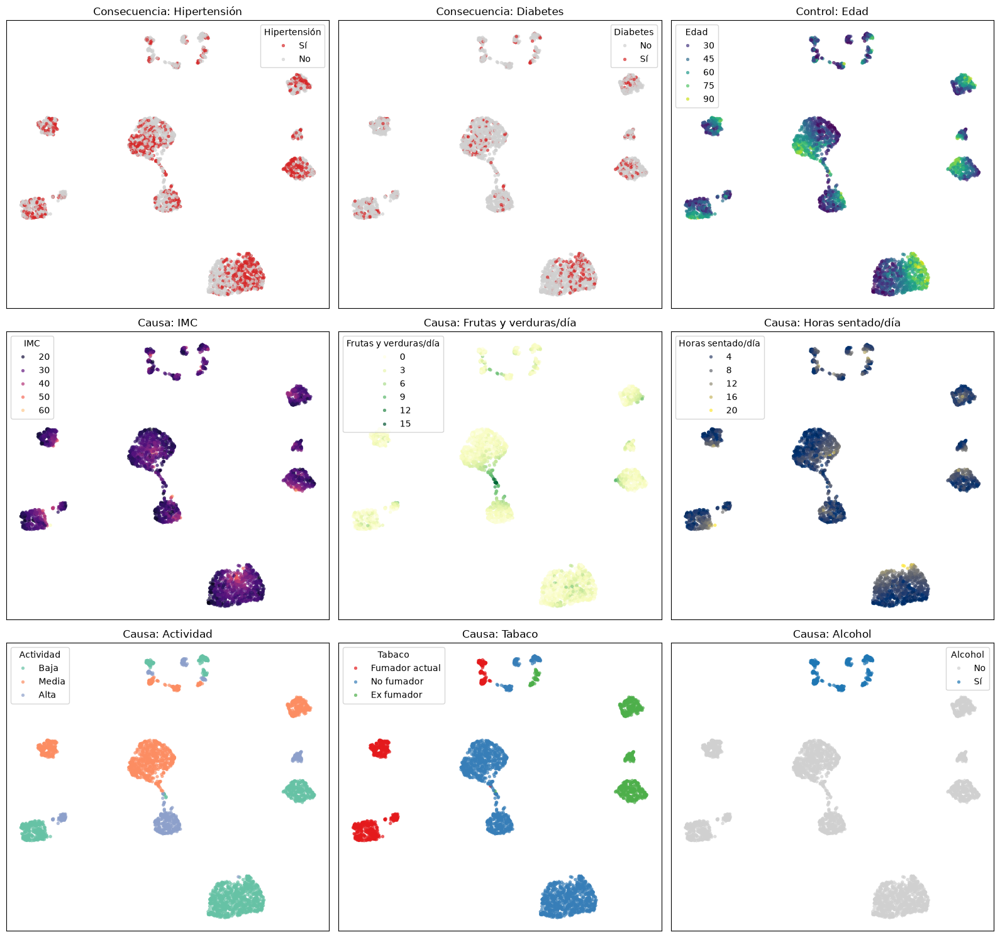

In [60]:
import warnings

# umap usa tqdm, que avisa que no encuentra ipywidgets para las barras de progreso; acá no las usamos
warnings.filterwarnings("ignore", message="IProgress not found")
import umap
from sklearn.preprocessing import StandardScaler

causas = [c for c in predictores if c != 'Mujer']
muestra = datos.sample(n=3000, random_state=42)
embedding = umap.UMAP(n_neighbors=30, min_dist=0.3, random_state=42, n_jobs=1).fit_transform(
    StandardScaler().fit_transform(muestra[causas]))

si_no = {1: 'Sí', 0: 'No'}
muestra = muestra.assign(
    umap_1=embedding[:, 0],
    umap_2=embedding[:, 1],
    Hipertensión=muestra['hta'].map(si_no),
    Diabetes=muestra['diabetes'].map(si_no),
    Alcohol=muestra['Alcohol excesivo'].map(si_no),
    Actividad=np.select([muestra['Actividad física baja'] == 1, muestra['Actividad física media'] == 1],
                        ['Baja', 'Media'], 'Alta'),
    Tabaco=np.select([muestra['Fumador actual'] == 1, muestra['Ex fumador'] == 1],
                     ['Fumador actual', 'Ex fumador'], 'No fumador'),
)

enfermo = {'Sí': '#d62728', 'No': '#d0d0d0'}
paneles = [
    ('Consecuencia', 'Hipertensión', enfermo),
    ('Consecuencia', 'Diabetes', enfermo),
    ('Control', 'Edad', 'viridis'),
    ('Causa', 'IMC', 'magma'),
    ('Causa', 'Frutas y verduras/día', 'YlGn'),
    ('Causa', 'Horas sentado/día', 'cividis'),
    ('Causa', 'Actividad', 'Set2'),
    ('Causa', 'Tabaco', 'Set1'),
    ('Causa', 'Alcohol', {'Sí': '#1f77b4', 'No': '#d0d0d0'}),
]

fig, axes = plt.subplots(3, 3, figsize=(16, 15))
for ax, (rol, col, paleta) in zip(axes.flatten(), paneles):
    sns.scatterplot(x='umap_1', y='umap_2', hue=col, palette=paleta, data=muestra, ax=ax, s=12, alpha=0.7, edgecolor=None)
    ax.set_title(f'{rol}: {col}')
    ax.set(xticks=[], yticks=[], xlabel='', ylabel='')
plt.tight_layout()
plt.show()


Lectura del UMAP: las enfermedades no forman grupos propios. La hipertensión y la diabetes aparecen en todas las islas, y dentro de cada una se juntan del lado de las personas de más edad. El mapa sugiere que la edad pesa más que cualquier hábito.

### 2.3.3 Regresión logística multivariada

El UMAP no usa las enfermedades para armar el mapa, así que no sirve para probar la hipótesis. Para eso ajustamos una regresión logística por enfermedad, con las causas y los controles como predictores. Usamos logística y no lineal porque lo que queremos explicar es sí o no: si la persona tiene o no la enfermedad.

Separamos los datos en entrenamiento (70%) y prueba (30%). Recién después estandarizamos las variables continuas (edad, IMC, frutas y verduras y horas sentado), con la media y el desvío del entrenamiento, para que los datos de prueba no influyan en el ajuste.

In [61]:
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

train, test = train_test_split(datos, test_size=0.3, random_state=42,
                               stratify=datos['hta'].astype(str) + datos['diabetes'].astype(str))
train, test = train.copy(), test.copy()

escalador = StandardScaler().fit(train[CONTINUAS])
train[CONTINUAS] = escalador.transform(train[CONTINUAS])
test[CONTINUAS] = escalador.transform(test[CONTINUAS])

print(f"Entrenamiento: {len(train):,} | Prueba: {len(test):,}")


Entrenamiento: 16,333 | Prueba: 7,000


In [62]:
def ajustar_logit(resultado, variables):
    """Ajusta la regresión logística de statsmodels sobre el conjunto de entrenamiento."""
    return sm.Logit(train[resultado], sm.add_constant(train[variables])).fit(disp=False)


completos = {r: ajustar_logit(r, predictores) for r in ENFERMEDADES}
for modelo in completos.values():
    print(modelo.summary())


                           Logit Regression Results                           
Dep. Variable:                    hta   No. Observations:                16333
Model:                          Logit   Df Residuals:                    16322
Method:                           MLE   Df Model:                           10
Date:                Mon, 09 Nov 2026   Pseudo R-squ.:                  0.1230
Time:                        17:20:07   Log-Likelihood:                -9417.8
converged:                       True   LL-Null:                       -10739.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                             coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------
const                     -0.8478      0.052    -16.153      0.000      -0.951      -0.745
Edad                       0.7245      0.019     37.160      0.000       0.686       0.763
Muje

                           Logit Regression Results                           
Dep. Variable:               diabetes   No. Observations:                16333
Model:                          Logit   Df Residuals:                    16322
Method:                           MLE   Df Model:                           10
Date:                Mon, 09 Nov 2026   Pseudo R-squ.:                 0.06495
Time:                        17:20:07   Log-Likelihood:                -6153.0
converged:                       True   LL-Null:                       -6580.4
Covariance Type:            nonrobust   LLR p-value:                3.448e-177
                             coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------
const                     -2.3128      0.077    -30.129      0.000      -2.463      -2.162
Edad                       0.4044      0.025     16.349      0.000       0.356       0.453
Muje

In [63]:
# Test de razón de verosimilitud: cada modelo contra uno con solo edad y sexo, con y sin el IMC
from scipy.stats import chi2 as distribucion_chi2

controles = ['Edad', 'Mujer']
habitos = [p for p in predictores if p not in controles]
habitos_sin_imc = [h for h in habitos if h != 'IMC']
for r, nombre in ENFERMEDADES.items():
    base = ajustar_logit(r, controles)
    for etiqueta, variables in [('con IMC', habitos), ('sin IMC', habitos_sin_imc)]:
        lr = 2 * (ajustar_logit(r, controles + variables).llf - base.llf)
        print(f"{nombre} ({etiqueta}): LR = {lr:.1f} | gl = {len(variables)} | "
              f"p-valor = {distribucion_chi2.sf(lr, len(variables)):.2e}")

Hipertensión (con IMC): LR = 633.0 | gl = 8 | p-valor = 1.87e-131
Hipertensión (sin IMC): LR = 49.8 | gl = 7 | p-valor = 1.59e-08
Diabetes (con IMC): LR = 401.8 | gl = 8 | p-valor = 7.83e-82
Diabetes (sin IMC): LR = 89.9 | gl = 7 | p-valor = 1.30e-16


Para probar H0 como bloque comparamos cada modelo con uno que tiene solo edad y sexo (test de razón de verosimilitud). Los hábitos mejoran mucho el modelo: en hipertensión LR = 633 (gl = 8) y en diabetes LR = 402 (gl = 8), con p < 0,001 en los dos. Sin contar el IMC también mejora (LR = 50 en hipertensión y 90 en diabetes, gl = 7, p < 0,001), así que el resultado no depende solo del IMC.

#### 2.3.3.1 Modelo reducido

Sacamos las variables cuyo intervalo de confianza del 95% incluye al 0 y volvemos a ajustar. Si sacamos solo una categoría de una variable (por ejemplo, actividad física media), esa categoría pasa a contar como parte de la referencia.

In [64]:
def significativas(modelo):
    """Devuelve las variables cuyo intervalo de confianza del 95% no contiene al 0."""
    ic = modelo.conf_int().drop('const')
    return list(ic.index[(ic[0] > 0) | (ic[1] < 0)])


reducidos = {}
for r, modelo in completos.items():
    variables = significativas(modelo)
    reducidos[r] = ajustar_logit(r, variables)
    print(f"{ENFERMEDADES[r]}: se quitan {[v for v in predictores if v not in variables]}")
    print(reducidos[r].summary())

display(pd.DataFrame({
    (ENFERMEDADES[r], version): {'Variables': len(m.params) - 1, 'Pseudo R²': m.prsquared, 'AIC': m.aic, 'BIC': m.bic}
    for r in ENFERMEDADES for version, m in [('Completo', completos[r]), ('Reducido', reducidos[r])]
}).round(3))

print('Cuanto aporta cada variable al modelo reducido (odds ratio):')
display(pd.DataFrame({ENFERMEDADES[r]: np.exp(m.params.drop("const")) for r, m in reducidos.items()}).reindex(predictores).dropna(how="all").round(3))


Hipertensión: se quitan ['Frutas y verduras/día', 'Horas sentado/día', 'Alcohol excesivo', 'Actividad física media', 'Fumador actual']
                           Logit Regression Results                           
Dep. Variable:                    hta   No. Observations:                16333
Model:                          Logit   Df Residuals:                    16327
Method:                           MLE   Df Model:                            5
Date:                Mon, 09 Nov 2026   Pseudo R-squ.:                  0.1228
Time:                        17:20:07   Log-Likelihood:                -9419.9
converged:                       True   LL-Null:                       -10739.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                            coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------
const                    -0.8198      0.034    -24.21

                           Logit Regression Results                           
Dep. Variable:               diabetes   No. Observations:                16333
Model:                          Logit   Df Residuals:                    16323
Method:                           MLE   Df Model:                            9
Date:                Mon, 09 Nov 2026   Pseudo R-squ.:                 0.06495
Time:                        17:20:07   Log-Likelihood:                -6153.0
converged:                       True   LL-Null:                       -6580.4
Covariance Type:            nonrobust   LLR p-value:                3.473e-178
                             coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------
const                     -2.3153      0.075    -31.016      0.000      -2.462      -2.169
Edad                       0.4047      0.025     16.416      0.000       0.356       0.453
Muje

Hipertensión              Diabetes           
              Completo   Reducido   Completo   Reducido
Variables       10.000      5.000     10.000      9.000
Pseudo R²        0.123      0.123      0.065      0.065
AIC          18857.565  18851.880  12327.996  12326.016
BIC          18942.276  18898.086  12412.706  12403.026

Cuanto aporta cada variable al modelo reducido (odds ratio):


,Hipertensión,Diabetes
Edad,2.074,1.499
Mujer,1.222,1.166
IMC,1.538,1.473
Frutas y verduras/día,NaN,1.047
Horas sentado/día,NaN,1.069
Alcohol excesivo,NaN,0.689
Actividad física baja,1.084,1.369
Actividad física media,NaN,1.337
Ex fumador,1.142,1.174


#### 2.3.3.2 Multicolinealidad (VIF)

La normalidad y la homocedasticidad de los residuos son supuestos de la regresión lineal, no de la logística, así que acá no se revisan. Lo que sí hay que revisar es que los predictores no estén muy correlacionados entre sí. Para eso usamos el VIF: si pasa de 5, hay un problema.

In [66]:
X_vif = sm.add_constant(train[predictores])
vif = pd.Series([variance_inflation_factor(X_vif.values, i) for i in range(1, X_vif.shape[1])],
                index=predictores, name='VIF')
vif.round(3)


Edad                      1.136
Mujer                     1.090
IMC                       1.044
Frutas y verduras/día     1.041
Horas sentado/día         1.024
Alcohol excesivo          1.099
Actividad física baja     2.117
Actividad física media    1.989
Ex fumador                1.127
Fumador actual            1.117
Name: VIF, dtype: float64

#### 2.3.3.3 Evaluación con los datos de prueba

Las clases están desbalanceadas: solo el 14% es diabético (y el 37% hipertenso). Eso es una característica del set de datos, no un defecto del modelo, y cambia cómo conviene evaluarlo.

**Por qué priorizamos Recall y Precisión y no el Accuracy.** Con clases desbalanceadas el Accuracy engaña: en diabetes, un modelo que responda siempre "No" acierta en el 86% de los casos sin detectar a ningún enfermo. Por eso evaluamos con:

- **Recall (sensibilidad):** de los enfermos reales, cuántos detecta el modelo. Es la métrica principal. En una enfermedad como la diabetes, un falso negativo (un enfermo que el modelo deja pasar) cuesta más que un falso positivo: la persona sigue sin diagnóstico ni tratamiento, mientras que una falsa alarma se descarta con un análisis de confirmación.
- **Precisión:** de las personas que el modelo marca como enfermas, cuántas lo están. La mostramos junto con el Recall porque dice cuánto cuesta detectar más casos, que es tener más falsas alarmas.
- **Accuracy:** la dejamos en la tabla como referencia, pero no la usamos para elegir entre modelos.

Para que el Logit deje de ignorar a los enfermos probamos dos cosas:

- Ponderar los errores (`class_weight='balanced'`): equivocarse con un enfermo pesa tantas veces más como veces es más común la clase "No". Son unas 6 veces en diabetes y 1,7 en hipertensión.
- Regularización Ridge con λ = 1 (en scikit-learn, `C = 1/λ`). Como la penalización depende de la escala, estandarizamos todos los predictores dentro del modelo, también los de sí o no, usando solo los datos de entrenamiento.

No buscamos un modelo con métricas perfectas, sino ver qué tan bien se puede detectar a los enfermos con estos datos. Comparamos contra el Logit sin ponderar, y el modelo completo contra el reducido.

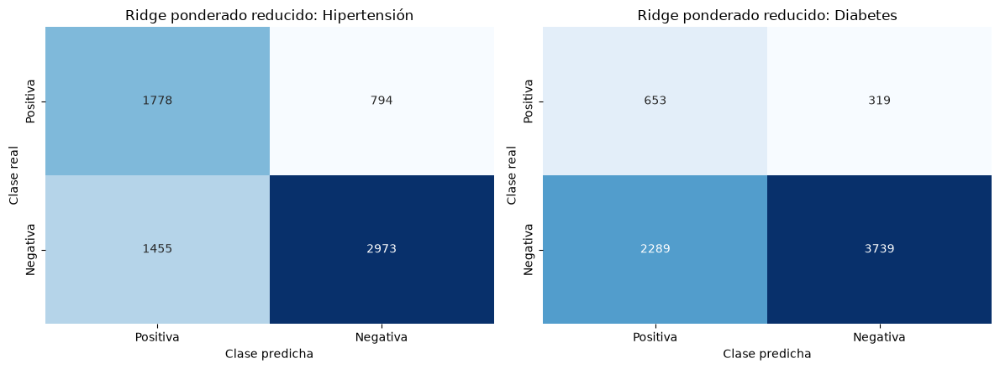

Hipertensión                           \
           Logit sin ponderar Ridge ponderado completo   
Accuracy                0.699                    0.678   
Error rate              0.301                    0.322   
Precisión               0.623                    0.549   
Recall                  0.457                    0.692   
NPV                     0.727                    0.789   

                                              Diabetes  \
           Ridge ponderado reducido Logit sin ponderar   
Accuracy                      0.679              0.861   
Error rate                    0.321              0.139   
Precisión                     0.550              0.529   
Recall                        0.691              0.009   
NPV                           0.789              0.862   

                                                              
           Ridge ponderado completo Ridge ponderado reducido  
Accuracy                      0.627                    0.627  
Error rate                    0.373                    0.373  
Precisión                     0.222                    0.222  
Recall                        0.671                    0.672  
NPV                           0.921                    0.921

In [67]:
def metricas(real, predicho):
    """Calcula la matriz de confusión (real en filas, predicha en columnas, positiva primero) y las métricas de clase."""
    tn, fp, fn, tp = confusion_matrix(real, predicho, labels=[0, 1]).ravel()
    return np.array([[tp, fn], [fp, tn]]), {
        'Accuracy': (tp + tn) / len(real),
        'Error rate': (fp + fn) / len(real),
        'Precisión': tp / (tp + fp) if tp + fp else np.nan,
        'Recall': tp / (tp + fn),
        'NPV': tn / (tn + fn),
    }


def ridge_ponderado(resultado, variables):
    """Regresión logística con Ridge (λ = 1) y errores ponderados por la inversa de la frecuencia de cada clase."""
    modelo = make_pipeline(StandardScaler(), LogisticRegression(C=1, class_weight='balanced', max_iter=1000))
    return modelo.fit(train[variables], train[resultado])


resultados, matrices = {}, {}
for r, nombre in ENFERMEDADES.items():
    reducidas = significativas(completos[r])
    sin_ponderar = (completos[r].predict(sm.add_constant(test[predictores])) >= 0.5).astype(int)
    _, resultados[(nombre, 'Logit sin ponderar')] = metricas(test[r], sin_ponderar)
    _, resultados[(nombre, 'Ridge ponderado completo')] = metricas(test[r], ridge_ponderado(r, predictores).predict(test[predictores]))
    matrices[nombre], resultados[(nombre, 'Ridge ponderado reducido')] = metricas(test[r], ridge_ponderado(r, reducidas).predict(test[reducidas]))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (nombre, matriz) in zip(axes, matrices.items()):
    sns.heatmap(matriz, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['Positiva', 'Negativa'], yticklabels=['Positiva', 'Negativa'])
    ax.set_xlabel('Clase predicha')
    ax.set_ylabel('Clase real')
    ax.set_title(f'Ridge ponderado reducido: {nombre}')
plt.tight_layout()
plt.show()

pd.DataFrame(resultados).round(3)


**Cómo leemos la tabla.** Las conclusiones se apoyan en el Recall y la Precisión. El Accuracy queda como referencia.

| | Recall | Precisión | Accuracy |
| :-- | :-- | :-- | :-- |
| Hipertensión, Logit sin ponderar | 0,46 | 0,62 | 0,70 |
| Hipertensión, Ridge ponderado reducido | 0,69 | 0,55 | 0,68 |
| Diabetes, Logit sin ponderar | 0,01 | 0,53 | 0,86 |
| Diabetes, Ridge ponderado reducido | 0,67 | 0,22 | 0,63 |

- **El Accuracy lleva a elegir el peor modelo.** En diabetes baja de 0,86 a 0,63 justo cuando el modelo empieza a servir. El Logit sin ponderar acierta tanto porque dice "No" casi siempre (detecta a unos 9 de los 972 diabéticos del conjunto de prueba), y su Accuracy es prácticamente igual al de un modelo que siempre responde "No" (0,861).
- **Qué detecta y qué deja pasar el Ridge ponderado reducido** (matrices de arriba): en diabetes detecta 653 de 972 diabéticos y deja pasar 319 (falsos negativos), con 2.289 falsas alarmas. En hipertensión detecta 1.778 de 2.572 y deja pasar 794, con 1.455 falsas alarmas.
- **Por qué aceptamos las falsas alarmas.** Si el objetivo es detectar casos, es preferible tener más falsos positivos, que se descartan con un análisis, que más falsos negativos, que quedan sin diagnosticar. La Precisión baja (0,22 en diabetes) es el precio de ese Recall, y la presentamos como una limitación de lo que se puede predecir con estos datos, no como algo que corregir.

### 2.3.4 Conclusión

Rechazamos H0. Aun controlando por edad y sexo, varios hábitos tienen un intervalo de confianza que no incluye al 0. Los dos modelos son significativos en conjunto (`LLR p-value` < 0,001) y, como bloque, los hábitos mejoran el modelo respecto de uno con solo edad y sexo (test de razón de verosimilitud, p < 0,001, también sin el IMC). Pero no todos los hábitos pesan igual:

- IMC: es el hábito de mayor peso en los dos modelos (OR ≈ 1,5 por desvío estándar). La edad pesa igual o más (OR 2,07 en hipertensión y 1,50 en diabetes).
- Actividad física: tener actividad baja sube la chance de hipertensión un 8% (OR 1,08) y la de diabetes un 37% (OR 1,37). En diabetes también pesa la actividad media (OR 1,34).
- Tabaco: fumar actualmente queda afuera de los dos modelos. Los ex fumadores tienen más chance de hipertensión (OR 1,14) y de diabetes (OR 1,17).
- Frutas y verduras, horas sentado y alcohol: quedan afuera del modelo de hipertensión. En diabetes se quedan: estar más horas sentado sube un poco la chance (OR 1,07 por desvío estándar), como esperábamos, pero las frutas y verduras también la suben (OR 1,05), al revés. Son efectos chicos, y el de frutas y verduras tiene un p-valor justo (0,04) y un signo contrario al esperado, por eso no los tomamos como resultados firmes. El alcohol excesivo, en cambio, aparece como protector en diabetes (OR 0,69).

Lo que sale al revés de lo esperado (ex fumadores y alcohol en diabetes) probablemente sea causalidad inversa. La encuesta es una foto de un solo momento, y alguien a quien ya le diagnosticaron la enfermedad suele dejar de fumar y de tomar. Por eso estos resultados muestran asociación, no causa.

Sobre los modelos:

- Modelo reducido: el de hipertensión pasa de 10 a 5 variables con el mismo Pseudo R² (0,123) y menor AIC y BIC. El de diabetes solo pierde "fumador actual". Como explican lo mismo con menos variables, nos quedamos con los reducidos.
- VIF: todos dan menos de 2,2, así que no hay multicolinealidad.
- Sin ponderar: el `Logit` no admite pesos, así que estos modelos no están ponderados con `wf1p` y las conclusiones valen para la muestra, no para la población.
- Pseudo R²: es bajo (0,12 en hipertensión y 0,06 en diabetes). Lo tomamos como una limitación del set de datos y no como un problema del modelo. Los hábitos autorreportados de una encuesta transversal son solo una parte de lo que determina quién se enferma (hay factores que la encuesta no mide, como la genética), y en los modelos logísticos aplicados a salud es habitual que el R² sea bajo. Lo que sostiene la conclusión es que los coeficientes son significativos (IC del 95% sin el 0 y test de razón de verosimilitud con p < 0,001) y que tienen coherencia teórica: más IMC y menos actividad física se asocian con más chance de enfermar. Por eso no ajustamos el modelo para subir el R².
- Evaluación: priorizamos el Recall y la Precisión sobre el Accuracy (ver 2.3.3.3). El Logit sin ponderar detecta al 46% de los hipertensos y al 1% de los diabéticos, aunque su Accuracy en diabetes (0,861) parece alto: es prácticamente el mismo que tendría un modelo que siempre responde "No". Ponderando los errores y con Ridge, el Recall sube a 0,69 en hipertensión y a 0,67 en diabetes, y el Accuracy en diabetes baja a 0,63. Aceptamos esa baja porque en diabetes un falso negativo (un enfermo sin detectar) cuesta más que un falso positivo, que se descarta con un análisis. El costo son más falsas alarmas: en diabetes la Precisión es 0,22, o sea que más o menos 1 de cada 5 personas marcadas es diabética. El modelo completo y el reducido dan prácticamente las mismas métricas.

En resumen, los hábitos sirven para explicar diferencias de riesgo entre grupos de personas, pero con estos datos no alcanzan para predecir con precisión quién está enfermo. Es una limitación del set de datos (encuesta transversal, hábitos autorreportados y sin mediciones clínicas en la muestra completa) y no intentamos corregirla ajustando el modelo. Para detectar casos, el modelo con errores ponderados encuentra a 2 de cada 3 enfermos, pero con muchas falsas alarmas.

# 3. Hipótesis GRUPAL

## 3.1 Hipótesis univariada

El consumo diario de frutas y verduras de la población adulta argentina es menor a las 5 porciones diarias que recomienda la OMS.

- H0: el consumo diario promedio es de 5 porciones o más.
- H1: el consumo diario promedio es menor a 5 porciones.

Lo probamos con un test t de una muestra, unilateral, con α = 0,05. Usamos `promedio_fv_diario`, que tiene dato para 28.471 personas.

In [68]:
fv = raw_data["promedio_fv_diario"].dropna()
fv.describe()


count    28471.000000
mean         2.071157
std          1.708309
min          0.000000
25%          1.000000
50%          1.640000
75%          2.710000
max         18.000000
Name: promedio_fv_diario, dtype: float64

En promedio se comen 2,07 porciones por día, y la mitad de la gente come menos de 1,64. A simple vista ya está lejos de 5.

### 3.1.1 Normalización Min-Max

Llevamos `promedio_fv_diario` a una escala de 0 a 1, donde la referencia de 5 porciones queda en 0,278. Como es un cambio de escala lineal, el test t da exactamente lo mismo que con las porciones originales.

In [69]:
fv_min, fv_max = fv.min(), fv.max()
fv_minmax = (fv - fv_min) / (fv_max - fv_min)
ref_minmax = (5 - fv_min) / (fv_max - fv_min)

print(f"min = {fv_min}, max = {fv_max}, referencia OMS (5 porciones) = {ref_minmax:.3f}")
fv_minmax.describe()


min = 0.0, max = 18.0, referencia OMS (5 porciones) = 0.278


count    28471.000000
mean         0.115064
std          0.094906
min          0.000000
25%          0.055556
50%          0.091111
75%          0.150556
max          1.000000
Name: promedio_fv_diario, dtype: float64

### 3.1.2 Normalidad: Shapiro-Wilk y QQ-plot

Antes del test t revisamos si los datos son normales.

- H0: los datos siguen una distribución normal.
- H1: los datos no siguen una distribución normal.

Con más de 5.000 casos el p-valor de Shapiro-Wilk es aproximado, por eso también miramos el QQ-plot.

Shapiro-Wilk: W = 0.7972 | p-valor = 1.08e-101
Se rechaza normalidad (α = 0.05)
Asimetría = 2.55


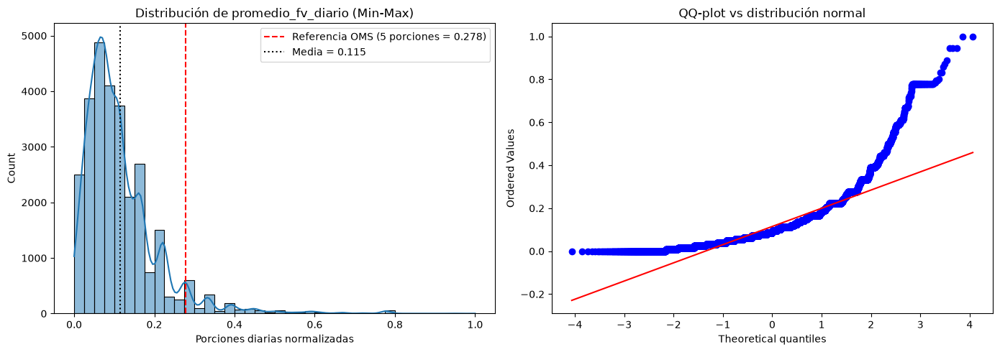

In [70]:
import warnings
from scipy import stats

# Con n > 5000 el p-valor de Shapiro-Wilk es aproximado. Ya lo aclaramos arriba, así que se silencia ese aviso
with warnings.catch_warnings():
    warnings.simplefilter("ignore", UserWarning)
    w_shapiro, p_shapiro = stats.shapiro(fv_minmax)
print(f"Shapiro-Wilk: W = {w_shapiro:.4f} | p-valor = {p_shapiro:.3g}")
print("Se rechaza normalidad" if p_shapiro < 0.05 else "No se rechaza normalidad", "(α = 0.05)")
print(f"Asimetría = {stats.skew(fv_minmax):.2f}")

fig, (ax_h, ax_qq) = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(fv_minmax, bins=40, kde=True, ax=ax_h)
ax_h.axvline(ref_minmax, color="red", ls="--", label=f"Referencia OMS (5 porciones = {ref_minmax:.3f})")
ax_h.axvline(fv_minmax.mean(), color="black", ls=":", label=f"Media = {fv_minmax.mean():.3f}")
ax_h.set_title("Distribución de promedio_fv_diario (Min-Max)")
ax_h.set_xlabel("Porciones diarias normalizadas")
ax_h.legend()

stats.probplot(fv_minmax, dist="norm", plot=ax_qq)
ax_qq.set_title("QQ-plot vs distribución normal")
plt.tight_layout()
plt.show()


Shapiro-Wilk rechaza la normalidad (W = 0,797, p < 0,001), la asimetría es 2,55 (fuerte hacia la derecha) y en el QQ-plot los puntos se alejan de la recta: la mayoría come pocas porciones y unos pocos comen muchas. Igual podemos usar el test t, porque con 28 mil casos la media se comporta como normal por el teorema central del límite.

### 3.1.3 Test t de Student (una muestra, unilateral)

Es el mismo planteo que el ejemplo de las casas de Boston que vimos en clase (H0: μ = 25 contra H1: μ < 25), pero con las porciones de frutas y verduras.

- H0: μ ≥ 5 porciones (0,278 en la escala Min-Max).
- H1: μ < 5 porciones.

In [71]:
t_stat, p_t = stats.ttest_1samp(fv_minmax, popmean=ref_minmax, alternative="less")
gl_t = len(fv_minmax) - 1

print(f"Media muestral (Min-Max) = {fv_minmax.mean():.4f} vs referencia = {ref_minmax:.4f}")
# Con un t tan grande el p-valor es más chico que el menor float, y scipy devuelve 0
p_txt = f"{p_t:.3e}" if p_t > 0 else "< 1e-300"
print(f"t = {t_stat:.2f} | gl = {gl_t} | p-valor = {p_txt}")
print("Se rechaza H0: el consumo es menor a 5 porciones" if p_t < 0.05 else "No se rechaza H0", "(α = 0.05)")

ic_sup = fv_minmax.mean() + stats.t.ppf(0.95, gl_t) * fv_minmax.std(ddof=1) / np.sqrt(len(fv_minmax))
print(f"Cota superior IC 95%: {ic_sup:.4f} (Min-Max) = {ic_sup * (fv_max - fv_min) + fv_min:.2f} porciones")


Media muestral (Min-Max) = 0.1151 vs referencia = 0.2778
t = -289.29 | gl = 28470 | p-valor = < 1e-300
Se rechaza H0: el consumo es menor a 5 porciones (α = 0.05)
Cota superior IC 95%: 0.1160 (Min-Max) = 2.09 porciones


Rechazamos H0: t = −289 con 28.470 grados de libertad y p < 0,001. La cota superior del intervalo de confianza del 95% es 2,09 porciones, muy lejos de 5.

### 3.1.4 Sin ponderar vs ponderado por `wf1p`

En la hipótesis 2.1 vimos que la muestra no está repartida como la población. Para hablar de la población adulta argentina ponderamos cada caso con `wf1p`. En el test t ponderado usamos el tamaño efectivo de Kish, n_ef = (Σw)² / Σw², que es la cantidad de casos que "valen" de verdad cuando los pesos son tan distintos entre sí.

In [72]:
def resumen_t(x, w, mu0):
    """Media, desvío y test t unilateral (H1: μ < mu0) ponderados, con el tamaño efectivo de Kish n_ef = (Σw)² / Σw²."""
    media = np.average(x, weights=w)
    desvio = np.sqrt(np.average((x - media) ** 2, weights=w))
    n_ef = w.sum() ** 2 / (w ** 2).sum()
    t = (media - mu0) / (desvio / np.sqrt(n_ef))
    return {
        "media (Min-Max)": media,
        "media (porciones)": media * (fv_max - fv_min) + fv_min,
        "desvío (Min-Max)": desvio,
        "% con >= 5 porciones": np.average(x >= ref_minmax, weights=w) * 100,
        "n (efectivo)": n_ef,
        "t": t,
        "p-valor": stats.t.cdf(t, df=n_ef - 1),
    }


pesos = raw_data.loc[fv_minmax.index, "wf1p"]
comparacion = pd.DataFrame({
    "Sin ponderar": resumen_t(fv_minmax, np.ones(len(fv_minmax)), ref_minmax),
    "Ponderado (wf1p)": resumen_t(fv_minmax, pesos, ref_minmax),
})
# La diferencia solo se lee en la media y en el porcentaje; en n, t y p-valor no tiene sentido
comparacion["Diferencia (pond - sin pond)"] = np.nan
filas_dif = ["media (porciones)", "% con >= 5 porciones"]
comparacion.loc[filas_dif, "Diferencia (pond - sin pond)"] = (
    comparacion.loc[filas_dif, "Ponderado (wf1p)"] - comparacion.loc[filas_dif, "Sin ponderar"])
comparacion.round(4)


,Sin ponderar,Ponderado (wf1p),Diferencia (pond - sin pond)
media (Min-Max),0.1151,0.1128,NaN
media (porciones),2.0712,2.0297,-0.0415
desvío (Min-Max),0.0949,0.0913,NaN
% con >= 5 porciones,6.2239,6.0438,-0.1801
n (efectivo),28471.0000,8993.8434,NaN
t,-289.2936,-171.3585,NaN
p-valor,0.0000,0.0000,NaN


### 3.1.5 Conclusión

Rechazamos H0: el consumo de frutas y verduras de la población adulta argentina es menor a 5 porciones diarias.

- Normalidad: los datos no son normales (W = 0,797, asimetría 2,55), pero con tantos casos el test t sigue siendo válido.
- Test t: t = −289 y p < 0,001. Se comen en promedio 2,07 porciones por día, y la cota superior del IC 95% es 2,09.
- Ponderado: con `wf1p` la media baja a 2,03 porciones y la proporción que llega a 5 porciones pasa de 6,2% a 6,0%. El n efectivo cae de 28.471 a unos 8.994 y el t queda en −171. La conclusión no cambia.

En resumen, solo unos 6 de cada 100 adultos comen las 5 porciones recomendadas.

## 3.2 Hipótesis bivariada

El IMC medido (calculado con el peso y la altura del paso 2) cambia según el nivel de actividad física de las personas.

- H0: la distribución del IMC es la misma en los tres niveles de actividad física (alta, media y baja).
- H1: el IMC es distinto en al menos dos niveles de actividad. Lo esperado es que a menor actividad, mayor IMC.

Usamos α = 0,05.

### 3.2.1 Variables y datos

- IMC medido (imc_bima): es la variable respuesta. Es cuantitativa continua, en kg/m², y se calcula con el peso y la altura medidos en el paso 2.
- Nivel de actividad física (nivel_actividad_fisica): es la variable explicativa. Es cualitativa ordinal y agrupa a las personas en tres niveles: alta (1), media (2) y baja (3).

Solo una parte de la muestra pasó por el paso 2 (mediciones físicas), así que sacamos a quienes no tienen IMC medido. También sacamos los códigos 99 (Ns/Nc).

In [73]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from itertools import combinations

# Variables: IMC (paso 2) y nivel de actividad física (1=Alta, 2=Media, 3=Baja)
df_h = raw_data[['id', 'imc_bima', 'imc_categorias_bima', 'nivel_actividad_fisica']].copy()
df_h = df_h.dropna(subset=['imc_bima', 'nivel_actividad_fisica'])
df_h = df_h[df_h['imc_categorias_bima'] != 99]

df_h['actividad'] = df_h['nivel_actividad_fisica'].map({1: 'Alta', 2: 'Media', 3: 'Baja'})
orden = ['Alta', 'Media', 'Baja']
colores = {'Alta': '#2a9d8f', 'Media': '#e9c46a', 'Baja': '#e76f51'}

print(f"n total = {len(df_h)}\n")
print(df_h.groupby('actividad')['imc_bima'].describe().loc[orden].round(2))

n total = 16282

            count   mean   std    min    25%    50%    75%    max
actividad                                                        
Alta       2768.0  26.95  5.35  14.15  23.11  26.15  30.04  62.33
Media      5840.0  27.83  5.56  15.12  23.85  27.06  31.14  60.16
Baja       7674.0  28.99  6.27  14.67  24.57  28.23  32.44  86.57


Quedan unas 16.300 personas, y el grupo más grande es el de actividad baja. La media y la mediana del IMC suben a medida que baja la actividad (mediana de 26,2 en alta, 27,1 en media y 28,2 en baja), y el grupo de actividad baja también es el más disperso. Eso ya anticipa lo que hay que revisar: si los grupos son distintos y si sus varianzas son iguales.

### 3.2.2 IMC según nivel de actividad

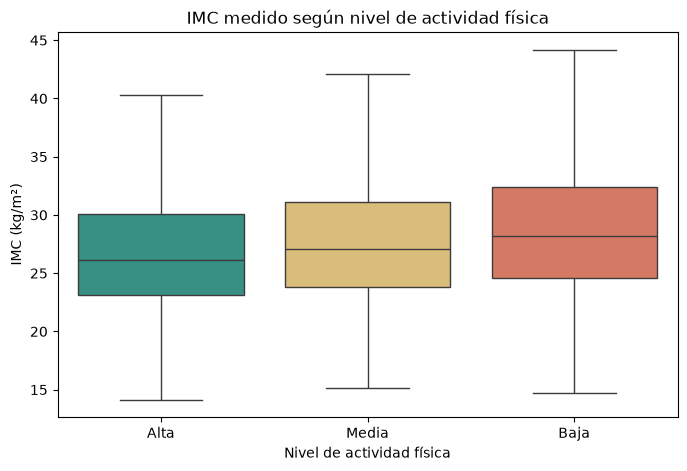

In [74]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df_h, x='actividad', y='imc_bima', order=orden, hue='actividad', palette=colores, legend=False, showfliers=False)
plt.title('IMC medido según nivel de actividad física')
plt.xlabel('Nivel de actividad física')
plt.ylabel('IMC (kg/m²)')
plt.show()

La caja y la mediana suben de alta a baja. Los bigotes de arriba son más largos que los de abajo, o sea que la distribución tiene cola hacia la derecha: hay personas con IMC muy alto. Los grupos se superponen bastante, así que la diferencia existe pero no es enorme.

### 3.2.3 Supuestos del ANOVA

Para comparar una variable continua entre 3 grupos, la opción paramétrica es el ANOVA de un factor. Para usarlo se tienen que cumplir dos supuestos:

1. Normalidad del IMC dentro de cada grupo.
2. Homocedasticidad: que las varianzas sean iguales entre los grupos.

Primero miramos la forma de las distribuciones con histogramas y QQ-plots.

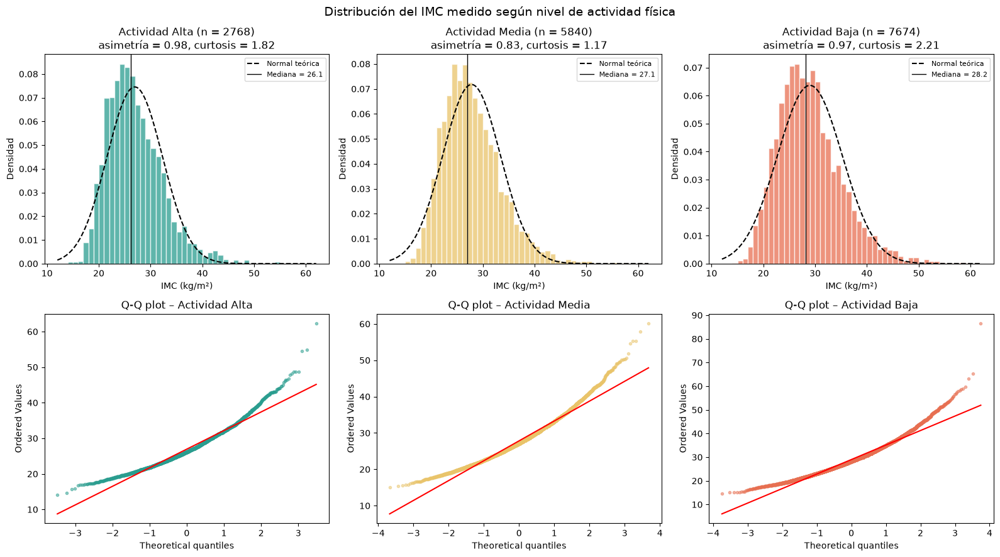

In [75]:
bins = np.arange(12, 62, 1)
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for i, g in enumerate(orden):
    x = df_h.loc[df_h['actividad'] == g, 'imc_bima']
    mu, sd = x.mean(), x.std()

    # Primeros graficos : histograma para observar normalidad de las variables
    ax = axes[0, i]
    ax.hist(x, bins=bins, density=True, color=colores[g], alpha=0.75, edgecolor='white')
    xs = np.linspace(12, 62, 300)
    ax.plot(xs, stats.norm.pdf(xs, mu, sd), 'k--', lw=1.5, label='Normal teórica')
    ax.axvline(x.median(), color='k', lw=1, label=f'Mediana = {x.median():.1f}')
    ax.set_title(f'Actividad {g} (n = {len(x)})\nasimetría = {stats.skew(x):.2f}, curtosis = {stats.kurtosis(x):.2f}')
    ax.set_xlabel('IMC (kg/m²)')
    ax.set_ylabel('Densidad')
    ax.legend(fontsize=8)

    # Segundos Graficos: QQ Plot para observar distribucion de normalidad
    stats.probplot(x, dist='norm', plot=axes[1, i])
    axes[1, i].get_lines()[0].set(markerfacecolor=colores[g], markeredgecolor=colores[g], markersize=3, alpha=0.5)
    axes[1, i].set_title(f'Q-Q plot – Actividad {g}')

plt.suptitle('Distribución del IMC medido según nivel de actividad física', fontsize=14)
plt.tight_layout()
plt.show()

En los tres grupos el pico queda a la izquierda de la normal teórica y hay una cola larga hacia los IMC altos. La asimetría está cerca de 1 y la curtosis es mayor que 0, así que las colas son más pesadas que las de una normal. En los QQ-plots los puntos no siguen la recta: forman una curva y se separan en los dos extremos. A ojo, el IMC no es normal en ningún grupo. Lo confirmamos con un test.

#### 3.2.3.1 Normalidad (Kolmogorov-Smirnov)

- H0: el IMC del grupo sigue una distribución normal.
- H1: el IMC del grupo no sigue una distribución normal.

Comparamos cada grupo con una normal que tiene su misma media y su mismo desvío. El estadístico D es la mayor distancia entre la distribución acumulada de los datos y la de esa normal.

In [76]:
filas = []
for g in orden:
    x = df_h.loc[df_h['actividad'] == g, 'imc_bima'].values
    D, p_ks = stats.kstest(x, stats.norm(x.mean(), x.std(ddof=1)).cdf)
    filas.append({'Actividad': g, 'n': len(x), 'Estadístico D': round(D, 4),
                  'p-valor': f'{p_ks:.2e}', '¿Normal? (α=0.05)': 'Sí' if p_ks > 0.05 else 'No'})
normalidad = pd.DataFrame(filas).set_index('Actividad')
normalidad

,n,Estadístico D,p-valor,¿Normal? (α=0.05)
Actividad,,,,
Alta,2768,0.0682,1.18e-11,No
Media,5840,0.0590,4.02e-18,No
Baja,7674,0.0651,9.44e-29,No


En los tres grupos el p-valor es mucho menor a 0,05 (D entre 0,059 y 0,068), así que rechazamos H0: el IMC no es normal en ningún nivel de actividad. Con muestras tan grandes el test detecta hasta diferencias chicas, pero acá la asimetría también se ve en los gráficos, así que la conclusión es firme. No se cumple el supuesto de normalidad.

#### 3.2.3.2 Homocedasticidad (Levene con la mediana)

- H0: las varianzas del IMC son iguales en los tres niveles de actividad.
- H1: al menos una varianza es distinta.

Usamos la versión de Levene que centra en la mediana (Brown-Forsythe), porque funciona mejor cuando los datos no son normales.

In [77]:
grupos = [df_h.loc[df_h['actividad'] == g, 'imc_bima'] for g in orden]

print('Varianza del IMC por grupo:')
print(df_h.groupby('actividad')['imc_bima'].var().loc[orden].round(2))

W, p_lev = stats.levene(*grupos, center='median')
print(f"\nLevene (mediana): W = {W:.2f}, p-valor = {p_lev:.2e}")
print('¿Varianzas iguales? (α=0.05):', 'Sí' if p_lev > 0.05 else 'No')

Varianza del IMC por grupo:
actividad
Alta     28.65
Media    30.91
Baja     39.26
Name: imc_bima, dtype: float64

Levene (mediana): W = 43.75, p-valor = 1.12e-19
¿Varianzas iguales? (α=0.05): No


El p-valor es mucho menor a 0,05 (W = 43,75), así que rechazamos H0: las varianzas no son iguales. La varianza crece a medida que baja la actividad (28,7 en alta, 30,9 en media y 39,3 en baja). Tampoco se cumple el supuesto de homocedasticidad.

### 3.2.4 Test de Kruskal-Wallis

Como no se cumple ninguno de los dos supuestos, no corresponde usar el ANOVA clásico. Como vimos en clase, para comparar más de dos grupos independientes sin poder asumir normalidad, la alternativa no paramétrica es Kruskal-Wallis.

- H0: la distribución del IMC es la misma en los tres niveles de actividad.
- H1: en al menos un nivel de actividad el IMC tiende a tomar valores distintos.

Además del p-valor calculamos el tamaño del efecto ε² (épsilon cuadrado), que mide qué tan grande es la diferencia. Hace falta porque con tantos casos casi cualquier diferencia sale significativa.

In [78]:
H, p_kw = stats.kruskal(*grupos)
gl = len(orden) - 1
eps2 = H / (len(df_h) - 1)

print(f"Kruskal-Wallis: H = {H:.2f}, gl = {gl}, p-valor = {p_kw:.2e}")
print(f"Tamaño de efecto: epsilon² = {eps2:.3f}")
print('¿Se rechaza H0? (α=0.05):', 'Sí' if p_kw < 0.05 else 'No')

Kruskal-Wallis: H = 271.83, gl = 2, p-valor = 9.38e-60
Tamaño de efecto: epsilon² = 0.017
¿Se rechaza H0? (α=0.05): Sí


El p-valor es prácticamente 0 (H = 271,83, p ≈ 9,4 × 10⁻⁶⁰), así que rechazamos H0: el IMC cambia según el nivel de actividad física. Pero ε² da 0,017: menos del 2% de la variación (en rangos) del IMC tiene que ver con la actividad. La diferencia es clara, pero chica, porque el IMC depende de muchas otras cosas.

In [79]:
# Chequeo: el ANOVA de Welch compara medias sin suponer varianzas iguales
from statsmodels.stats.oneway import anova_oneway

welch = anova_oneway(grupos, use_var='unequal', welch_correction=True)
print(f"ANOVA de Welch: F = {welch.statistic:.2f} | gl = ({welch.df_num:.0f}, {welch.df_denom:.0f}) | "
      f"p-valor = {welch.pvalue:.2e}")

ANOVA de Welch: F = 147.49 | gl = (2, 7846) | p-valor = 1.32e-63


Como chequeo, el ANOVA de Welch, que no pide varianzas iguales, llega a la misma conclusión (F = 147,5; p ≈ 1,3 × 10⁻⁶³).

### 3.2.5 Comparaciones de a pares (Mann-Whitney)

Kruskal-Wallis dice que al menos un grupo es distinto, pero no cuál. Para saberlo comparamos cada par de grupos con Mann-Whitney.

In [ ]:
filas = []
for a, b in combinations(orden, 2):
    xa = df_h.loc[df_h['actividad'] == a, 'imc_bima']
    xb = df_h.loc[df_h['actividad'] == b, 'imc_bima']
    U, p_ab = stats.mannwhitneyu(xa, xb)
    filas.append({'Comparación': f'{a} vs {b}',
                  'Mediana 1': round(xa.median(), 2), 'Mediana 2': round(xb.median(), 2),
                  'p-valor': p_ab})
pares = pd.DataFrame(filas).set_index('Comparación')
pares['¿Difieren? (α=0.05)'] = np.where(pares['p-valor'] < 0.05, 'Sí', 'No')
pares['p-valor'] = pares['p-valor'].map('{:.2e}'.format)
pares

,Mediana 1,Mediana 2,p-valor,¿Difieren? (α=0.05)
Comparación,,,,
Alta vs Media,26.15,27.06,3.45e-13,Sí
Alta vs Baja,26.15,28.23,7.72e-54,Sí
Media vs Baja,27.06,28.23,1.32e-25,Sí


Los tres pares dan p < 0,05, así que los tres niveles de actividad son distintos entre sí. El orden de las medianas es el esperado: alta (26,2) < media (27,1) < baja (28,2). A menor actividad física, mayor IMC.

La edad media es 39,8 años en actividad alta, 45,0 en media y 49,2 en baja, así que la edad podría explicar la diferencia de IMC. Pero al controlar por edad y sexo, el IMC sigue siendo 0,55 kg/m² más alto en actividad media y 1,44 kg/m² más alto en actividad baja que en alta (p < 0,001 en los dos casos). La diferencia no se debe solo a la edad.

### 3.2.6 Conclusión

- Rechazamos H0: el IMC medido cambia según el nivel de actividad física, y tiende a ser más alto cuanto menor es la actividad.
- Usamos Kruskal-Wallis y no ANOVA porque el IMC no es normal (Kolmogorov-Smirnov) y las varianzas no son iguales (Levene).
- El efecto es chico (ε² ≈ 0,02): con tantos casos la diferencia sale muy significativa, pero la actividad física explica una parte chica de la variación del IMC.
- Como las varianzas son distintas entre grupos, lo leemos como que con menos actividad el IMC tiende a tomar valores más altos, no estrictamente como una diferencia de medianas.
- Límites: es una asociación y no prueba causa, y la relación podría ir al revés (un IMC alto puede hacer que alguien se mueva menos). La edad se relaciona con el IMC y con la actividad, pero la diferencia se mantiene al controlarla (+0,55 y +1,44 kg/m²). No ponderamos: con el factor del paso 2 (`wf2p`) las medias son parecidas (26,7, 27,7 y 28,8).

## 3.3 Hipótesis multivariada

Existe una relación lineal entre el IMC, la presión sistólica y la edad, y la glucemia capilar en ayunas.

- H0: ninguna de las tres variables tiene relación lineal con la glucemia (β₁ = β₂ = β₃ = 0).
- H1: al menos una de las variables tiene relación lineal con la glucemia.

Lo probamos con una regresión lineal múltiple, con α = 0,05. El perímetro de cintura lo estudiamos en el PCA y en las correlaciones, pero no entra al modelo.

### 3.3.1 Datos

Usamos cinco variables: el IMC medido, la presión sistólica promedio, el perímetro de cintura, la edad y la glucemia, y les ponemos nombres cortos para que el código sea más fácil de leer. Sacamos a las personas con diagnóstico de diabetes, porque la enfermedad y su tratamiento les cambian la glucemia y taparían la relación que buscamos. También sacamos a las 24 que no saben o no contestan si tienen diabetes. Quedan 4.286 casos con todas las variables.

In [82]:
nombres = {
    "imc_bima": "imc",
    "promedio_sistolica": "sistolica",
    "bima13": "cintura",
    "bhch04": "edad",
    "bimq05": "glucemia",
}
etiquetas = {
    "imc": "IMC medido (kg/m²)",
    "sistolica": "Presión sistólica (mm Hg)",
    "cintura": "Perímetro de cintura (cm)",
    "edad": "Edad (años)",
    "glucemia": "Glucemia capilar (mg/dl)",
}
objetivo = "glucemia"
predictoras = [col for col in etiquetas if col != objetivo]

df_hip = raw_data[list(nombres) + ["bidi01"]].dropna(subset=list(nombres))
# bidi01: 1 = tiene diabetes, 2 = no tiene, 99 = Ns/Nc. Nos quedamos solo con los que no tienen
df_hip = df_hip[df_hip["bidi01"] == 2].drop(columns="bidi01").rename(columns=nombres)
print(f"Casos: {len(df_hip)}")
df_hip.describe()


Casos: 4286


,imc,sistolica,cintura,edad,glucemia
count,4286.000000,4286.000000,4286.000000,4286.000000,4286.000000
mean,27.839043,128.874008,91.148857,44.922305,76.916006
std,5.743654,20.469199,15.870884,17.762593,23.376397
min,15.820000,67.000000,49.000000,18.000000,20.000000
25%,23.740000,114.500000,80.000000,30.000000,64.000000
50%,27.050000,125.500000,91.000000,42.000000,78.000000
75%,30.990000,140.000000,101.000000,58.000000,89.000000
max,65.310000,245.000000,209.000000,97.000000,382.000000


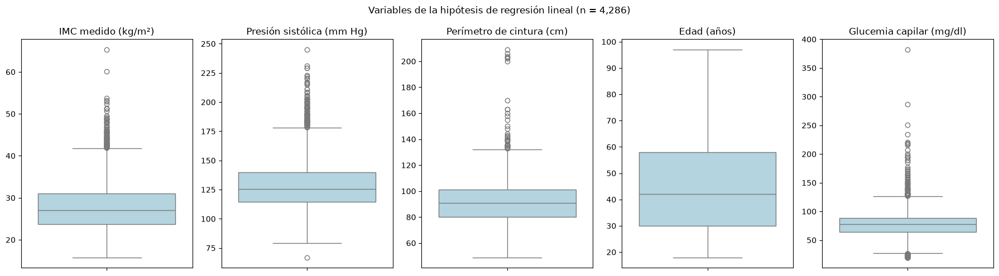

In [83]:
fig, axes = plt.subplots(1, len(etiquetas), figsize=(18, 5))
for ax, (col, desc) in zip(axes, etiquetas.items()):
    sns.boxplot(y=df_hip[col], ax=ax, color="lightblue")
    ax.set_title(desc)
    ax.set_ylabel("")
fig.suptitle(f"Variables de la hipótesis de regresión lineal (n = {len(df_hip):,})")
plt.tight_layout()
plt.show()


La glucemia es muy asimétrica: la mediana es 78 mg/dl, pero hay valores que llegan a 382. Las predictoras también tienen algunos valores muy altos, por ejemplo cinturas de más de 200 cm.

Además, 240 de los 4.286 casos (5,6%) tienen glucemia menor a 40 mg/dl, un valor muy bajo en ayunas que podría ser error de medición. No los sacamos porque no podemos confirmarlo.

### 3.3.2 Atípicos extremos

Sacamos solo los atípicos extremos de las predictoras: los que quedan a más de 3 veces el rango intercuartílico (IQR) de la caja. No usamos el 1,5 × IQR del boxplot porque dejaba afuera 218 casos, casi todos personas con presión alta u obesidad, que son justamente casos que nos interesan.

In [84]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [85]:
# Identificación de atípicos extremos (outliers) según el criterio del rango intercuartílico (IQR)

q1 = df_hip[predictoras].quantile(0.25)
q3 = df_hip[predictoras].quantile(0.75)
iqr = q3 - q1
atipico = (df_hip[predictoras] < q1 - 3 * iqr) | (df_hip[predictoras] > q3 + 3 * iqr)

print(atipico.sum())
print(f"Filas con al menos un atípico extremo: {atipico.any(axis=1).sum()} de {len(df_hip)}")
df_hip = df_hip[~atipico.any(axis=1)]


imc          5
sistolica    9
cintura      7
edad         0
dtype: int64
Filas con al menos un atípico extremo: 21 de 4286


De los 4.286 casos se van 21 y quedan 4.265.

### 3.3.3 PCA

El IMC y la cintura miden casi lo mismo, así que antes del modelo usamos PCA para ver cuánta información comparten las predictoras. Las estandarizamos primero, porque están en unidades muy distintas y si no, la que tiene números más grandes se llevaría toda la varianza.

In [86]:
#Estandarizamos las variables predictoras para el PCA

X = StandardScaler().fit_transform(df_hip[predictoras])

# Aplicamos PCA

pca = PCA()
componentes = pca.fit_transform(X)
nombres_pc = [f"PC{i + 1}" for i in range(pca.n_components_)]

varianza = pd.DataFrame({
    "Varianza explicada (%)": pca.explained_variance_ratio_ * 100,
    "Acumulada (%)": pca.explained_variance_ratio_.cumsum() * 100,
}, index=nombres_pc)
varianza.round(1)


,Varianza explicada (%),Acumulada (%)
PC1,57.2,57.2
PC2,24.7,81.9
PC3,13.7,95.5
PC4,4.5,100.0


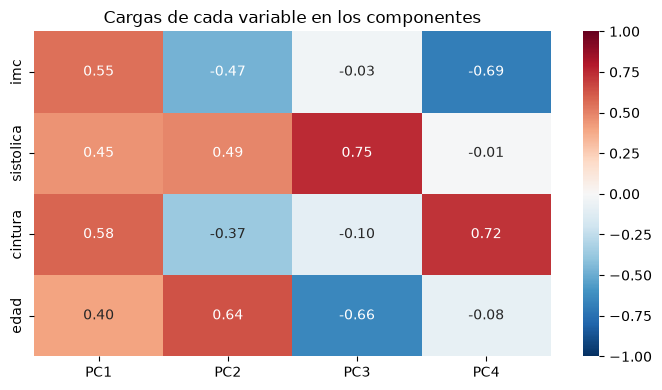

In [87]:
# Nos quedamos con las dos primeras componentes principales (PC1 y PC2) que explican más del 80% de la varianza total

cargas = pd.DataFrame(pca.components_.T, index=predictoras, columns=nombres_pc)

fig, ax = plt.subplots(figsize=(7, 4))
sns.heatmap(cargas, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Cargas de cada variable en los componentes")
plt.tight_layout()
plt.show()


Las dos primeras componentes juntan el 81,9% de la varianza (57,2% y 24,7%). En la PC1 las cuatro variables pesan parecido y para el mismo lado. La PC2 pone de un lado a la edad y la presión y del otro al IMC y la cintura: separa a las personas mayores de las más "corpulentas".

### 3.3.4 Correlaciones y t-SNE

Ahora miramos cuánto se relaciona cada variable con la glucemia, y si las personas con perfiles parecidos tienen glucemias parecidas.

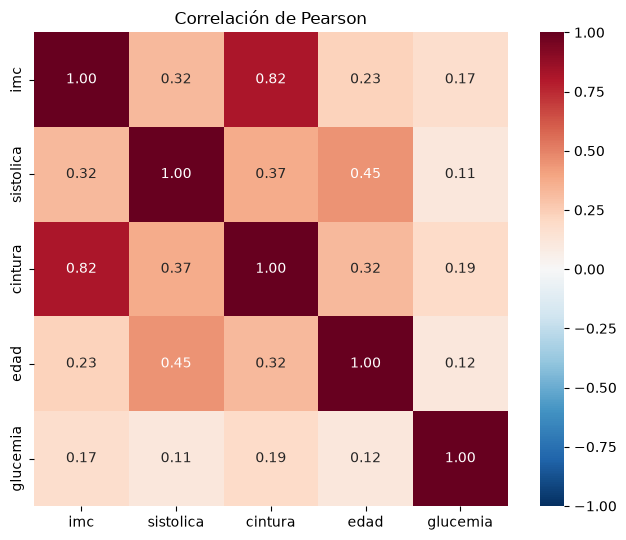

In [88]:
# Correlación de Pearson entre todas las variables de la hipótesis.
# Mide qué tan lineal es la relación entre cada par: cerca de 1 o -1 es fuerte, cerca de 0 es débil.

fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(df_hip.corr(method="pearson"), annot=True, fmt=".2f", cmap="RdBu_r",
            center=0, vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title("Correlación de Pearson")
plt.tight_layout()
plt.show()

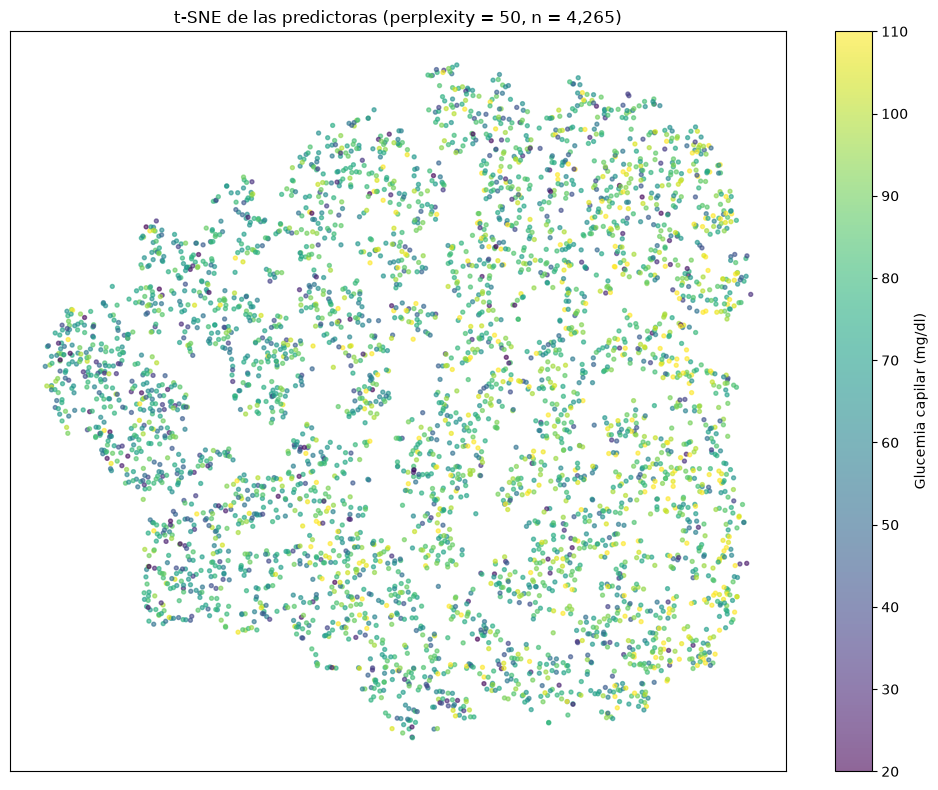

In [89]:
# t-SNE: proyecta las 4 predictoras estandarizadas en 2 dimensiones.
# Cada punto se colorea por su glucemia para ver si los perfiles parecidos tienen glucemias parecidas.

from sklearn.manifold import TSNE

# Lo habitual es una perplexity entre 5 y 50
perplexity = 50
tsne = TSNE(n_components=2, perplexity=perplexity, random_state=42)
embedding = tsne.fit_transform(X)

fig, ax = plt.subplots(figsize=(10, 8))
puntos = ax.scatter(embedding[:, 0], embedding[:, 1], c=df_hip[objetivo], cmap="viridis",
                    vmax=df_hip[objetivo].quantile(0.95), s=8, alpha=0.6)
fig.colorbar(puntos, ax=ax, label=etiquetas[objetivo])
ax.set_title(f"t-SNE de las predictoras (perplexity = {perplexity}, n = {len(df_hip):,})")
ax.set_xticks([])
ax.set_yticks([])
plt.tight_layout()
plt.show()

Las correlaciones con la glucemia son todas positivas pero débiles: van de 0,11 (presión sistólica) a 0,19 (cintura). La correlación más alta entre predictoras es la del IMC con la cintura (0,82). En el t-SNE las personas forman una sola nube, sin grupos separados, y los colores de la glucemia están mezclados en toda la nube: perfiles parecidos no tienen necesariamente glucemias parecidas.

### 3.3.5 Regresión lineal múltiple

Dejamos afuera la cintura porque mide casi lo mismo que el IMC (correlación de 0,82 y VIF ≈ 3 en las dos: no llegan al límite de 5 que usamos en 2.3, pero con las dos juntas no se puede separar el efecto de cada una). Más abajo lo comprobamos ajustando el modelo con las cuatro variables. El modelo principal queda con IMC, presión sistólica y edad:

- Test F (global): H0: β₁ = β₂ = β₃ = 0, es decir, ninguna variable explica la glucemia.
- Test t (cada coeficiente): H0: βⱼ = 0 para esa variable, controlando por las otras.

In [90]:
# Regresión lineal múltiple: glucemia explicada por IMC, presión sistólica y edad.
# El summary muestra el test F global (H0: todos los β = 0), el test t de cada coeficiente y el R².

import statsmodels.api as sm

# La cintura queda afuera porque tiene una correlación de 0,82 con el IMC y mide casi lo mismo
predictoras_modelo = [col for col in predictoras if col != "cintura"]

modelo = sm.OLS(df_hip[objetivo], sm.add_constant(df_hip[predictoras_modelo])).fit()
print(modelo.summary())

                            OLS Regression Results                            
Dep. Variable:               glucemia   R-squared:                       0.037
Model:                            OLS   Adj. R-squared:                  0.036
Method:                 Least Squares   F-statistic:                     54.45
Date:                Mon, 09 Nov 2026   Prob (F-statistic):           1.57e-34
Time:                        17:20:14   Log-Likelihood:                -19415.
No. Observations:                4265   AIC:                         3.884e+04
Df Residuals:                    4261   BIC:                         3.886e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         50.5842      2.533     19.973      0.0

Rechazamos H0 en el test F (F = 54,45, p ≈ 1,6 × 10⁻³⁴): hay relación lineal. Las tres variables son significativas:

- IMC: la glucemia sube 0,60 mg/dl por cada kg/m² (p < 0,001).
- Edad: sube 0,087 mg/dl por año (p < 0,001).
- Presión sistólica: sube 0,045 mg/dl por mm Hg (p = 0,027). Es el resultado más frágil, ver abajo.

Pero el R² es 0,037: el modelo explica menos del 4% de la variación de la glucemia.

#### 3.3.5.1 Modelo con la cintura

In [91]:
# Modelo con las cuatro variables, para ver qué pasa al dejar la cintura junto con el IMC
X4 = sm.add_constant(df_hip[predictoras])
modelo_4 = sm.OLS(df_hip[objetivo], X4).fit()
vif_4 = pd.Series([variance_inflation_factor(X4.values, i) for i in range(1, X4.shape[1])],
                  index=predictoras, name="VIF")
print(vif_4.round(2))
print(f"\nModelo con las 4 variables: F = {modelo_4.fvalue:.2f} | p-valor = {modelo_4.f_pvalue:.2e} | "
      f"R² = {modelo_4.rsquared:.3f}")
print(modelo_4.pvalues.round(3))

imc          3.02
sistolica    1.36
cintura      3.22
edad         1.30
Name: VIF, dtype: float64

Modelo con las 4 variables: F = 47.03 | p-valor = 9.74e-39 | R² = 0.042
const        0.000
imc          0.094
sistolica    0.102
cintura      0.000
edad         0.003
dtype: float64


Con las cuatro variables el test F también rechaza H0 (F = 47,0; p ≈ 9,7 × 10⁻³⁹; R² = 0,042). Los VIF de IMC y cintura son 3,0 y 3,2. Con las dos juntas la cintura es significativa (p < 0,001), pero el IMC (p = 0,094) y la presión sistólica (p = 0,102) dejan de serlo. Como el IMC y la cintura se reparten la misma información, nos quedamos con el modelo de tres variables.

Como vimos en clase con el ejemplo de ventas y publicidad, después de ajustar el modelo hay que revisar sus supuestos con los residuos.

#### 3.3.5.2 Normalidad de los residuos

- H0: los residuos son normales.
- H1: los residuos no son normales.

Shapiro-Wilk: W = 0.9270 | p-valor = 1.98e-41
Se rechaza normalidad (α = 0.05)


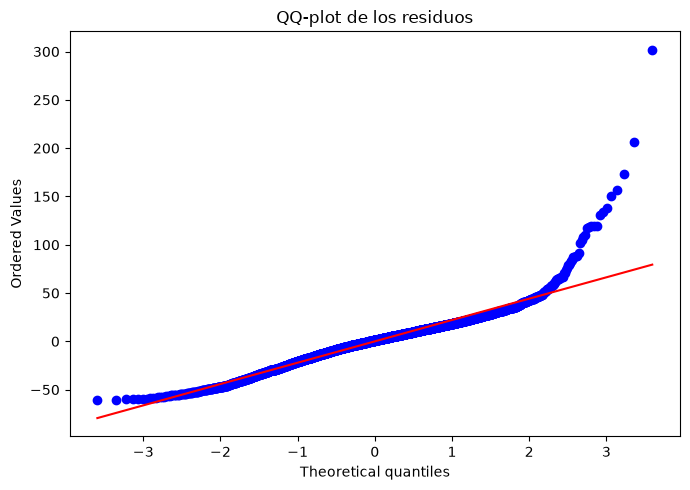

In [92]:
# Shapiro-Wilk sobre los residuos (H0: los residuos son normales).
# El QQ-plot muestra en qué parte de la distribución se aleja de la normal.

residuos = modelo.resid
w_res, p_res = stats.shapiro(residuos)
print(f"Shapiro-Wilk: W = {w_res:.4f} | p-valor = {p_res:.3g}")
print("Se rechaza normalidad" if p_res < 0.05 else "No se rechaza normalidad", "(α = 0.05)")

fig, ax = plt.subplots(figsize=(7, 5))
stats.probplot(residuos, dist="norm", plot=ax)
ax.set_title("QQ-plot de los residuos")
plt.tight_layout()
plt.show()

Shapiro-Wilk rechaza la normalidad (W = 0,927, p < 0,001). El QQ-plot muestra que el problema está en la cola de arriba: hay personas con la glucemia mucho más alta de lo que predice el modelo.

#### 3.3.5.3 Homocedasticidad

Graficamos los residuos contra la glucemia predicha. Si la varianza es constante, los puntos forman una banda pareja alrededor de 0, sin forma de embudo.

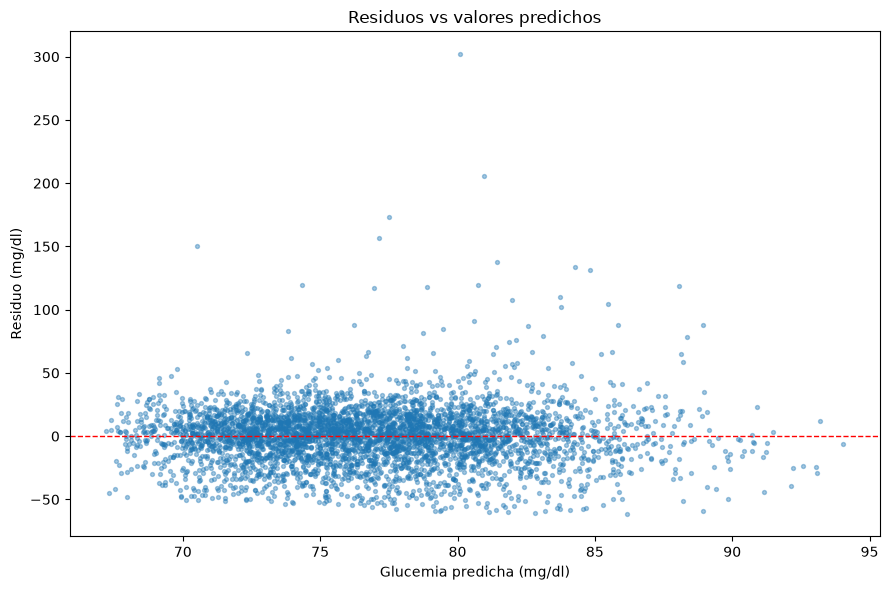

In [93]:
# Residuos contra glucemia predicha, para revisar homocedasticidad.
# Si la varianza es constante, los puntos forman una banda pareja alrededor de 0, sin forma de embudo.

fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(modelo.fittedvalues, residuos, s=8, alpha=0.4)
ax.axhline(0, color="red", ls="--", lw=1)
ax.set_xlabel("Glucemia predicha (mg/dl)")
ax.set_ylabel("Residuo (mg/dl)")
ax.set_title("Residuos vs valores predichos")
plt.tight_layout()
plt.show()

In [94]:
from statsmodels.stats.diagnostic import het_breuschpagan

lm, p_bp, _, _ = het_breuschpagan(modelo.resid, modelo.model.exog)
print(f"Breusch-Pagan: LM = {lm:.2f} | p-valor = {p_bp:.2e}")

# Errores estándar robustos (HC3), que no suponen varianza constante
modelo_robusto = sm.OLS(df_hip[objetivo], sm.add_constant(df_hip[predictoras_modelo])).fit(cov_type="HC3")
display(pd.DataFrame({"coef": modelo_robusto.params, "IC 95% inf": modelo_robusto.conf_int()[0],
                      "IC 95% sup": modelo_robusto.conf_int()[1], "p-valor": modelo_robusto.pvalues}).round(4))

# Chequeo con el factor de ponderación del paso 3 (wf3p), normalizado a media 1
pesos_3 = raw_data.loc[df_hip.index, "wf3p"]
modelo_pond = sm.WLS(df_hip[objetivo], sm.add_constant(df_hip[predictoras_modelo]),
                     weights=pesos_3 / pesos_3.mean()).fit(cov_type="HC3")
display(pd.DataFrame({"coef": modelo_pond.params, "p-valor": modelo_pond.pvalues}).round(4))

Breusch-Pagan: LM = 26.79 | p-valor = 6.50e-06


,coef,IC 95% inf,IC 95% sup,p-valor
const,50.5842,45.2317,55.9368,0.0000
imc,0.5983,0.4633,0.7333,0.0000
sistolica,0.0451,0.0023,0.0879,0.0390
edad,0.0870,0.0430,0.1309,0.0001


,coef,p-valor
const,48.1006,0.0000
imc,0.5643,0.0001
sistolica,0.0512,0.2459
edad,0.1292,0.0049


La banda se ve bastante pareja, pero el test de Breusch-Pagan rechaza la varianza constante (p ≈ 6,5 × 10⁻⁶), así que hay algo de heterocedasticidad. Por eso calculamos errores estándar robustos (HC3): el IMC y la edad siguen siendo significativos (p < 0,001) y la presión sistólica queda justo en el límite (p = 0,039). Con los pesos `wf3p`, el IMC (p < 0,001) y la edad (p = 0,005) se mantienen, y la presión sistólica deja de ser significativa (p = 0,25). Además se ven residuos positivos muy grandes: es la misma cola que detectó Shapiro-Wilk.

### 3.3.6 Conclusión

Rechazamos H0 (F = 54,45; p < 0,001): el IMC y la edad tienen una relación lineal significativa con la glucemia capilar, y se mantiene con errores robustos y con pesos. La presión sistólica es el resultado más débil: es significativa en el modelo principal (p = 0,027) y con errores robustos (p = 0,039), pero deja de serlo al agregar la cintura (p = 0,10) o al ponderar con `wf3p` (p = 0,25). Además la relación es débil: el modelo explica solo el 3,7% de la variación de la glucemia, que depende sobre todo de cosas que no están en el modelo, como el metabolismo, la genética o el momento de la medición.

Algunas aclaraciones:

- La cintura quedó afuera del modelo porque mide casi lo mismo que el IMC (VIF ≈ 3). Si se dejan las dos, la cintura sale significativa y el IMC no (p = 0,094): las dos se reparten la misma información, así que no se puede separar el efecto de cada una.
- Ayuno: la base no trae las horas de ayuno, pero el cuestionario del paso 3 indica que si pasaron menos de 8 horas desde la última comida se termina la entrevista y se pauta una revisita. Suponemos entonces que las mediciones son en ayunas.
- Los residuos no son normales (hay una cola de glucemias altas) y su varianza no es constante (Breusch-Pagan, p ≈ 6,5 × 10⁻⁶). Con 4.265 casos el test t sigue siendo razonable, pero usamos errores robustos como chequeo. Esa cola muestra que hay personas que el modelo no logra explicar.